# Who uses AI at work? Lead scoring for a vendor of AI coding tools

**Team:** Claudio Bendinelli · Ludovica De Martino · Cormac O'Sullivan

Université Paris-Saclay · M1 Hands-on Machine Learning 2026-27 · Final project

## Contents

0. Setup
1. Introduction
2. Preprocessing
3. Training
4. Evaluation
5. Conclusion

Running the whole notebook takes around 30 minutes on a laptop. The first time, it also downloads about 140 MB of data.

**Requirements:** Python 3 and scikit-learn 1.6 or newer (we used 1.6.1), plus pandas, NumPy, SciPy, Matplotlib and seaborn.

## 0. Setup

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import loguniform

from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_val_score,
                                     learning_curve, train_test_split, validation_curve)
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

In [2]:
%config InlineBackend.figure_format="retina"

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)

scikit-learn: 1.6.1
pandas: 2.2.3


Some constants we use everywhere in the notebook.

In [3]:
RANDOM_STATE = 42
DATA_DIR = Path("data")
TARGET = "AISelect"
CLASS_ORDER = ["Daily", "Occasional", "No"]
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # one colour per class, same order as CLASS_ORDER
CV = 5                                            # number of folds for cross-validation

### Data

We work with the public **Stack Overflow Developer Survey 2025** (https://survey.stackoverflow.co/). There are two files: `results.csv`, with one row per respondent (about 141 MB), and `schema.csv`, which contains the text of each question. Both come from https://github.com/StackExchange/Survey/tree/main/packages/archive/2025.

The data is under the Open Database License (ODbL) 1.0, which is why we cite the source. The survey is anonymous: there are no names, e-mails or IP addresses. We don't include the data in our submission; the next cell downloads it the first time you run the notebook.

In [4]:
BASE_URL = "https://media.githubusercontent.com/media/StackExchange/Survey/main/packages/archive/2025/"
DATA_DIR.mkdir(exist_ok=True)

for name in ["results.csv", "schema.csv"]:
    if not (DATA_DIR / name).exists():
        print("Downloading", name, "...")
        urlretrieve(BASE_URL + name, DATA_DIR / name)

In [5]:
df = pd.read_csv(DATA_DIR / "results.csv", low_memory=False)
schema = pd.read_csv(DATA_DIR / "schema.csv")

print("df:", df.shape)
print("schema:", schema.shape)

df: (49191, 172)
schema: (139, 6)


## 1. Introduction

### The task
Imagine a company that sells an AI coding assistant. Its sales team has a list of thousands of developers, and they can't call everyone at once, so they need to know **who to contact first**.

Our model predicts how much a developer uses AI tools, with 3 classes: **Daily**, **Occasional** and **No**. Our idea is that the Occasional users are the best people to call: they already know these tools, but they probably haven't committed to a competitor yet. Daily users most likely already pay for another product, and most people in the No class don't plan to use AI tools at all (we check this in section 2.5).

For each contact the model gives 3 probabilities. The sales team can then call first the people with the highest P(Occasional), and leave for the end those with the highest P(No). In section 4.3 we also try a two-step version: first remove the probable non-users, then sort the rest. In any case the model only helps to sort the list; the final decision stays with a person.

### Which features?
The company has no way to know who uses AI without asking each developer. So we only keep information that could be found **without asking**, on a public profile or a CV: role, experience, education, country, company size, industry, remote work and the technologies used. We don't use opinions, private behaviour or personal data like age, and the other questions about AI would give the answer away (this is leakage, see section 2.3).

### Existing work
| Work | Task | Model | Metric | Score |
|---|---|---|---|---|
| Stack Overflow, 2025 survey report | Descriptive (charts) | — | — | — |
| meheduz, GitHub study of the 2023–2025 surveys | Descriptive + statistical tests | — | Share of AI users | 44% (2023) → 62% (2024) → 78.5% (2025) |
| janellelalon, DEV Community (2026) | Uses AI or not (2 classes) | Random forest | Accuracy | 94%, but no baseline, no cross-validation, and nothing says whether the AI questions were excluded |
| Kaggle, *AI Productivity Prediction* (2025 survey) | Another AI-related target | — | — | Not comparable |

We also looked on Kaggle and Codabench for other solutions that predict AI use from this survey, but we didn't find any with a reported score. This is one more reason why we think our angle is new.

The 94% looked suspicious to us. Since 78.5% of the respondents use AI, a model that always answers "yes" already gets 78.5% accuracy, so going up to 94% needs very strong features. Our guess is that the AI questions were left in the data; we test this in section 3.9.

What we do differently: 3 classes that make sense for a business use, only features a company could actually observe (with a check for leakage), and a proper evaluation with baselines, cross-validation and confidence intervals.

### Framing
This is a supervised multiclass classification problem (3 classes), with batch learning. We also add a small unsupervised part, where we group developers by the technologies they use (section 3.10).

### Metrics
To compare and tune the models we use **macro-F1**, so that each of the 3 classes counts the same. Accuracy would not work well here: always predicting "Daily" already gives 47%.

For the business side we look, on the test set only, at **precision@k** (among the first k% of the sorted list, how many really are Occasional, or No) and at the **ROC AUC**.

To be honest, macro-F1 is not exactly what the company wants: what matters for them is how well the Occasional users are ranked. We still use it to choose the models because it is simple and takes all 3 classes into account. Tuning directly for the ranking is something we leave for future work.

The minimum to beat is always predicting the most frequent class, and a simple rule a salesperson could write by hand (section 2.6). We also didn't fix a minimum performance needed by the business (for example "at least X% of Occasional users in the first calls"). because we didn't have a real company to ask, so we only require the model to beat the two baselines; this is a limit of our framing.

### Research questions
| | Question | Section |
|---|---|---|
| Q1 | Is a public profile enough to predict AI use? | 3.2 and 4 |
| Q2 | How much is the information the vendor does not have worth? | 3.9 |
| Q3 | Which types of developers exist? | 3.10 |

### Assumptions
| | Assumption | Status |
|---|---|---|
| H1 | Survey answers are close to what a public profile shows | Not verifiable: limitation |
| H2 | Stack Overflow respondents represent developers | Not verifiable |
| H3 | People who did not answer the AI question are similar to the others | Checked in 2.6 |
| H4 | Grouping 5 answers into 3 classes keeps the useful information | Checked in 2.5 |

## 2. Preprocessing

We start with a quick look at the file. Then we put the test set aside (2.2), and only after that do we look for leakage (2.3). From that point on, all the statistics are computed on the training set only. The only exception is the leakage check, which also uses the rows without a target, but those are never part of the test set anyway.

### 2.1 First look

In [6]:
df.head(3).T

,0,1,2
ResponseId,1,2,3
MainBranch,I am a developer by profession,I am a developer by profession,I am a developer by profession
Age,25-34 years old,25-34 years old,35-44 years old
EdLevel,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Associate degree (A.A., A.S., etc.)","Bachelor’s degree (B.A., B.S., B.Eng., etc.)"
Employment,Employed,Employed,"Independent contractor, freelancer, or self-em..."
...,...,...,...
AIAgentExtWrite,NaN,NaN,NaN
AIHuman,When I don’t trust AI’s answers,When I don’t trust AI’s answers;When I want to...,When I don’t trust AI’s answers;When I want to...
AIOpen,"Troubleshooting, profiling, debugging",All skills. AI is a flop.,"Understand how things actually work, problem s..."
ConvertedCompYearly,61256.0,104413.0,53061.0


In [7]:
df.dtypes.value_counts()

object     119
float64     52
int64        1
Name: count, dtype: int64

In [8]:
# Duplicated answers (ResponseId is different for every row, so we leave it out)
duplicated = df.drop(columns="ResponseId").duplicated()
print("Duplicated rows:", duplicated.sum())
print("Of these, rows with a target:", df.loc[duplicated, TARGET].notna().sum())
print("Median number of filled cells in these rows:",
      df.loc[duplicated].drop(columns="ResponseId").notna().sum(axis=1).median())

Duplicated rows: 1547
Of these, rows with a target: 0
Median number of filled cells in these rows: 2.0


In [9]:
missing_per_column = df.isna().sum()
print("Missing cells:", missing_per_column.sum(), "out of", df.size)
print("Columns with missing values:", (missing_per_column > 0).sum(), "out of", df.shape[1])
print("Missing values in the target:", missing_per_column[TARGET])

Missing cells: 4437549 out of 8460852
Columns with missing values: 169 out of 172
Missing values in the target: 15471


In [10]:
missing_pct = (missing_per_column / len(df) * 100).round(1)
missing_pct.sort_values(ascending=False).head(10)

AIAgentObsWrite         99.5
SOTagsWant Entry        99.1
SOTagsHaveEntry         99.1
AIModelsWantEntry       99.0
AIAgentOrchWrite        99.0
JobSatPoints_15_TEXT    98.7
AIAgentKnowWrite        98.4
AIModelsHaveEntry       98.4
SO_Actions_15_TEXT      98.3
AIAgentExtWrite         98.3
dtype: float64

A few things stand out:
- 119 of the 172 columns are text, mostly answers picked from a list. The 52 numeric columns are mostly positions in rankings.
- More than half of the cells are empty. The emptiest columns are the free-text "other" answers.
- The target `AISelect` is missing for 15,471 people (31.5%). We remove these rows in 2.2.
- There are 1,547 duplicated rows, but none of them has a target. They are almost empty (2 filled cells in the middle), probably people who left the survey right at the start. They disappear in 2.2 together with the other rows without a target, so we don't need to do anything else about them.

### 2.2 Target and train/test split

In [11]:
df[TARGET].value_counts(dropna=False)

AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64

The original question has 5 answers, which we group into 3 classes:

| Answer | Class |
|---|---|
| Yes, daily | **Daily** |
| Yes, weekly / Yes, monthly or less | **Occasional** |
| No, but I plan to soon / No, and I don't plan to | **No** |

People who did not answer are removed.

In [12]:
TARGET_CLASSES = {
    "Yes, I use AI tools daily": "Daily",
    "Yes, I use AI tools weekly": "Occasional",
    "Yes, I use AI tools monthly or infrequently": "Occasional",
    "No, but I plan to soon": "No",
    "No, and I don't plan to": "No",
}

labelled = df.dropna(subset=[TARGET])
y = labelled[TARGET].map(TARGET_CLASSES)

print("Rows with a target:", len(labelled))
print((y.value_counts(normalize=True) * 100).round(1))

Rows with a target: 33720
AISelect
Daily         47.1
Occasional    31.4
No            21.5
Name: proportion, dtype: float64


We keep 80% of the data for training and 20% for the test, stratified by class. We don't touch the test set until section 4.

(In our project proposal we reported a macro-F1 of 0.64. That quick test used all the columns, AI questions included; section 3.9 explains the gap.)

In [13]:
train_set, test_set, y_train, y_test = train_test_split(
    labelled, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", train_set.shape)
print("test:", test_set.shape)

train: (26976, 172)
test: (6744, 172)


### 2.3 Leakage

A feature is **leakage** when it basically gives away the target. Our target is the question "Do you currently use AI tools in your development process?", and the survey contains many other questions about AI that almost tell you the answer. A company wouldn't know these answers anyway.

**Method 1:** we take every column whose name starts with `AI`, plus 4 more that we found by reading the questions in `schema.csv`. One of them is less obvious: `LearnCode` ("How did you learn to code in the past year?") has "AI CodeGen tools or AI-enabled apps" among its options, ticked by about a third of the people, so it also gives the answer away.

In [14]:
leakage_by_name = [col for col in df.columns if col.startswith("AI") and col != TARGET]
leakage_by_question = ["LearnCodeAI", "AgentUsesGeneral", "SOFriction", "LearnCode"]
LEAKAGE_COLS = leakage_by_name + leakage_by_question

print("Found by name:", len(leakage_by_name))
print("Found by reading the questions:", len(leakage_by_question))

schema.loc[schema["qname"].isin(leakage_by_question), ["qname", "question"]]

Found by name: 41
Found by reading the questions: 4


,qname,question
56,LearnCode,How did you learn to code in the past year? Se...
57,LearnCodeAI,Did you spend time in the last year learning A...
115,SOFriction,"When you visit Stack Overflow, how often is it..."
126,AgentUsesGeneral,


**Method 2 (a double check):** the AI questions are at the end of the survey, so people who skipped the target almost never answered them. We look for columns where less than 0.5% of the answers come from people without a target, and check that they are all already in our list. This only uses *whether* the target is missing, not its value, and it doesn't touch the test set (we use the training set plus the rows without a target).

In [15]:
not_test = df.drop(index=test_set.index)        # training set + rows without a target
no_target = not_test[TARGET].isna()
share_without_target = not_test[no_target].notna().sum() / not_test.notna().sum() * 100

leakage_by_missing = [col for col in df.columns if share_without_target[col] < 0.5 and col != TARGET]
not_in_list = [col for col in leakage_by_missing if col not in LEAKAGE_COLS]

print("Columns found by method 2:", len(leakage_by_missing))
print("Not already in our list:", not_in_list)

Columns found by method 2: 37
Not already in our list: []


Method 2 doesn't find any new column, which is reassuring. The 45 leakage columns, all about AI, are dropped when we choose the features in 2.4.

### 2.4 Which features can the vendor observe?

We sort every remaining column into one of 3 groups:
- **observable**, i.e. something you could see on a profile or a CV: these are our features;
- **not observable** (opinions, wishes, salary, private behaviour): dropped;
- **ID or free text**: dropped, since we don't do any text processing in this project.

In [16]:
OBSERVABLE_COLS = ["MainBranch", "EdLevel", "Employment", "WorkExp", "YearsCode", "DevType", "OrgSize", "ICorPM",
                   "RemoteWork", "Industry", "Country", "LanguageHaveWorkedWith", "DatabaseHaveWorkedWith",
                   "PlatformHaveWorkedWith", "WebframeHaveWorkedWith", "OfficeStackAsyncHaveWorkedWith",
                   "OpSysProfessional use"]

other_cols = [col for col in df.columns if col not in LEAKAGE_COLS + OBSERVABLE_COLS + [TARGET]]
FREE_TEXT_COLS = ["ResponseId"] + [col for col in other_cols if col.endswith(("_TEXT", "Entry", "Entr"))]
NOT_OBSERVABLE_COLS = [col for col in other_cols if col not in FREE_TEXT_COLS]

print("Observable:", len(OBSERVABLE_COLS))
print("Not observable:", len(NOT_OBSERVABLE_COLS))
print("ID or free text:", len(FREE_TEXT_COLS))
print("Leakage:", len(LEAKAGE_COLS))

Observable: 17
Not observable: 88
ID or free text: 21
Leakage: 45


| Group | Columns | Why |
|---|---|---|
| Observable | role (`MainBranch`, `DevType`, `ICorPM`), experience and education (`WorkExp`, `YearsCode`, `EdLevel`), job (`Employment`, `OrgSize`, `Industry`, `Country`, `RemoteWork`), technologies used at work | On a profile, a CV or GitHub |
| Not observable | rankings, job satisfaction, "want to work with" / "admired", use of Stack Overflow, salary | Opinions, wishes or private information |
| Not observable | `Age` and the other personal questions (other activities, career change, purchases) | Not on a profile; choosing contacts by age is not ethical |
| ID / free text | `ResponseId`, write-in answers | Row number or free text |

We hesitated about `Country`. A vendor does organise its work by market, so it makes sense to keep it, but it is also close to nationality, which is a sensitive attribute. We keep it for now; in 3.6 we measure how much the model loses without it, and we come back to the ethical side in 4.5.

**Multiple-choice columns.** In some columns people could tick several options, which end up separated by `;` (for example "Python;SQL").

In [17]:
text_cols = [col for col in OBSERVABLE_COLS if train_set[col].dtype != "float64"]
NUMERIC_COLS = [col for col in OBSERVABLE_COLS if col not in text_cols]
MULTI_CHOICE_COLS = [col for col in text_cols if train_set[col].str.contains(";", na=False).any()]
SINGLE_CHOICE_COLS = [col for col in text_cols if col not in MULTI_CHOICE_COLS]

print("Numeric:", NUMERIC_COLS)
print("Multiple choice:", MULTI_CHOICE_COLS)
print("Single choice:", SINGLE_CHOICE_COLS)

Numeric: ['WorkExp', 'YearsCode']
Multiple choice: ['LanguageHaveWorkedWith', 'DatabaseHaveWorkedWith', 'PlatformHaveWorkedWith', 'WebframeHaveWorkedWith', 'OfficeStackAsyncHaveWorkedWith', 'OpSysProfessional use']
Single choice: ['MainBranch', 'EdLevel', 'Employment', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'Industry', 'Country']


In [18]:
# Number of different options in each multiple-choice column
for col in MULTI_CHOICE_COLS:
    options = train_set[col].str.get_dummies(sep=";").columns
    print(col, ":", len(options), "options")

LanguageHaveWorkedWith : 42 options


DatabaseHaveWorkedWith : 30 options


PlatformHaveWorkedWith : 42 options


WebframeHaveWorkedWith : 28 options


OfficeStackAsyncHaveWorkedWith : 25 options
OpSysProfessional use : 15 options


In [19]:
# Number of categories in each single-choice column
train_set[SINGLE_CHOICE_COLS].nunique().sort_values(ascending=False)

Country       175
DevType        32
Industry       15
OrgSize         9
EdLevel         8
MainBranch      6
Employment      6
RemoteWork      5
ICorPM          2
dtype: int64

**Is AI hiding in the observable columns?** To be safe, we search the answers for names of AI tools and for the word "AI".

In [20]:
AI_WORDS = r"Copilot|ChatGPT|Claude|Cursor|Gemini|Windsurf|\bAI\b"

for col in text_cols:
    if train_set[col].str.contains(AI_WORDS, na=False).any():
        print(col, "->", train_set.loc[train_set[col].str.contains(AI_WORDS, na=False), col].unique())

DevType -> ['Developer, AI apps or physical AI' 'AI/ML engineer']


Only `DevType` matches, with two job titles: "AI/ML engineer" and "Developer, AI apps or physical AI". These people *build* AI products, and that is written on their profile, so we decided to keep them. None of the technology columns contains an AI tool.

**Numeric columns.**

In [21]:
train_set[NUMERIC_COLS].describe()

,WorkExp,YearsCode
count,24906.000000,26628.000000
mean,14.039348,17.217966
std,10.855037,11.764548
min,1.000000,1.000000
25%,5.000000,8.000000
50%,11.000000,15.000000
75%,20.000000,25.000000
max,100.000000,100.000000


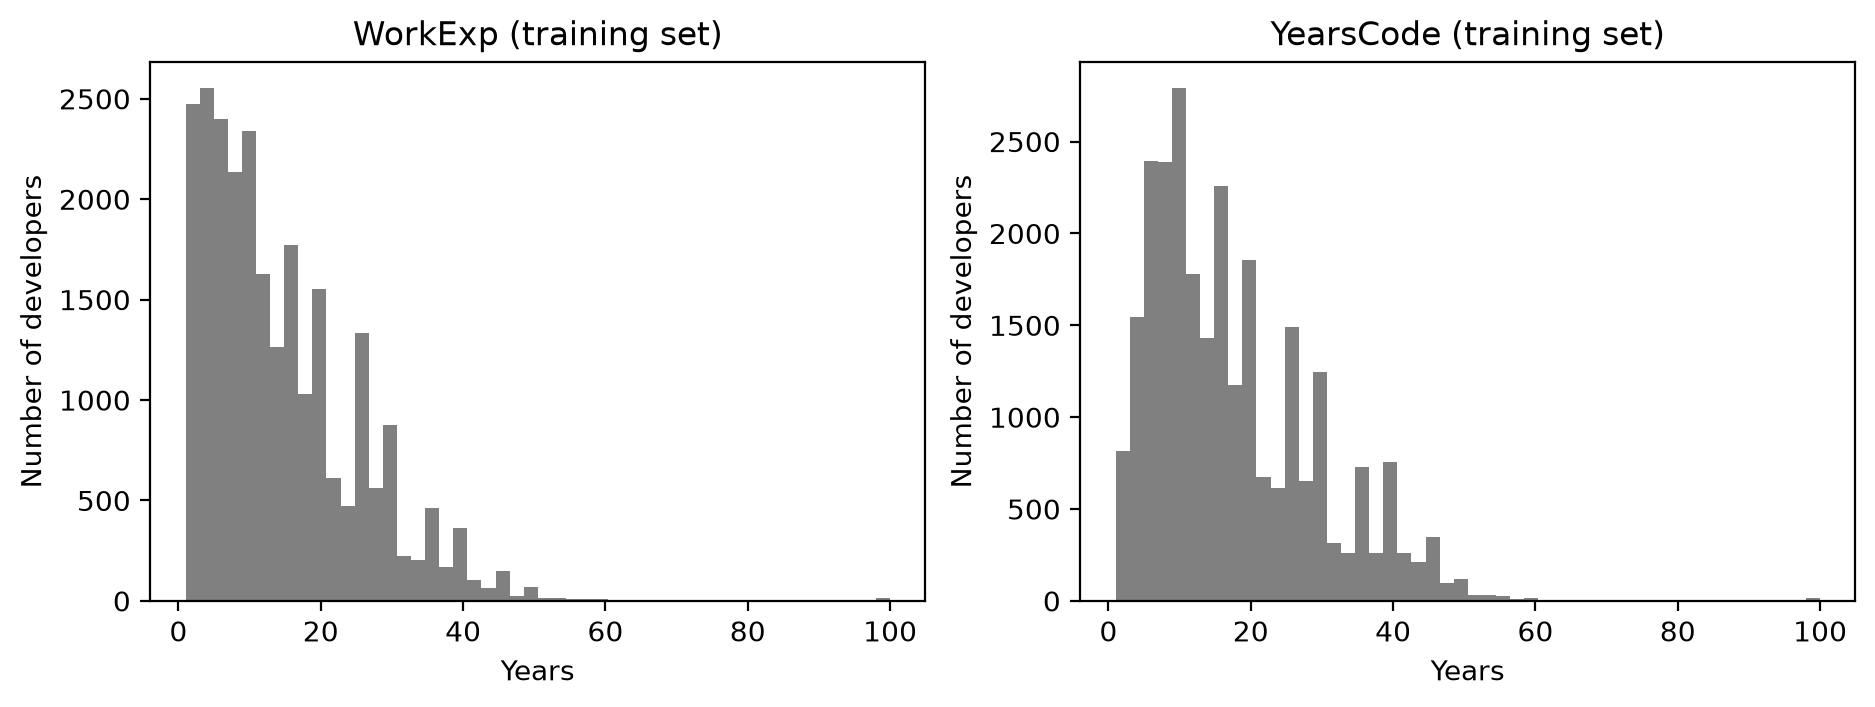

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, NUMERIC_COLS):
    ax.hist(train_set[col].dropna(), bins=50, color="grey")
    ax.set_title(col + " (training set)")
    ax.set_xlabel("Years")
    ax.set_ylabel("Number of developers")
plt.show()

In [23]:
print("Rows with WorkExp > YearsCode:", (train_set["WorkExp"] > train_set["YearsCode"]).sum())
print("Values above 60 years:", (train_set[NUMERIC_COLS] > 60).sum().sum())

Rows with WorkExp > YearsCode: 2127
Values above 60 years: 51


**Hidden missing values:** some answers look like real values but don't actually tell us anything.

In [24]:
print(train_set["Employment"].value_counts(dropna=False))
print()
print(train_set["OrgSize"].value_counts(dropna=False))

Employment
Employed                                                19161
Independent contractor, freelancer, or self-employed     3756
Student                                                  2227
Not employed                                             1175
Retired                                                   439
I prefer not to say                                       218
Name: count, dtype: int64

OrgSize
NaN                                                   5547
20 to 99 employees                                    4150
100 to 499 employees                                  3847
Less than 20 employees                                3464
10,000 or more employees                              3143
1,000 to 4,999 employees                              2691
500 to 999 employees                                  1521
Just me - I am a freelancer, sole proprietor, etc.    1061
5,000 to 9,999 employees                              1029
I don’t know                                       

What we learn from this:
- Both numeric columns are skewed to the right, and some values are impossible (up to 100 years of experience).
- `YearsCode` includes the years of study, so it should never be smaller than `WorkExp`. Yet it is, in 2,127 rows.
- "I prefer not to say" (Employment) and "I don’t know" (OrgSize) are really missing values in disguise.
- We have 6 multiple-choice columns (182 options in total) and 9 single-choice columns. Many options are ticked by very few people, and `Country` alone has 175 categories, many of them rare.

### 2.5 Target exploration (training set)

AISelect
Daily         47.1
Occasional    31.4
No            21.5
Name: count, dtype: float64


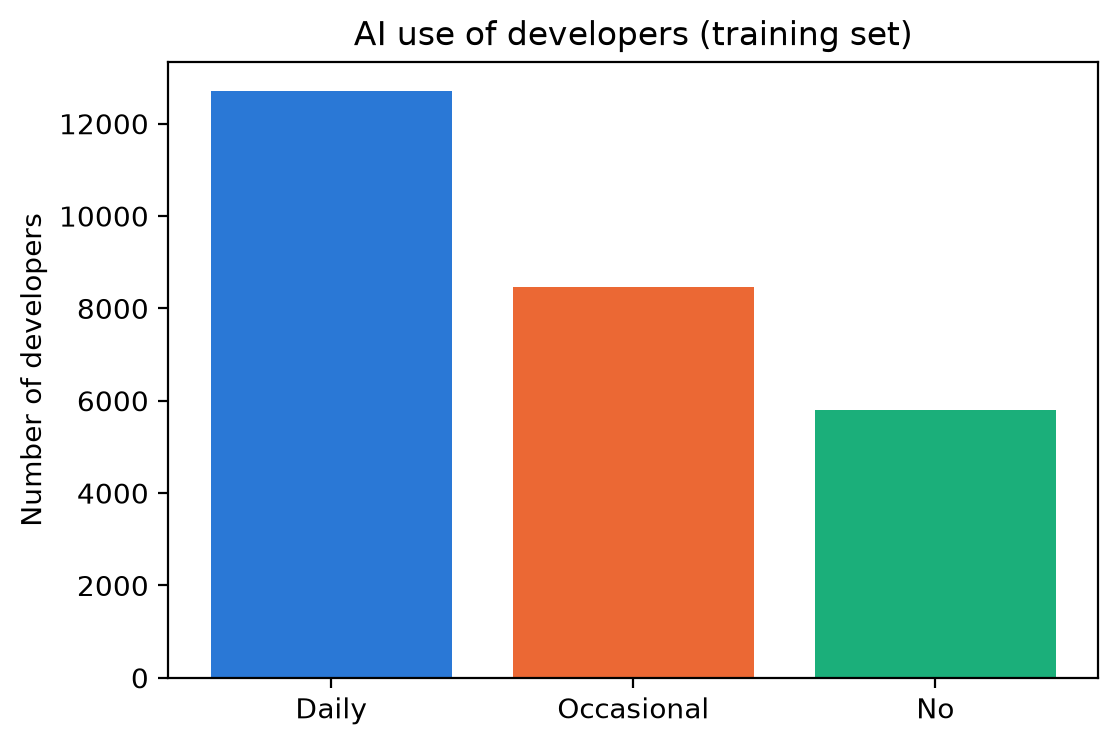

In [25]:
class_counts = y_train.value_counts()[CLASS_ORDER]
print((class_counts / len(y_train) * 100).round(1))

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index, class_counts.values, color=CLASS_COLORS)
plt.title("AI use of developers (training set)")
plt.ylabel("Number of developers")
plt.show()

**Inside the class "No" (H4).**

In [26]:
train_set.loc[y_train == "No", TARGET].value_counts(normalize=True).round(3)

AISelect
No, and I don't plan to    0.752
No, but I plan to soon     0.248
Name: proportion, dtype: float64

The classes are unbalanced (Daily 47%, Occasional 31%, No 22%), but none of them is really rare. A model that always says "Daily" would reach 47% accuracy without ever finding a single Occasional user, which is the reason we chose macro-F1.

Inside the No class, 3 people out of 4 don't plan to use AI tools. The other quarter plans to start soon, and these could actually be good contacts. So grouping them with the others is a limit of our approach: H4 is only partly true.

### 2.6 Features vs target

We work on a copy of the training set. To avoid repeating the same code, we wrote a small function that computes the share of each class (in %) for every value of a feature, and draws it as stacked bars.

In [27]:
explore = train_set.copy()


def plot_class_shares(values, title, order=None):
    shares = pd.crosstab(values, y_train, normalize="index")[CLASS_ORDER] * 100
    if order is not None:
        shares = shares.reindex(order)
    shares.plot.barh(stacked=True, color=CLASS_COLORS, figsize=(8, 0.35 * len(shares) + 1.2))
    plt.title(title)
    plt.xlabel("Share of developers (%)")
    plt.ylabel("")
    plt.legend(title="AI use", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.gca().invert_yaxis()
    plt.show()
    return shares.round(1)

**Experience** (in bands).

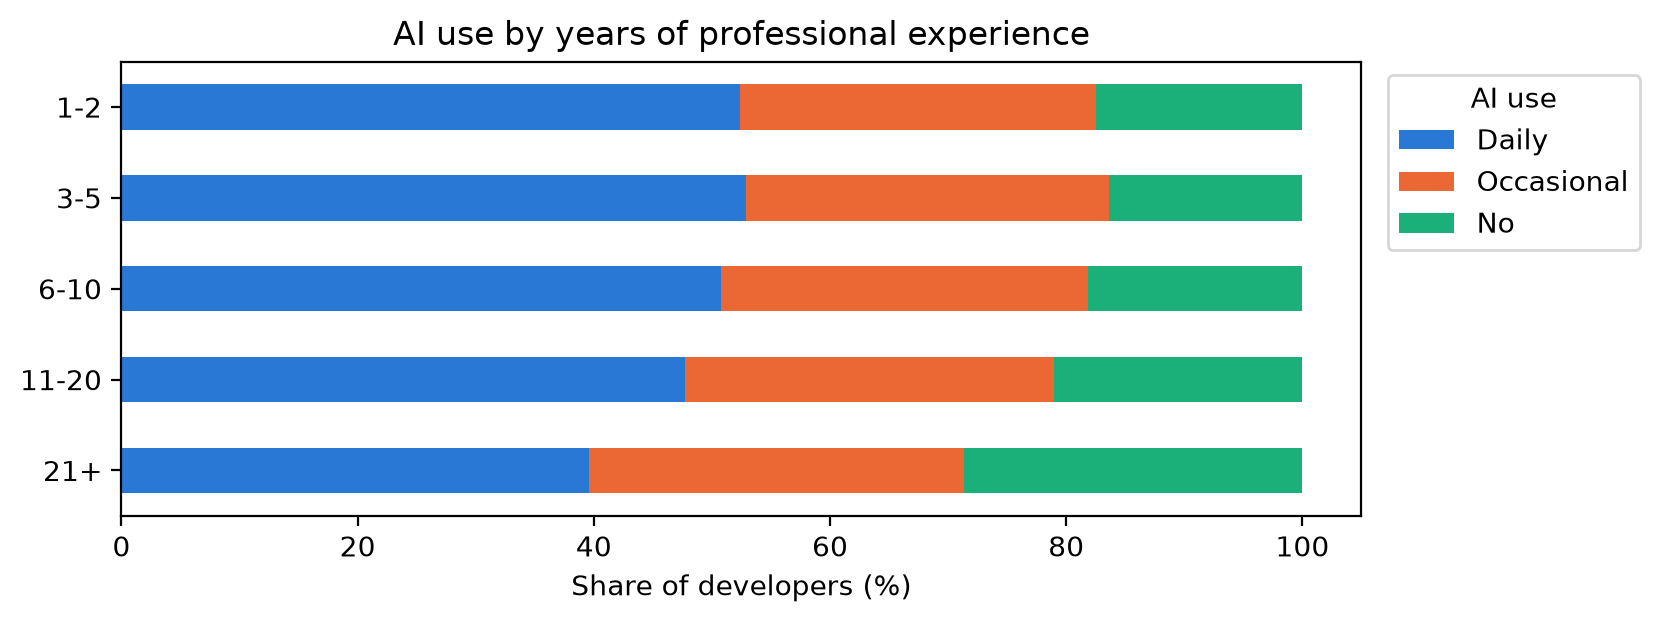

AISelect,Daily,Occasional,No
WorkExp,,,
1-2,52.4,30.2,17.5
3-5,52.9,30.8,16.4
6-10,50.8,31.1,18.1
11-20,47.7,31.3,21.0
21+,39.6,31.7,28.7


In [28]:
experience_band = pd.cut(explore["WorkExp"], bins=[0, 2, 5, 10, 20, 100], labels=["1-2", "3-5", "6-10", "11-20", "21+"])
plot_class_shares(experience_band, "AI use by years of professional experience")

**Role** (the 12 most frequent).

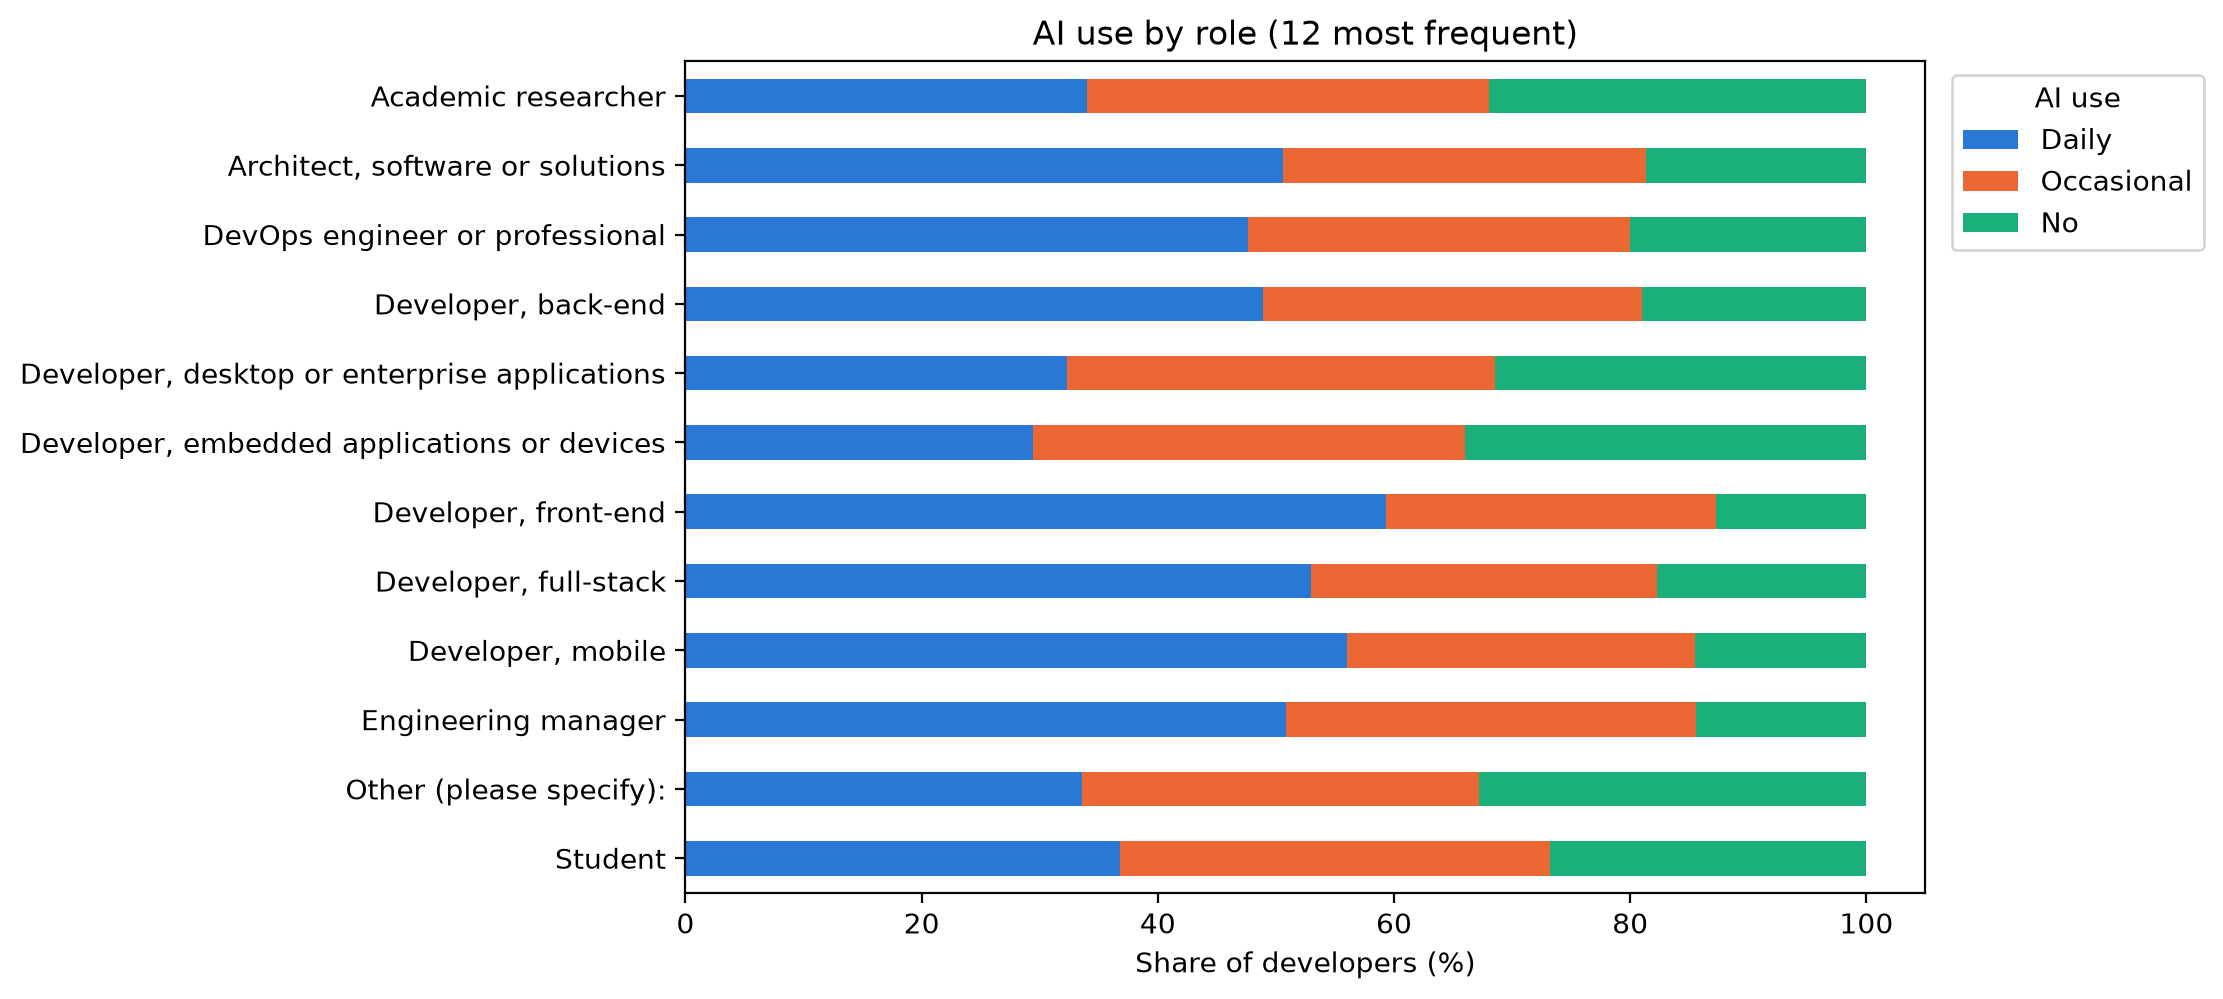

AISelect,Daily,Occasional,No
DevType,,,
Academic researcher,34.0,34.0,32.0
"Architect, software or solutions",50.6,30.8,18.6
DevOps engineer or professional,47.6,32.3,20.0
"Developer, back-end",48.9,32.1,19.0
"Developer, desktop or enterprise applications",32.3,36.3,31.4
"Developer, embedded applications or devices",29.4,36.6,34.0
"Developer, front-end",59.3,27.9,12.7
"Developer, full-stack",53.0,29.2,17.8
"Developer, mobile",56.0,29.5,14.5


In [29]:
top_roles = explore["DevType"].value_counts().head(12).index
plot_class_shares(explore.loc[explore["DevType"].isin(top_roles), "DevType"], "AI use by role (12 most frequent)")

**Number of technologies used** (5 groups of equal size).

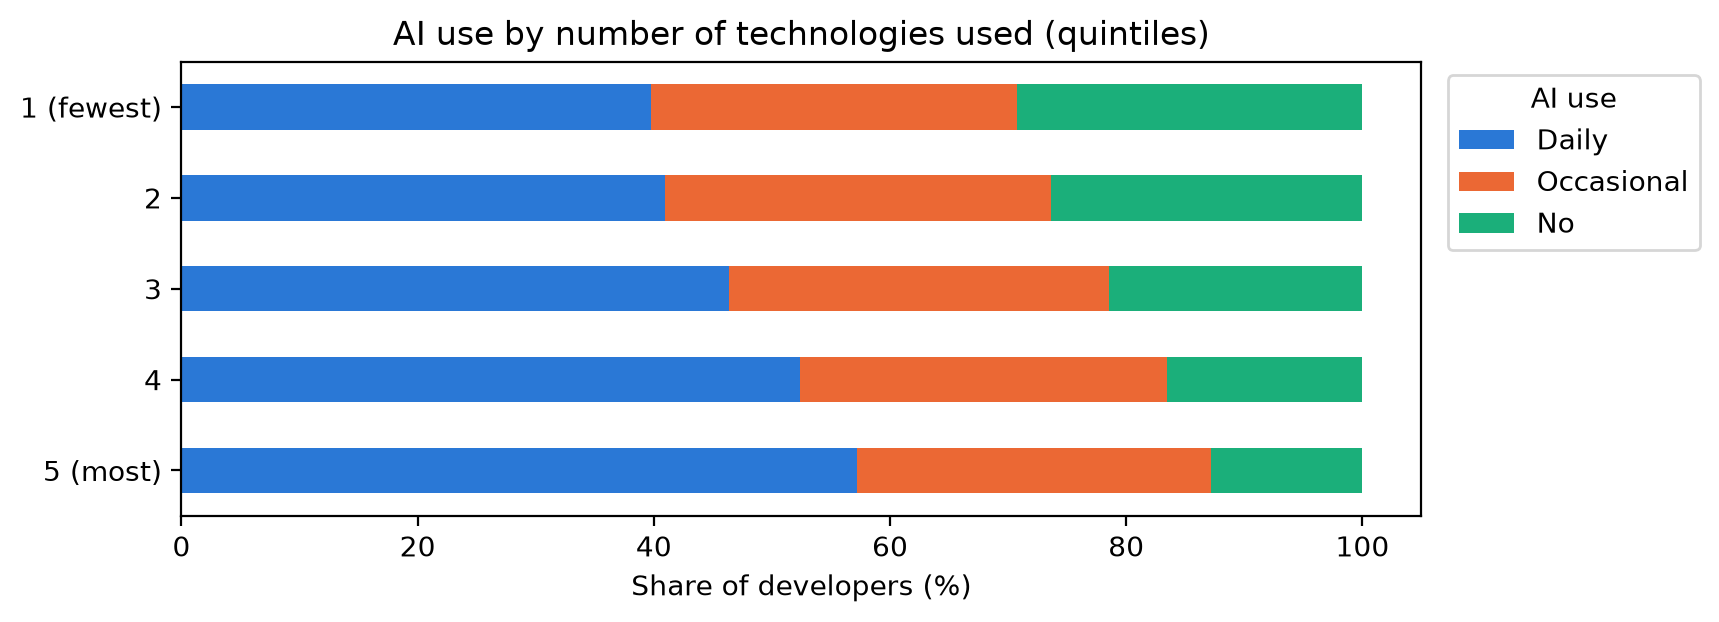

AISelect,Daily,Occasional,No
row_0,,,
1 (fewest),39.8,30.9,29.3
2,41.0,32.7,26.4
3,46.4,32.2,21.4
4,52.3,31.1,16.6
5 (most),57.2,30.0,12.8


In [30]:
STACK_COLS = ["LanguageHaveWorkedWith", "DatabaseHaveWorkedWith", "PlatformHaveWorkedWith", "WebframeHaveWorkedWith"]
n_technologies = 0
for col in STACK_COLS:
    n_technologies = n_technologies + explore[col].str.count(";").add(1).fillna(0)

stack_group = pd.qcut(n_technologies, q=5, labels=["1 (fewest)", "2", "3", "4", "5 (most)"])
plot_class_shares(stack_group, "AI use by number of technologies used (quintiles)")

**Country** (the 10 most frequent, the others grouped).

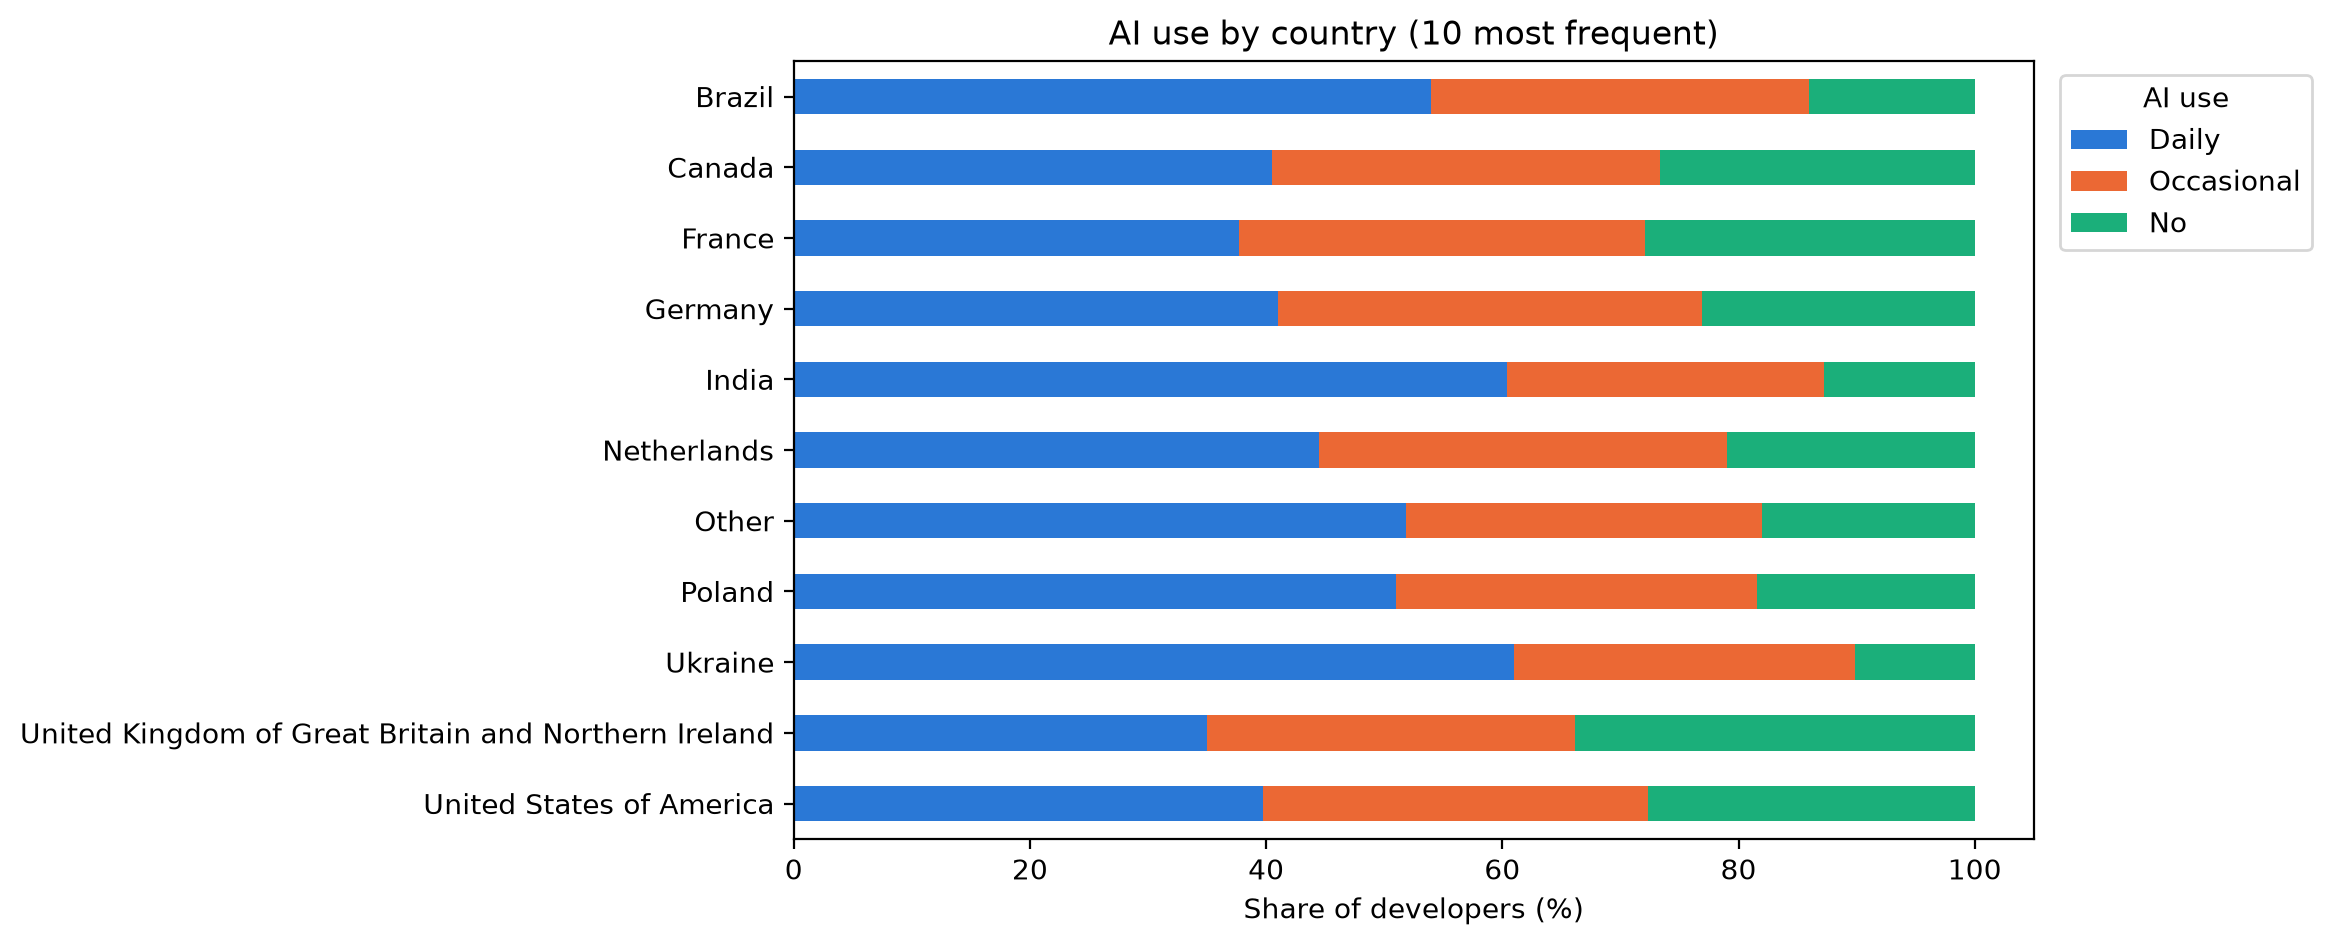

AISelect,Daily,Occasional,No
Country,,,
Brazil,54.0,32.0,14.0
Canada,40.5,32.8,26.7
France,37.7,34.4,27.9
Germany,41.0,35.9,23.1
India,60.4,26.9,12.7
Netherlands,44.5,34.5,21.0
Other,51.8,30.1,18.0
Poland,51.0,30.6,18.4
Ukraine,61.0,28.9,10.1


In [31]:
top_countries = explore["Country"].value_counts().head(10).index
country_group = explore["Country"].where(explore["Country"].isin(top_countries), "Other")
plot_class_shares(country_group, "AI use by country (10 most frequent)")

**Company size.**

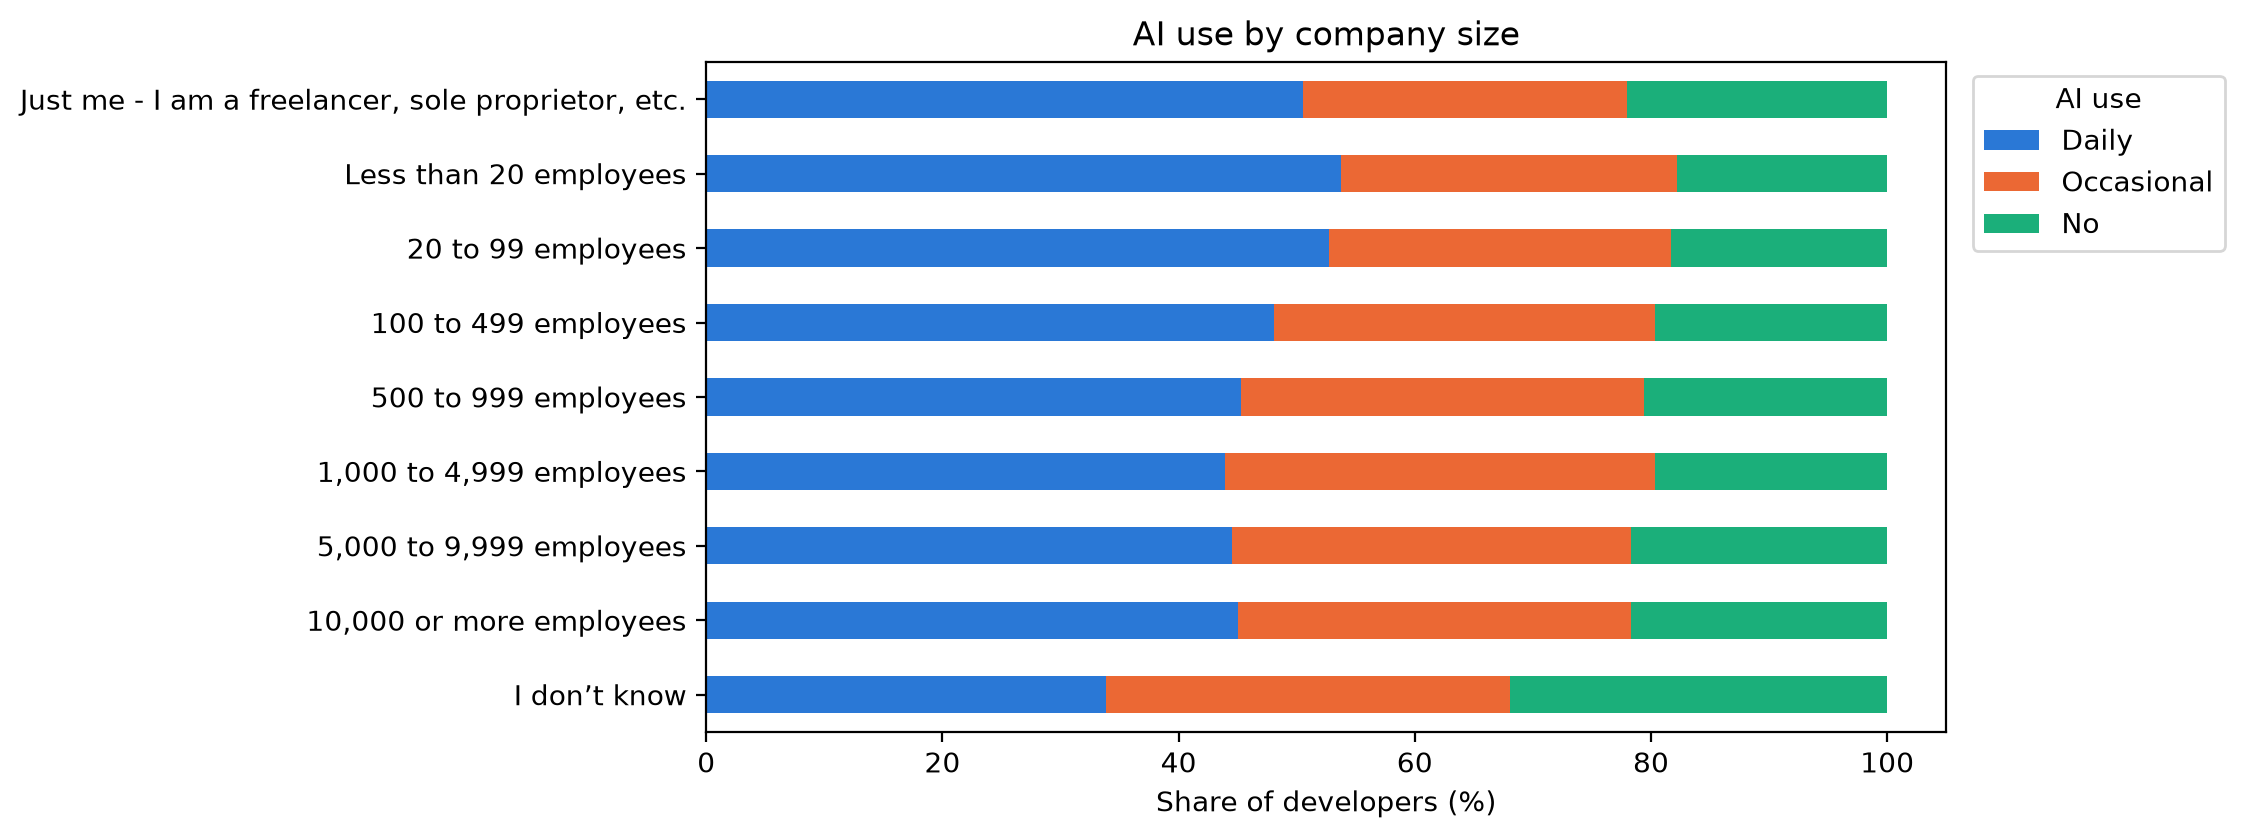

AISelect,Daily,Occasional,No
OrgSize,,,
"Just me - I am a freelancer, sole proprietor, etc.",50.5,27.4,22.1
Less than 20 employees,53.7,28.5,17.8
20 to 99 employees,52.7,29.0,18.3
100 to 499 employees,48.0,32.3,19.7
500 to 999 employees,45.3,34.1,20.6
"1,000 to 4,999 employees",43.9,36.5,19.7
"5,000 to 9,999 employees",44.5,33.8,21.7
"10,000 or more employees",45.0,33.3,21.7
I don’t know,33.8,34.2,31.9


In [32]:
ORG_SIZE_ORDER = ["Just me - I am a freelancer, sole proprietor, etc.", "Less than 20 employees", "20 to 99 employees",
                  "100 to 499 employees", "500 to 999 employees", "1,000 to 4,999 employees",
                  "5,000 to 9,999 employees", "10,000 or more employees", "I don’t know"]
plot_class_shares(explore["OrgSize"], "AI use by company size", order=ORG_SIZE_ORDER)

Looking at these plots one feature at a time:
- **Experience:** daily use goes down from about 52% (up to 5 years) to 40% (more than 20 years).
- **Role:** AI/ML engineers use AI daily much more than the others; embedded and desktop developers much less.
- **Technologies:** the more technologies someone uses, the more likely they use AI daily (from 40% to 57%).
- **Country:** daily use goes from 35% in the United Kingdom to about 60% in India and Ukraine.
- **Company size:** people in small companies use AI daily a bit more than in large ones.

The most important thing for us is that the share of **Occasional barely moves** (between 27% and 37%) whatever feature we look at. This tells us early on that it will be the hardest class to predict, and unfortunately it is also the one we care about most. Of course, these are only associations, not causes.

**Correlation matrix.** Only for this check, we turn the target into a number (No = 0, Occasional = 1, Daily = 2). We include the numeric columns, the number of technologies and the 10 most used languages. If one feature were very strongly correlated with the target, that would be a sign of leakage.

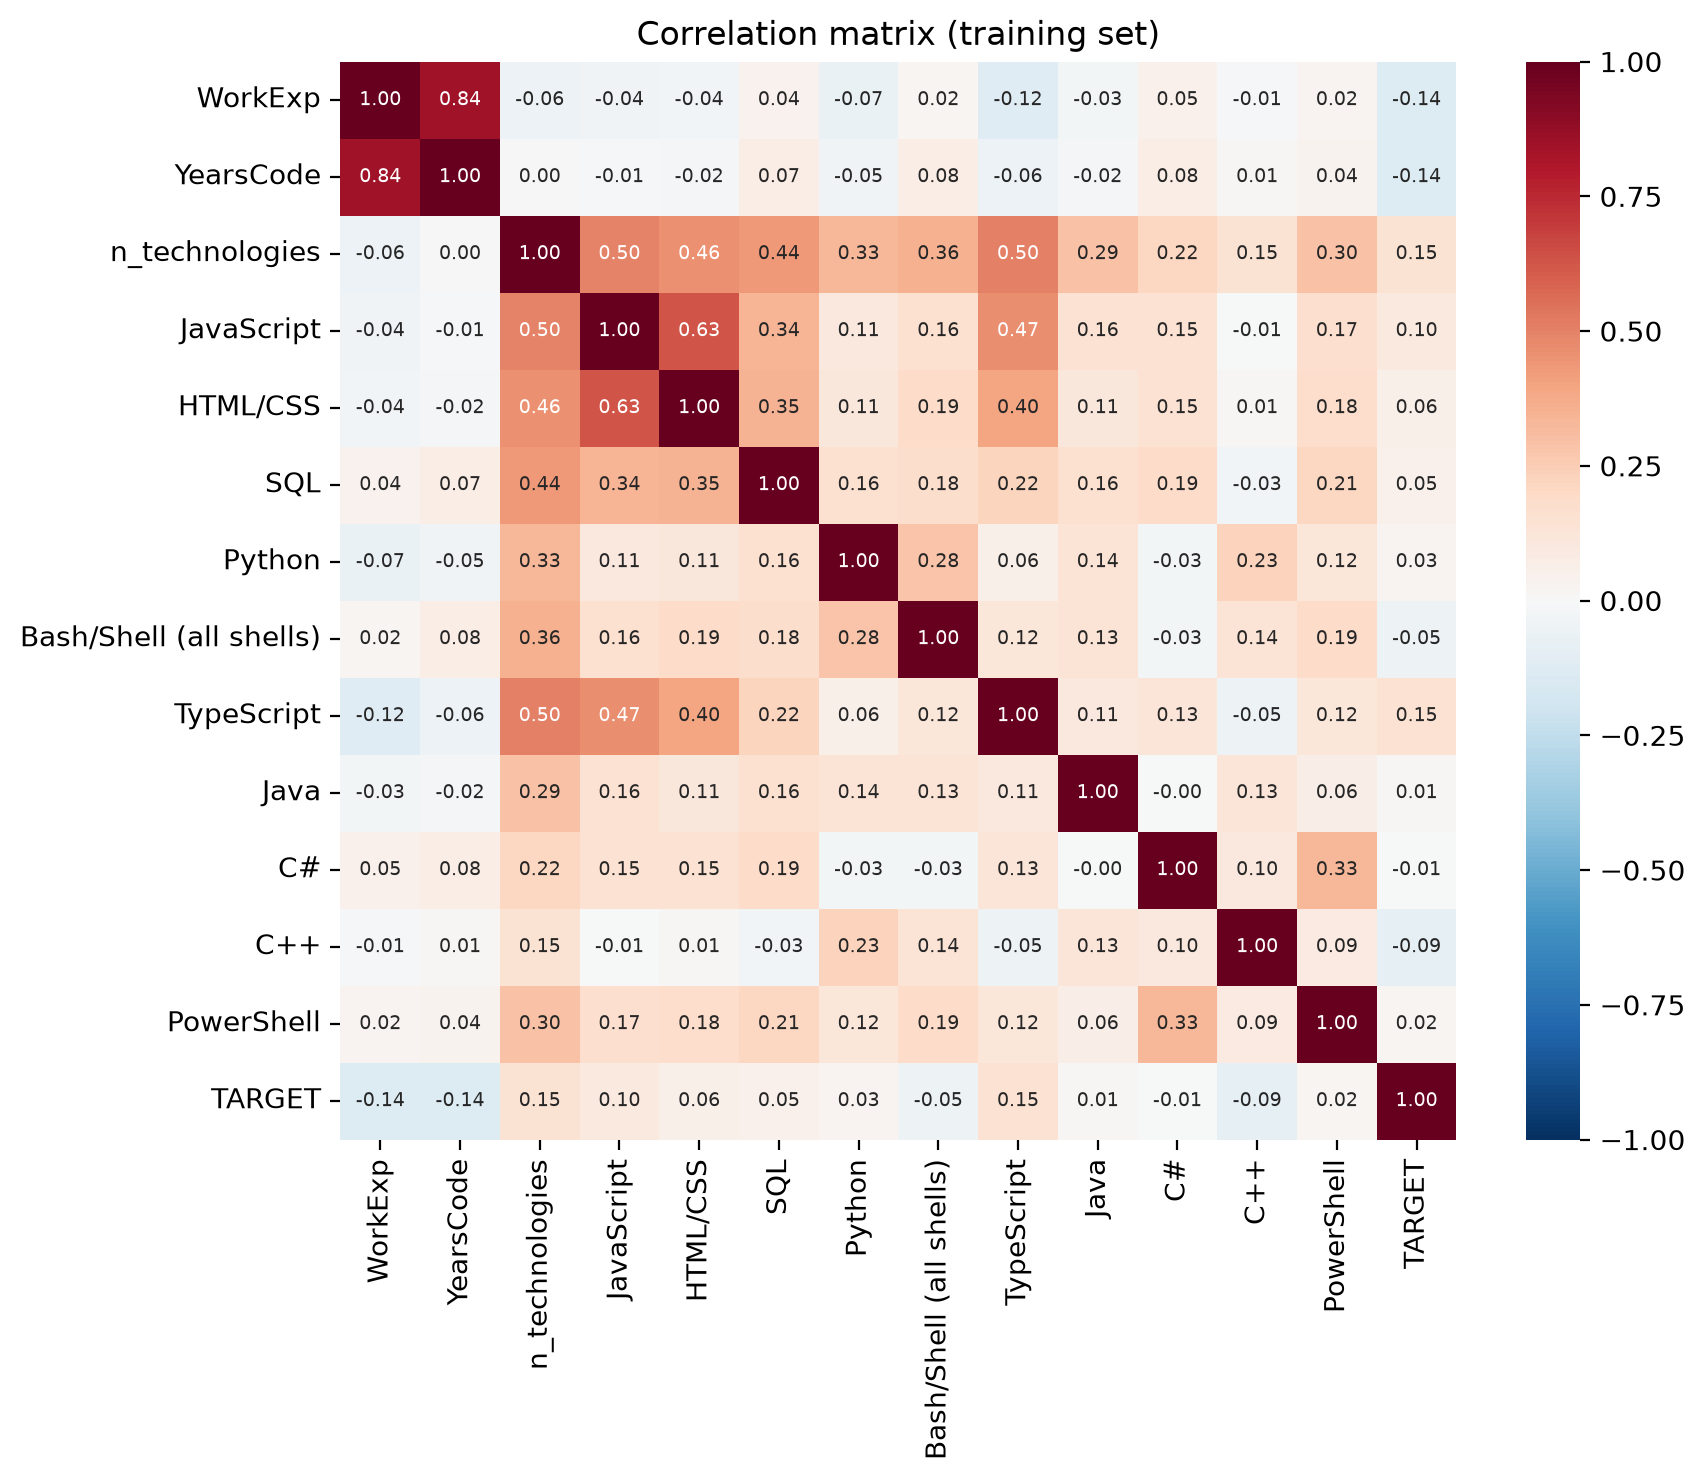

YearsCode                 -0.136249
WorkExp                   -0.135536
C++                       -0.089981
Bash/Shell (all shells)   -0.053688
C#                        -0.005057
Java                       0.008151
PowerShell                 0.016284
Python                     0.028832
SQL                        0.049673
HTML/CSS                   0.056913
JavaScript                 0.096663
n_technologies             0.147532
TypeScript                 0.153849
Name: TARGET, dtype: float64

In [33]:
corr_data = explore[NUMERIC_COLS].copy()
corr_data["n_technologies"] = n_technologies
languages = explore["LanguageHaveWorkedWith"].str.get_dummies(sep=";")
for lang in languages.sum().sort_values(ascending=False).head(10).index:
    corr_data[lang] = languages[lang]
corr_data["TARGET"] = y_train.map({"No": 0, "Occasional": 1, "Daily": 2})

plt.figure(figsize=(9, 7))
sns.heatmap(corr_data.corr(), cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix (training set)")
plt.show()

corr_data.corr()["TARGET"].drop("TARGET").sort_values()

No feature is strongly correlated with the target: they are all below 0.2 in absolute value. This is good news in two ways: the task is not trivial, and nothing suggests leakage. Using more technologies, and TypeScript or JavaScript in particular, goes with more AI use, while more years of experience go with less. `WorkExp` and `YearsCode` are strongly correlated with each other (0.84), as expected. Keep in mind that Pearson's coefficient only sees linear relations, so non-linear models might still find more.

**Scatter plots.** The correlation matrix only gives one number per pair, so we also look at two scatter plots on 3,000 random developers of the training set: the two experience columns against each other, to see if their relation is linear, and experience against the number of technologies, coloured by class, to see if the classes are separated.

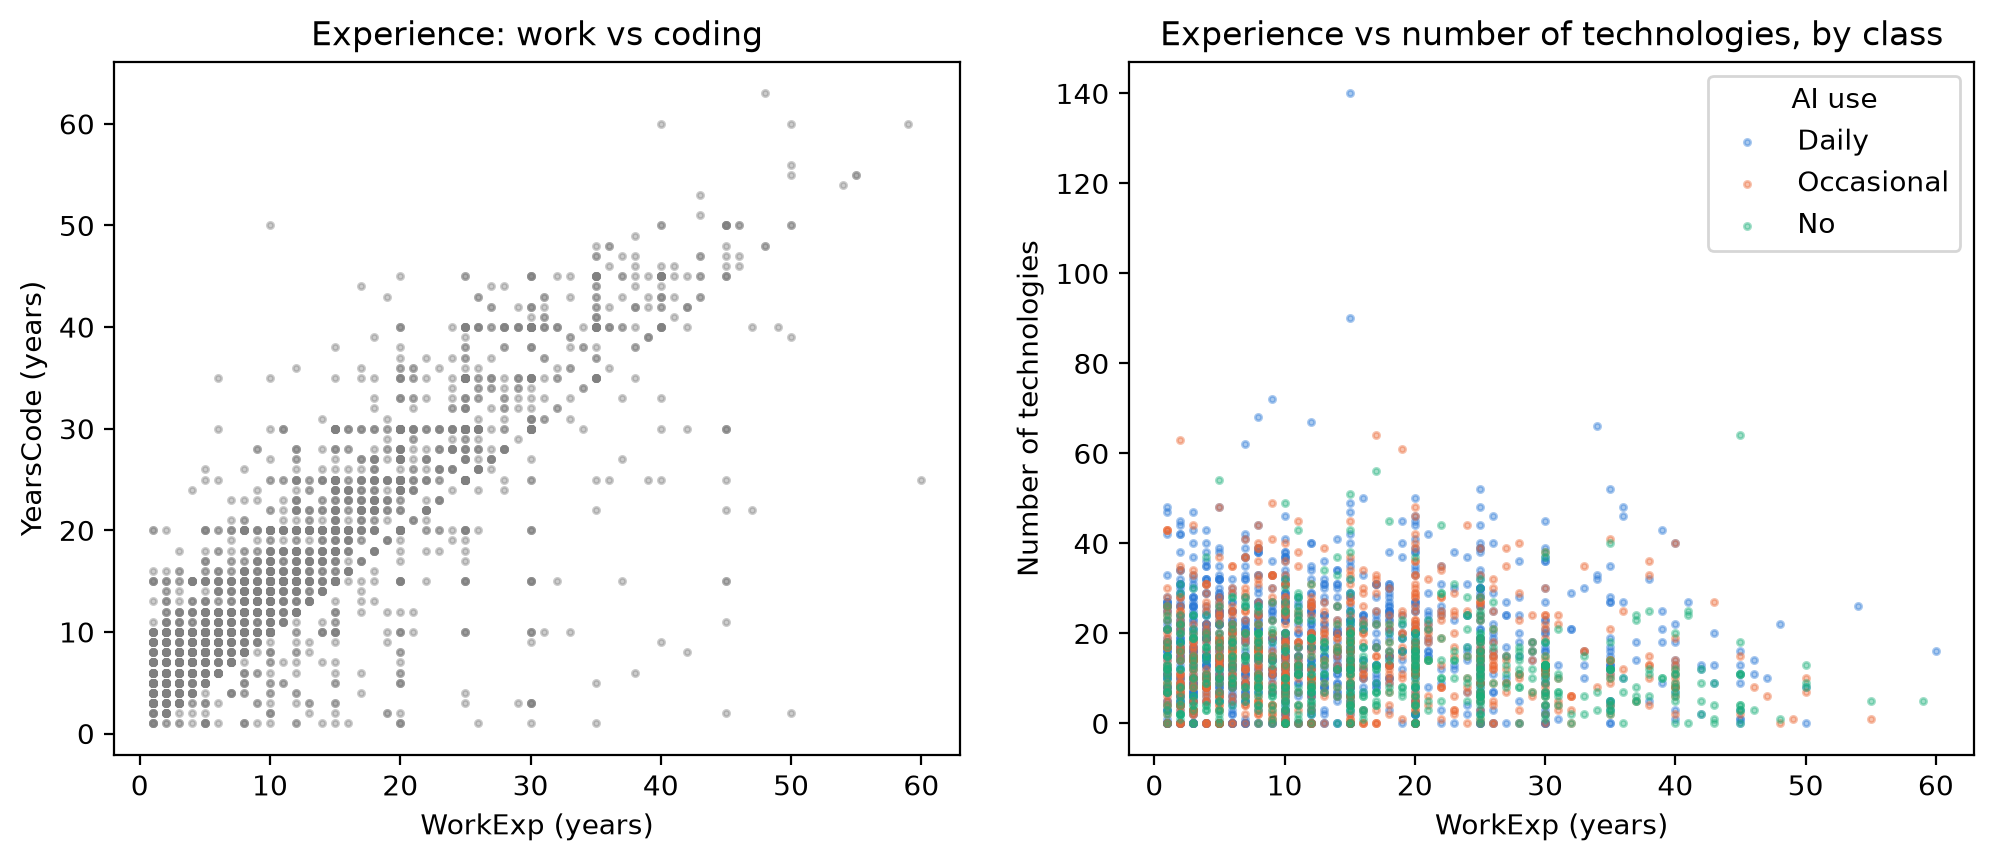

In [34]:
sample_idx = explore.sample(3000, random_state=RANDOM_STATE).index

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(explore.loc[sample_idx, "WorkExp"], explore.loc[sample_idx, "YearsCode"], s=5, alpha=0.4, color="grey")
axes[0].set_xlabel("WorkExp (years)")
axes[0].set_ylabel("YearsCode (years)")
axes[0].set_title("Experience: work vs coding")

for cls, color in zip(CLASS_ORDER, CLASS_COLORS):
    idx = sample_idx[y_train[sample_idx] == cls]
    axes[1].scatter(explore.loc[idx, "WorkExp"], n_technologies[idx], s=5, alpha=0.4, color=color, label=cls)
axes[1].set_xlabel("WorkExp (years)")
axes[1].set_ylabel("Number of technologies")
axes[1].set_title("Experience vs number of technologies, by class")
axes[1].legend(title="AI use")
plt.show()

On the left, the two experience columns follow a clear straight line, which matches their correlation of 0.84. The points are lined up on round numbers (10, 15, 20 years…) because people round their answers, and the points under the diagonal are the cases where `YearsCode` < `WorkExp` that we saw in 2.4.

On the right, the three classes are completely mixed. There is no line, and not even a curve, that could separate them with these two features. This already tells us something about **linear separability**: with features like these the classes are not linearly separable, and in 3.2 we will see that non-linear models don't do much better either.

**H3: are the people without a target similar to the others?**

In [35]:
without_target = df[df[TARGET].isna()]
comparison = pd.DataFrame({
    "training set": [(explore["Employment"] == "Employed").mean() * 100, explore["WorkExp"].median(),
                     explore["Country"].isna().mean() * 100],
    "rows without target": [(without_target["Employment"] == "Employed").mean() * 100,
                            without_target["WorkExp"].median(), without_target["Country"].isna().mean() * 100],
}, index=["employed (%)", "median WorkExp (years)", "Country missing (%)"])
comparison.round(1)

,training set,rows without target
employed (%),71.0,63.4
median WorkExp (years),11.0,9.0
Country missing (%),0.0,88.9


Most people without a target simply stopped the survey early: 89% of them didn't even give their country. They are also a bit less experienced and less often employed. So H3 is only partly true, and our model really describes people who went through a long survey to the end.

**A human rule (second baseline).** We asked ourselves how a salesperson would decide without any model. Something like:
1. **No** for people who are not professional developers, are retired, or are embedded/desktop developers with more than 20 years of experience;
2. otherwise **Daily** for front-end, mobile, full-stack and AI/ML roles;
3. **Occasional** for everyone else.

In [36]:
NOT_PROFESSIONAL = ["I code primarily as a hobby",
                    "I used to be a developer by profession, but no longer am",
                    "I am not primarily a developer, but I write code sometimes as part of my work/studies"]
SKEPTICAL_ROLES = ["Developer, embedded applications or devices", "Developer, desktop or enterprise applications"]
EARLY_ADOPTER_ROLES = ["Developer, front-end", "Developer, mobile", "Developer, full-stack", "AI/ML engineer"]


def salesperson_rule(X):
    prediction = pd.Series("Occasional", index=X.index)
    prediction[X["DevType"].isin(EARLY_ADOPTER_ROLES)] = "Daily"
    is_no = (X["MainBranch"].isin(NOT_PROFESSIONAL)
             | (X["Employment"] == "Retired")
             | (X["DevType"].isin(SKEPTICAL_ROLES) & (X["WorkExp"] > 20)))
    prediction[is_no] = "No"
    return prediction


rule_f1_train = f1_score(y_train, salesperson_rule(explore), average="macro")
print("Macro-F1 of the rule on the training set:", round(rule_f1_train, 3))

Macro-F1 of the rule on the training set: 0.385


Since this rule doesn't learn anything from the data, we can measure it on the whole training set directly. A model is only worth it if it beats this rule.

**What we take from the exploration**
1. The classes are unbalanced but none is rare, so macro-F1 is a reasonable metric.
2. Role, country, number of technologies and experience carry some signal, but no feature is strong on its own.
3. "Occasional" will be the hardest class.
4. Useful transformations: one 0/1 column per option, the number of options per question, hidden missing values turned into real ones, rare countries grouped.
5. Data that would help but that we don't have: real GitHub activity, or the AI policy of each company.

### 2.7 Data preparation

Here is what we decided for each problem found during the exploration:

| Problem | Decision |
|---|---|
| "I prefer not to say", "I don’t know" | Set to missing |
| Years above 60 | Set to missing (typing errors) |
| `WorkExp` > `YearsCode` | Kept (we cannot know which one is wrong) |
| Missing years | Median + a 0/1 column "was missing" |
| Multiple-choice columns | One 0/1 column per option + one "was missing" column per question |
| Rare options (ticked by fewer than 5% of the training developers) | Grouped in one "Other" column per question |
| Size of the stack | New feature: number of options ticked per question |
| Single-choice columns | Missing → "missing" category, then one-hot encoding |
| Rare categories, e.g. small countries (fewer than 50 developers) | Grouped in one "infrequent" column by the one-hot encoder |
| Numeric features | Standardized |

We split these steps into two kinds:
- **(a) Fixed rules** (cleaning, 0/1 option columns, counts). To split an answer like "Python;SQL" into 0/1 columns we use the pandas method `str.get_dummies(sep=";")`, which creates one column per option. These rules work row by row, so we can apply them with pandas, first on the training set and later on the test set. The list of frequent options of each multiple-choice question comes from the training set, but this doesn't use the target, and an option that doesn't appear in a fold just gives a column of zeros. Keeping only the options ticked by at least 5% of the developers takes us from 182 to 99 options (plus one "Other" column per question).
- **(b) Steps that learn something from the data** (median, mean, standard deviation, categories, rare categories). These go inside a scikit-learn `Pipeline`, so that during cross-validation they are learned again on each training fold only.

In [37]:
MAX_YEARS = 60
MIN_CATEGORY_SIZE = 50    # rarer categories are grouped by the one-hot encoder (inside the pipeline)
MIN_OPTION_SHARE = 0.05   # multiple-choice options ticked by fewer than 5% of the developers -> "Other"
HIDDEN_MISSING = {"Employment": "I prefer not to say", "OrgSize": "I don’t know"}

country_counts = train_set["Country"].value_counts()
print("Countries with at least", MIN_CATEGORY_SIZE, "developers:", (country_counts >= MIN_CATEGORY_SIZE).sum(),
      "out of", len(country_counts))


def frequent_options(X, columns, min_share=MIN_OPTION_SHARE):
    # For each multiple-choice question, the options ticked by at least min_share of the developers
    kept = {}
    for col in columns:
        share = X[col].str.get_dummies(sep=";").mean()
        kept[col] = list(share[share >= min_share].index)
    return kept


FREQUENT_OPTIONS = frequent_options(train_set, MULTI_CHOICE_COLS)
for col in MULTI_CHOICE_COLS:
    n_options = len(train_set[col].str.get_dummies(sep=";").columns)
    print(col, ":", len(FREQUENT_OPTIONS[col]), "options kept out of", n_options)

Countries with at least 50 developers: 62 out of 175


LanguageHaveWorkedWith : 19 options kept out of 42


DatabaseHaveWorkedWith : 10 options kept out of 30


PlatformHaveWorkedWith : 32 options kept out of 42


WebframeHaveWorkedWith : 16 options kept out of 28


OfficeStackAsyncHaveWorkedWith : 13 options kept out of 25
OpSysProfessional use : 9 options kept out of 15


In [38]:
def clean_features(X):
    # Hidden missing values and years above MAX_YEARS -> NaN
    X = X.copy()
    for col, value in HIDDEN_MISSING.items():
        X.loc[X[col] == value, col] = np.nan
    for col in NUMERIC_COLS:
        X.loc[X[col] > MAX_YEARS, col] = np.nan
    return X


def multi_choice_dummies(X, columns, kept):
    # 'Python;SQL' -> one 0/1 column per frequent option, one 0/1 column '<question>_Other' for the rare options,
    # and one 0/1 column '<question>_missing'
    parts = []
    for col in columns:
        dummies = X[col].str.get_dummies(sep=";")
        rare = [option for option in dummies.columns if option not in kept[col]]
        other = (dummies[rare].sum(axis=1) > 0).astype(int)
        dummies = dummies.reindex(columns=kept[col], fill_value=0)
        dummies.columns = [col + "_" + option for option in dummies.columns]
        dummies[col + "_Other"] = other
        dummies[col + "_missing"] = X[col].isna().astype(int)
        parts.append(dummies)
    return pd.concat(parts, axis=1)


def prepare_features(X, kept=None):
    # All the steps (a); kept = the multiple-choice options to keep (by default FREQUENT_OPTIONS)
    if kept is None:
        kept = FREQUENT_OPTIONS
    X = clean_features(X)
    for col in MULTI_CHOICE_COLS:
        X["n_" + col] = X[col].str.count(";").add(1).fillna(0)   # number of options ticked
    for col in NUMERIC_COLS:
        X[col + "_missing"] = X[col].isna().astype(int)
    return pd.concat([X, multi_choice_dummies(X, MULTI_CHOICE_COLS, kept)], axis=1)

In [39]:
X_train = prepare_features(train_set[OBSERVABLE_COLS])

COUNT_COLS = ["n_" + col for col in MULTI_CHOICE_COLS]
YEAR_MISSING_COLS = [col + "_missing" for col in NUMERIC_COLS]
DUMMY_COLS = list(multi_choice_dummies(train_set[OBSERVABLE_COLS], MULTI_CHOICE_COLS, FREQUENT_OPTIONS).columns)

print("X_train:", X_train.shape)
print("0/1 columns of the multiple-choice questions:", len(DUMMY_COLS))

X_train: (26976, 136)
0/1 columns of the multiple-choice questions: 111


**Steps (b).** We use a `ColumnTransformer`, because we have three kinds of columns that need different treatments: it applies each treatment to its own columns inside one single pipeline.
- numeric columns: missing values replaced by the median, then standardization;
- single-choice columns: a "missing" category, then one-hot encoding. Categories seen fewer than 50 times in the training fold are merged into one "infrequent" column (`min_frequency`), and categories never seen before are ignored;
- 0/1 option columns: left as they are (`passthrough`).

The original text columns of `X_train` are not selected, so the transformer simply ignores them.

In [40]:
def build_preprocessor(numeric_cols, single_cols, multi_cols, scale=True):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough"),   # scale=False only for the ablation (3.8)
    ])
    single_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CATEGORY_SIZE,
                                 sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_cols),
        ("cat", single_pipeline, single_cols),
        ("multi", "passthrough", multi_cols),
    ])


NUM_FEATURES = NUMERIC_COLS + COUNT_COLS + YEAR_MISSING_COLS


def make_pipeline_for(model, num_features=NUM_FEATURES, single_cols=SINGLE_CHOICE_COLS):
    # Steps (b) + model
    preprocessor = build_preprocessor(num_features, single_cols, DUMMY_COLS)
    return Pipeline([("prep", preprocessor), ("model", model)])

In [41]:
X_train_encoded = build_preprocessor(NUM_FEATURES, SINGLE_CHOICE_COLS, DUMMY_COLS).fit_transform(X_train)
print("Encoded training set:", X_train_encoded.shape)
print("Missing values left:", np.isnan(X_train_encoded).sum())

Encoded training set: (26976, 271)
Missing values left: 0


## 3. Training

In this whole section we only use the training set, with **5-fold cross-validation** (`cross_val_score` with `"f1_macro"`). For each model we report the mean and the standard deviation over the 5 folds.

### 3.1 Baselines

In [42]:
results = {}   # model name -> 5 macro-F1 scores (one per fold)

results["Baseline: most frequent class"] = cross_val_score(
    DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=CV, scoring="f1_macro")

print("Most frequent class:", results["Baseline: most frequent class"].mean().round(3))
print("Rule of the salesperson (whole training set):", round(rule_f1_train, 3))

Most frequent class: 0.213
Rule of the salesperson (whole training set): 0.385


### 3.2 Model comparison (Q1)

We start with the main classification models, all with their default parameters: logistic regression, linear SVM, k-NN, Naive Bayes, decision tree, random forest and gradient boosting. For Naive Bayes we use the Bernoulli version, because most of our features are 0/1: each P(x_i | C) is simply the probability that option i is ticked by the developers of class C. For gradient boosting we use `HistGradientBoostingClassifier`, which first cuts each numeric feature into at most 255 bins, so it is much faster when there are many rows. The SVM with an RBF kernel is too slow on all the data, so we train it on 8,000 rows only, which means its score can't be compared exactly with the others.

The baseline in 3.1 comes from `DummyClassifier`, which ignores the features and always predicts the most frequent class.

In [43]:
MODELS = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Linear SVM": LinearSVC(),
    "k-NN": KNeighborsClassifier(),
    "Naive Bayes (Bernoulli)": BernoulliNB(),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

for name, model in MODELS.items():
    results[name] = cross_val_score(make_pipeline_for(model), X_train, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    print(f"{name}: {results[name].mean():.3f} ± {results[name].std():.3f}")

Logistic regression: 0.460 ± 0.002


Linear SVM: 0.449 ± 0.003


k-NN: 0.404 ± 0.011


Naive Bayes (Bernoulli): 0.417 ± 0.005


Decision tree: 0.392 ± 0.005


Random forest: 0.423 ± 0.004


Gradient boosting: 0.458 ± 0.004


In [44]:
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train,
                                          random_state=RANDOM_STATE)
results["SVM, RBF kernel (8,000 rows)"] = cross_val_score(make_pipeline_for(SVC()), X_small, y_small, cv=CV,
                                                         scoring="f1_macro", n_jobs=-1)
print(f"SVM, RBF kernel: {results['SVM, RBF kernel (8,000 rows)'].mean():.3f}")

SVM, RBF kernel: 0.420


We show the results as a table and as a bar plot with error bars of 1 standard deviation. The dashed line is the human rule.

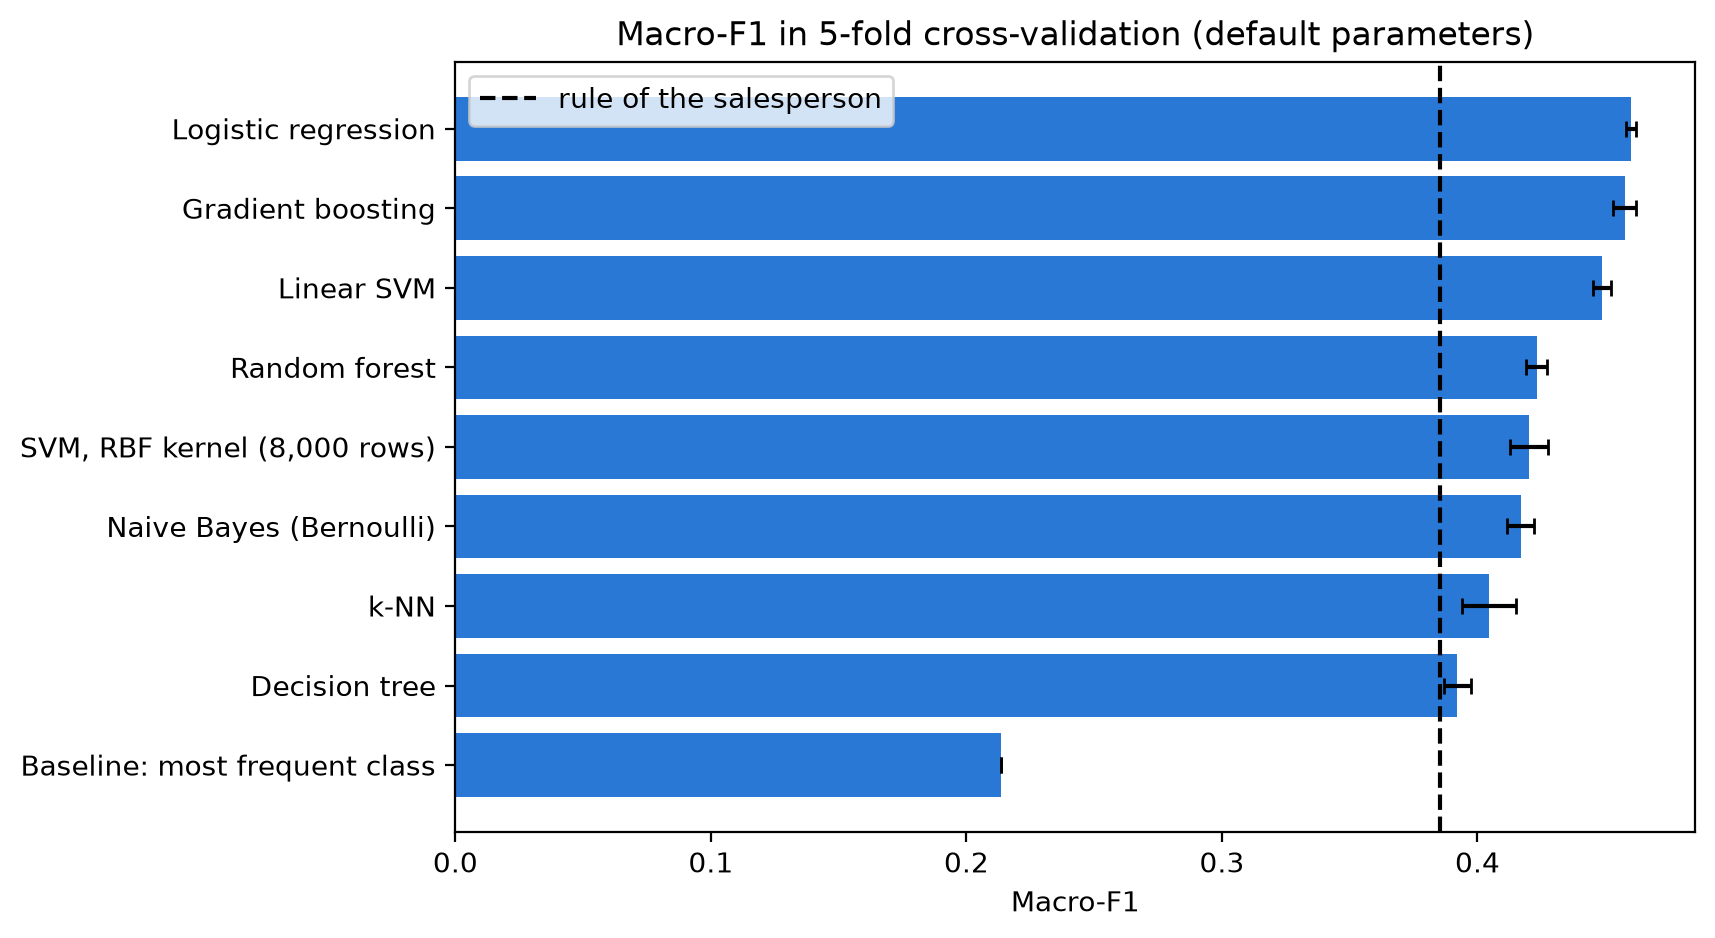

,macro_f1_mean,macro_f1_std
Logistic regression,0.460,0.002
Gradient boosting,0.458,0.004
Linear SVM,0.449,0.003
Random forest,0.423,0.004
"SVM, RBF kernel (8,000 rows)",0.420,0.007
Naive Bayes (Bernoulli),0.417,0.005
k-NN,0.404,0.011
Decision tree,0.392,0.005
Baseline: most frequent class,0.213,0.000


In [45]:
summary = pd.DataFrame({"macro_f1_mean": [s.mean() for s in results.values()],
                        "macro_f1_std": [s.std() for s in results.values()]},
                       index=list(results)).sort_values("macro_f1_mean")

plt.figure(figsize=(8, 5))
plt.barh(summary.index, summary["macro_f1_mean"], xerr=summary["macro_f1_std"], color=CLASS_COLORS[0], capsize=3)
plt.axvline(rule_f1_train, color="black", linestyle="--", label="rule of the salesperson")
plt.title("Macro-F1 in 5-fold cross-validation (default parameters)")
plt.xlabel("Macro-F1")
plt.legend()
plt.show()

summary.sort_values("macro_f1_mean", ascending=False).round(3)

**Answer to Q1: partly.** Every model beats the most frequent class (0.213) and the human rule (0.385), although the decision tree only just makes it (0.392). The best three are logistic regression (0.460), gradient boosting (0.458) and the linear SVM (0.449). They are about 0.07 above the rule, and very close to each other.

What surprised us is that the simple models do as well as the complex ones. Our interpretation is that the signal is weak, so a linear model already captures most of it. The decision tree without a depth limit overfits (we look at this in 3.12), k-NN suffers from the high number of dimensions, and Naive Bayes from its independence assumption. So the profile does contain information, but the predictions are far from perfect.

About **linear separability**: the linear models (logistic regression, linear SVM) are as good as the non-linear ones (gradient boosting, random forest, RBF SVM, k-NN). If the classes could be separated by a curved boundary, the non-linear models should win clearly. Here, as the scatter plot in 2.6 suggested, the classes overlap so much that no boundary, straight or curved, separates them well.

### 3.3 Multiclass strategies

We compare the 3 multiclass strategies on the same logistic regression: One-vs-Rest, One-vs-One, and softmax (a single model for the 3 classes, which is the default).

In [46]:
strategies = {
    "One-vs-Rest": OneVsRestClassifier(LogisticRegression(max_iter=2000)),
    "One-vs-One": OneVsOneClassifier(LogisticRegression(max_iter=2000)),
    "Softmax": LogisticRegression(max_iter=2000),
}
for name, model in strategies.items():
    scores = cross_val_score(make_pipeline_for(model), X_train, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

One-vs-Rest: 0.454 ± 0.001


One-vs-One: 0.461 ± 0.004


Softmax: 0.460 ± 0.002


The three strategies give the same result, within one standard deviation. We keep softmax, because it gives one model whose 3 probabilities add up to 1, and that is exactly what we need to sort the contacts.

### 3.4 Most important variables

We look at this in two ways:
1. the **coefficients of the logistic regression**: since the features are either standardized or 0/1, they can be compared with each other;
2. the **random forest importances**, summed for each original question.

In [47]:
logreg = make_pipeline_for(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
feature_names = logreg.named_steps["prep"].get_feature_names_out()
coefficients = pd.DataFrame(logreg.named_steps["model"].coef_.T, index=feature_names,
                            columns=logreg.named_steps["model"].classes_)

for cls in CLASS_ORDER:
    print(f"Largest coefficients for '{cls}':")
    print(coefficients[cls].sort_values(ascending=False).head(6).round(2).to_string())
    print()

Largest coefficients for 'Daily':
cat__DevType_Developer, AI apps or physical AI    0.72
cat__DevType_AI/ML engineer                       0.65
cat__Country_China                                0.54
cat__Country_Pakistan                             0.50
cat__Country_Iran, Islamic Republic of...         0.47
cat__Country_Egypt                                0.41

Largest coefficients for 'Occasional':
cat__Country_Singapore    0.35
cat__Country_Estonia      0.24
cat__Country_Colombia     0.23
cat__Country_Lithuania    0.23
cat__Country_Belgium      0.23
cat__Country_Austria      0.22

Largest coefficients for 'No':
cat__Country_United Kingdom of Great Britain and Northern Ireland    0.55
cat__DevType_Support engineer or analyst                             0.50
cat__DevType_Database administrator or engineer                      0.40
cat__Employment_missing                                              0.38
cat__Country_Chile                                                   0.36
cat__Cou

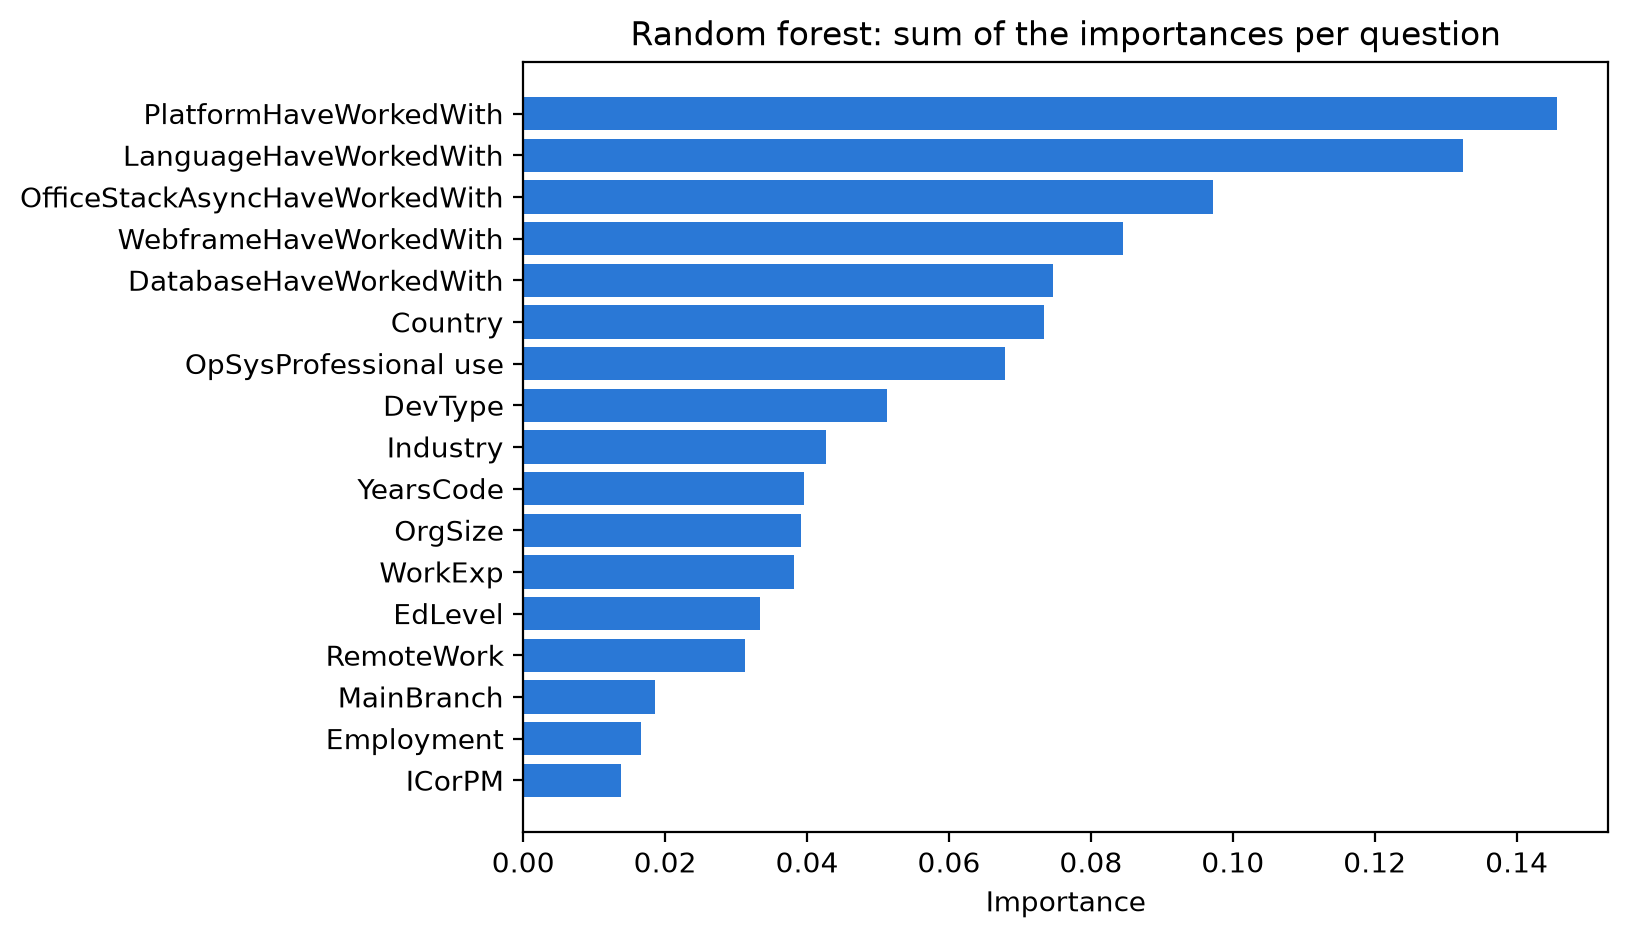

In [48]:
forest = make_pipeline_for(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
forest.fit(X_train, y_train)
importances = pd.Series(forest.named_steps["model"].feature_importances_, index=feature_names)

# Original question of each feature, e.g. 'multi__LanguageHaveWorkedWith_Python' -> 'LanguageHaveWorkedWith'
question = []
for name in importances.index:
    for col in OBSERVABLE_COLS:
        if col in name:
            question.append(col)
            break

importance_by_question = importances.groupby(question).sum().sort_values()
plt.figure(figsize=(7, 5))
plt.barh(importance_by_question.index, importance_by_question.values, color=CLASS_COLORS[0])
plt.title("Random forest: sum of the importances per question")
plt.xlabel("Importance")
plt.show()

For **Daily**, the biggest coefficients are the AI job titles and some countries. For **No**, we find the United Kingdom, support engineers, database administrators, people who didn't say their employment, Chile and Australia. For **Occasional**, all the coefficients are small and they are only countries: nothing really points to this class, which fits with what we saw in the exploration.

On the random forest side, the technologies come first (platforms, languages, collaboration tools, frameworks, databases), then country, OS, role and industry. We have to be careful with this ranking though: summing the importances per question favours questions with many options over questions with very few (2 for `ICorPM`). And, as always, importance means association, not causation. Just below we try a fairer method.

**Permutation importance, per question.** To avoid the problem above, we also try a third method. We train the logistic regression on 80% of the training set and, on the other 20%, we shuffle all the columns that come from one question at the same time (for example all the 0/1 columns of the languages). The drop in macro-F1 tells us how much the model needs that question. We repeat the shuffle 5 times and take the average.

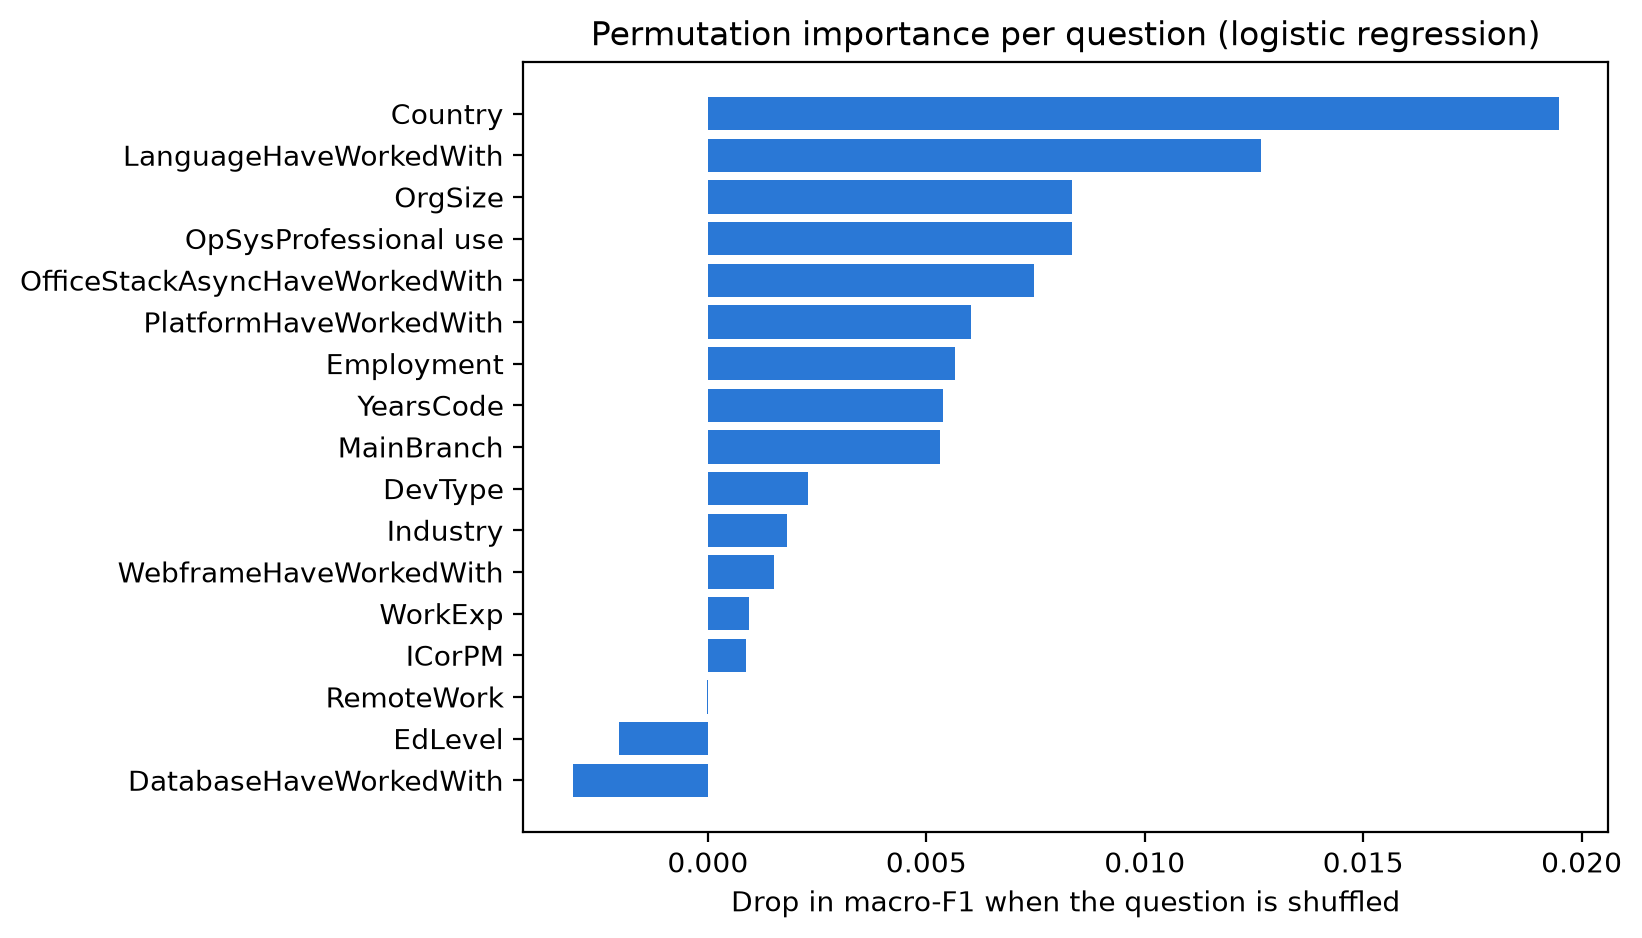

Macro-F1 without shuffling: 0.474


Country                           0.0195
LanguageHaveWorkedWith            0.0127
OrgSize                           0.0083
OpSysProfessional use             0.0083
OfficeStackAsyncHaveWorkedWith    0.0075
PlatformHaveWorkedWith            0.0060
Employment                        0.0056
YearsCode                         0.0054
MainBranch                        0.0053
DevType                           0.0023
Industry                          0.0018
WebframeHaveWorkedWith            0.0015
WorkExp                           0.0009
ICorPM                            0.0009
RemoteWork                       -0.0000
EdLevel                          -0.0020
DatabaseHaveWorkedWith           -0.0031
dtype: float64

In [49]:
X_fit, X_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                                  random_state=RANDOM_STATE)
perm_model = make_pipeline_for(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_fit, y_fit)
base_score = f1_score(y_valid, perm_model.predict(X_valid), average="macro")

rng = np.random.default_rng(RANDOM_STATE)
drops = {}
for col in OBSERVABLE_COLS:
    # every column built from this question: the question itself, its 0/1 options, its count, its "missing" column
    related = [c for c in X_valid.columns if c == col or c.startswith(col + "_") or c == "n_" + col]
    scores = []
    for repeat in range(5):
        X_shuffled = X_valid.copy()
        shuffled_rows = X_valid[related].iloc[rng.permutation(len(X_valid))]
        X_shuffled[related] = shuffled_rows.set_index(X_valid.index)
        scores.append(f1_score(y_valid, perm_model.predict(X_shuffled), average="macro"))
    drops[col] = base_score - np.mean(scores)

drops = pd.Series(drops).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(drops.index, drops.values, color=CLASS_COLORS[0])
plt.title("Permutation importance per question (logistic regression)")
plt.xlabel("Drop in macro-F1 when the question is shuffled")
plt.show()
print("Macro-F1 without shuffling:", round(base_score, 3))
drops.sort_values(ascending=False).round(4)

Without shuffling, the model gets 0.474 on this validation part. The question it needs the most is `Country` (−0.020 when shuffled), followed by the languages (−0.013), then the company size, the OS and the collaboration tools (about −0.008 each), the platforms, `Employment`, `YearsCode` and `MainBranch`. For remote work, `EdLevel` and the databases the drop is around zero or even slightly negative, which just means the model doesn't really use them and the small differences are noise. `WorkExp` brings almost nothing (−0.001), probably because `YearsCode`, which is very correlated with it, already carries the same information.

Compared with the random forest, the technologies are still near the top, but now `Country` comes first. This makes sense: when each question is counted once, the questions with many options are no longer favoured. We should keep in mind that these are two different models, and that all the drops are small, because the signal is weak in general.

### 3.5 Types of errors

Here is the cross-validated confusion matrix of the logistic regression, where each row adds up to 1. To build it we use `cross_val_predict`, which gives for each row the prediction of the model trained on the 4 other folds.

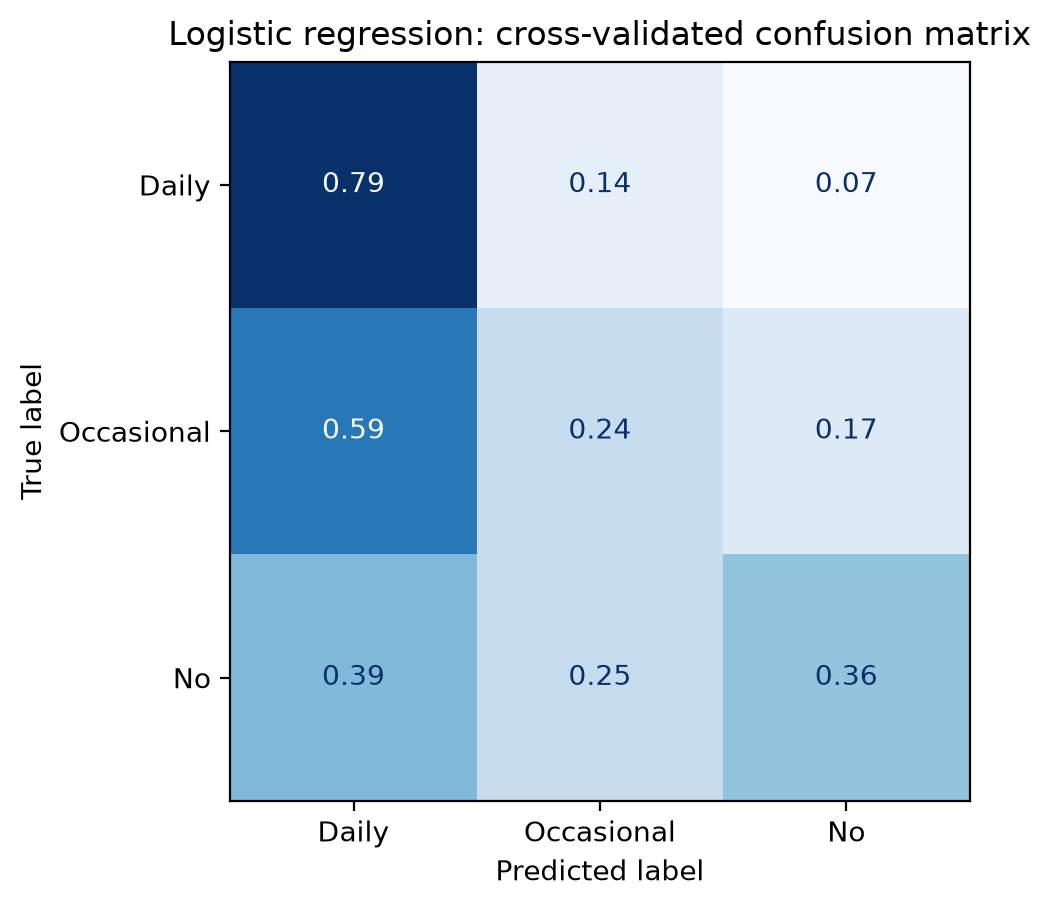

            Daily  Occasional    No
Daily        0.79        0.14  0.07
Occasional   0.59        0.24  0.17
No           0.39        0.25  0.36
Errors between Daily and No: 25.0% of all errors


In [50]:
logreg_cv_pred = cross_val_predict(make_pipeline_for(LogisticRegression(max_iter=2000)), X_train, y_train,
                                   cv=CV, n_jobs=-1)

display_cv = ConfusionMatrixDisplay.from_predictions(y_train, logreg_cv_pred, labels=CLASS_ORDER, normalize="true",
                                                     values_format=".2f", cmap="Blues", colorbar=False)
plt.title("Logistic regression: cross-validated confusion matrix")
plt.show()
print(pd.DataFrame(display_cv.confusion_matrix, index=CLASS_ORDER, columns=CLASS_ORDER).round(2))

wrong = y_train != logreg_cv_pred
far = ((y_train == "Daily") & (logreg_cv_pred == "No")) | ((y_train == "No") & (logreg_cv_pred == "Daily"))
print(f"Errors between Daily and No: {far.sum() / wrong.sum() * 100:.1f}% of all errors")

**Daily** is the class the model finds best (79%). **Occasional** is the hardest: only 24% are found, and 59% are predicted as Daily. **No** is in between, at 36%. In general the model leans towards Daily, the largest class.

The good news is that most mistakes are "small": 75% of the errors are between neighbouring classes, and only 25% confuse Daily with No. To avoid these errors, a human would need information the vendor doesn't have, like the AI policy of the company or the person's own opinion. This is what we measure in Q2.

### 3.6 Quick iterations

Next, we try a few small changes on the logistic regression, one at a time:
1. `class_weight="balanced"`: each class gets the weight n / (3 × n_class), which gives No ≈ 1.55, Occasional ≈ 1.06 and Daily ≈ 0.71, so mistakes on the small classes cost more. We try it because without weights the model says "Daily" too often;
2. removing the count features;
3. taking the log of the years (`np.log1p`), since they are skewed to the right (2.4);
4. removing `Country`, to see how much this sensitive feature actually brings (see the ethics part in 4.5).

In [51]:
X_train_log = X_train.copy()
X_train_log[NUMERIC_COLS] = np.log1p(X_train_log[NUMERIC_COLS])     # log(1 + years); NaN stays NaN

NUM_WITHOUT_COUNTS = NUMERIC_COLS + YEAR_MISSING_COLS
SINGLE_WITHOUT_COUNTRY = [col for col in SINGLE_CHOICE_COLS if col != "Country"]
balanced = LogisticRegression(max_iter=2000, class_weight="balanced")

iterations = {
    "0: default": (make_pipeline_for(LogisticRegression(max_iter=2000)), X_train),
    "1: + class_weight='balanced'": (make_pipeline_for(balanced), X_train),
    "2: balanced, without counts": (make_pipeline_for(balanced, num_features=NUM_WITHOUT_COUNTS), X_train),
    "3: balanced, log of the years": (make_pipeline_for(balanced), X_train_log),
    "4: balanced, without Country": (make_pipeline_for(balanced, single_cols=SINGLE_WITHOUT_COUNTRY), X_train),
}
for name, (pipeline, X) in iterations.items():
    scores = cross_val_score(pipeline, X, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    print(f"Iteration {name}: {scores.mean():.3f} ± {scores.std():.3f}")

Iteration 0: default: 0.460 ± 0.002


Iteration 1: + class_weight='balanced': 0.471 ± 0.007


Iteration 2: balanced, without counts: 0.470 ± 0.006


Iteration 3: balanced, log of the years: 0.471 ± 0.007


Iteration 4: balanced, without Country: 0.464 ± 0.006


The class weights help a little (0.460 → 0.471), because the small classes are found more often. Removing the counts changes almost nothing (0.470), but we keep them since they are easy to explain ("the size of the stack") and we saw their effect in the exploration (2.6). The log of the years gives exactly the same score (0.471), so we stay with the simpler version.

Removing `Country` lowers the score to 0.464. The loss (0.007) is about one standard deviation, so the country carries a little signal. We decided to keep it, but this doesn't settle the ethical question, which we discuss in 4.5. Finally, we test `class_weight` again as a hyperparameter in 3.11. We only did one round of these quick changes, because none of the changes brought a real gain.

**Threshold for the rare options.** In 2.7 we grouped the options ticked by fewer than 5% of the developers into "Other". To check that this choice doesn't cost anything, we compare several thresholds with the same balanced logistic regression (0% = keep all the options).

In [52]:
for share in [0.0, 0.01, 0.02, 0.05]:
    kept = frequent_options(train_set, MULTI_CHOICE_COLS, min_share=share)
    X_share = prepare_features(train_set[OBSERVABLE_COLS], kept)
    dummy_cols = list(multi_choice_dummies(train_set[OBSERVABLE_COLS], MULTI_CHOICE_COLS, kept).columns)
    pipeline = Pipeline([("prep", build_preprocessor(NUM_FEATURES, SINGLE_CHOICE_COLS, dummy_cols)),
                         ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    scores = cross_val_score(pipeline, X_share, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    n_options = sum(len(options) for options in kept.values())
    print(f"Options ticked by at least {share:.0%}: {n_options} options, macro-F1 {scores.mean():.3f} ± {scores.std():.3f}")

Options ticked by at least 0%: 182 options, macro-F1 0.472 ± 0.005


Options ticked by at least 1%: 171 options, macro-F1 0.471 ± 0.005


Options ticked by at least 2%: 153 options, macro-F1 0.472 ± 0.006


Options ticked by at least 5%: 99 options, macro-F1 0.471 ± 0.007


All four thresholds give the same score (0.471–0.472, well within one standard deviation). So grouping the rare options doesn't lose any information the model can use. We keep the 5% threshold: the same result with almost half as many options (99 instead of 182) gives a simpler model, and it follows the same idea as grouping the rare countries.

### 3.7 Dimensionality reduction and feature selection

We have more than 250 features after encoding, many of them rarely used, so we check whether keeping fewer of them helps. We put one extra step between the preparation and the balanced logistic regression, and compare:
- **no reduction** (all the features);
- **PCA**, keeping 90% of the variance, or only 50 components;
- **feature selection** with `SelectKBest(f_classif)`: for each feature, an ANOVA F-test measures how different its average is between the 3 classes, and we keep the k features with the biggest difference (k = 50 or 100).

Both steps are inside the pipeline, so they are learned on each training fold only.

In [53]:
def pipeline_with_reduction(step):
    # Preparation -> (optional reduction step) -> balanced logistic regression
    steps = [("prep", build_preprocessor(NUM_FEATURES, SINGLE_CHOICE_COLS, DUMMY_COLS))]
    if step is not None:
        steps.append(("reduce", step))
    steps.append(("model", LogisticRegression(max_iter=2000, class_weight="balanced")))
    return Pipeline(steps)


reductions = {
    "No reduction": None,
    "PCA, 90% of the variance": PCA(n_components=0.9, random_state=RANDOM_STATE),
    "PCA, 50 components": PCA(n_components=50, random_state=RANDOM_STATE),
    "Feature selection, best 100": SelectKBest(f_classif, k=100),
    "Feature selection, best 50": SelectKBest(f_classif, k=50),
}
for name, step in reductions.items():
    scores = cross_val_score(pipeline_with_reduction(step), X_train, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

pca_90 = pipeline_with_reduction(PCA(n_components=0.9, random_state=RANDOM_STATE)).fit(X_train, y_train)
print("Components kept by PCA (90%):", pca_90.named_steps["reduce"].n_components_)

No reduction: 0.471 ± 0.007


PCA, 90% of the variance: 0.464 ± 0.004


PCA, 50 components: 0.453 ± 0.004


Feature selection, best 100: 0.454 ± 0.005


Feature selection, best 50: 0.442 ± 0.004


Components kept by PCA (90%): 110


Keeping all the features gives the best score (0.471). PCA with 90% of the variance needs 110 components and gets 0.464, and with 50 components we go down to 0.453. Feature selection does even worse: 0.454 with the best 100 features and 0.442 with the best 50.

So reducing the dimension doesn't help here. Our interpretation is that the signal is spread over many small features (countries, technologies…) and each one brings a little bit, so removing some of them always loses something. The logistic regression already has an L2 regularization that handles the many features well, so we keep all of them.

### 3.8 Ablation study

Here we remove one part of our preparation at a time, to see how much each part really brings. It is a simple way to check that every step of the preparation is useful. We use the balanced logistic regression, because it is fast and almost as good as the best models. We wrote one small function that builds the pipeline without the parts we want to remove and returns the cross-validated macro-F1.

PCA is not part of our final pipeline (3.7), so it doesn't appear here.

In [54]:
def ablation_score(numeric=NUM_FEATURES, single=SINGLE_CHOICE_COLS, multi=DUMMY_COLS, scale=True, X=X_train):
    # Macro-F1 (5-fold CV) of the balanced logistic regression, with only the given columns and steps
    preprocessor = build_preprocessor(numeric, single, multi, scale=scale)
    pipeline = Pipeline([("prep", preprocessor),
                         ("model", LogisticRegression(max_iter=5000, class_weight="balanced"))])
    return cross_val_score(pipeline, X, y_train, cv=CV, scoring="f1_macro", n_jobs=-1).mean()


X_with_outliers = X_train.copy()
X_with_outliers[NUMERIC_COLS] = train_set[NUMERIC_COLS]          # years above 60 put back

ROLE_COLS = ["MainBranch", "DevType", "ICorPM"]
JOB_COLS = ["Employment", "OrgSize", "Industry", "RemoteWork"]
NO_MISSING_DUMMIES = [col for col in DUMMY_COLS if not col.endswith("_missing")]
TECH_QUESTIONS = STACK_COLS + ["OfficeStackAsyncHaveWorkedWith", "OpSysProfessional use"]


ablations = {
    "Nothing (full pipeline)": ablation_score(),
    "Scaling": ablation_score(scale=False),
    "Outlier handling (years > 60)": ablation_score(X=X_with_outliers),
    "'Was missing' columns": ablation_score(numeric=NUMERIC_COLS + COUNT_COLS, multi=NO_MISSING_DUMMIES),
    "Technologies": ablation_score(
        numeric=[c for c in NUM_FEATURES if c not in ["n_" + q for q in TECH_QUESTIONS]],
        multi=[c for c in DUMMY_COLS if c.split("_")[0] not in TECH_QUESTIONS]),
    "Role (MainBranch, DevType, ICorPM)": ablation_score(single=[c for c in SINGLE_CHOICE_COLS if c not in ROLE_COLS]),
    "Job (Employment, OrgSize, Industry, RemoteWork)": ablation_score(single=[c for c in SINGLE_CHOICE_COLS if c not in JOB_COLS]),
    "Country": ablation_score(single=SINGLE_WITHOUT_COUNTRY),
    "Experience and education": ablation_score(numeric=COUNT_COLS,
                                               single=[c for c in SINGLE_CHOICE_COLS if c != "EdLevel"]),
}

full_score = ablations["Nothing (full pipeline)"]
ablation_table = pd.DataFrame({"macro_f1": ablations})
ablation_table["drop"] = full_score - ablation_table["macro_f1"]
ablation_table.index.name = "removed"
ablation_table.sort_values("drop", ascending=False).round(3)

,macro_f1,drop
removed,,
Technologies,0.438,0.033
Country,0.464,0.006
"Job (Employment, OrgSize, Industry, RemoteWork)",0.466,0.005
'Was missing' columns,0.467,0.003
"Role (MainBranch, DevType, ICorPM)",0.468,0.003
Experience and education,0.469,0.002
Scaling,0.470,0.000
Outlier handling (years > 60),0.471,0.000
Nothing (full pipeline),0.471,0.000


The table is quite clear: the **technologies** are by far the most important part of our features. Without them the score drops by 0.033. Then come `Country` (−0.006) and the job (−0.005). The "was missing" columns and the role bring 0.003 each, and experience/education only 0.002, probably because their information is also in the other features (for example, the technologies say a lot about someone's role and seniority).

Two steps of our preparation make no difference for this model: scaling and outlier handling (both 0.000). For scaling, the reason is that almost all our features are already 0/1 and only a few are numeric. For outliers, there are only 51 values above 60 years. We still keep both steps, because they are good practice and some models, like k-NN, are sensitive to the scale of the features.

### 3.9 Value of the information the vendor does not have (Q2)

To answer Q2, we train the same model (gradient boosting with balanced classes) on 3 sets of features:
- **A:** the observable profile (our real case);
- **B:** A + opinions and private behaviour;
- **C:** B + the AI questions. This is leakage, and we only do it **to show the effect**.

While doing this, we noticed that some "not observable" columns list AI tools among their options. For example, the development environments include Cursor and Copilot. This is hidden leakage, so we moved these columns from B to C.

In [55]:
text_not_observable = [col for col in NOT_OBSERVABLE_COLS if train_set[col].dtype != "float64"]
HIDDEN_LEAKAGE = [col for col in text_not_observable if train_set[col].str.contains(AI_WORDS, na=False).any()]
print("Hidden leakage:", HIDDEN_LEAKAGE)

FREE_TEXT_LEAKAGE = [col for col in LEAKAGE_COLS if col.endswith(("Write", "Entry")) or col in ["AIExplain", "AIOpen"]]
FEATURE_SETS = {
    "A: observable profile": OBSERVABLE_COLS,
    "B: A + opinions and private behaviour": OBSERVABLE_COLS + [c for c in NOT_OBSERVABLE_COLS if c not in HIDDEN_LEAKAGE],
    "C: B + AI questions (leakage)": OBSERVABLE_COLS + NOT_OBSERVABLE_COLS
                                     + [c for c in LEAKAGE_COLS if c not in FREE_TEXT_LEAKAGE],
}

Hidden leakage: ['DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'SOTagsHaveWorkedWith', 'SOTagsWantToWorkWith', 'SOTagsAdmired', 'SO_Dev_Content']


For each set we use the same simple preparation: one 0/1 column per option for the multiple-choice columns, then the same `build_preprocessor` as before.

In [56]:
q2_results = {}
for set_name, columns in FEATURE_SETS.items():
    X_set = train_set[columns]
    numeric = [col for col in columns if X_set[col].dtype == "float64"]
    multi = [col for col in columns if col not in numeric and X_set[col].str.contains(";", na=False).any()]
    single = [col for col in columns if col not in numeric + multi]
    dummies = multi_choice_dummies(X_set, multi, frequent_options(X_set, multi))
    X_set = pd.concat([X_set, dummies], axis=1)

    pipeline = Pipeline([
        ("prep", build_preprocessor(numeric, single, list(dummies.columns))),
        ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    ])
    q2_results[set_name] = cross_val_score(pipeline, X_set, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    print(f"{set_name} ({len(columns)} columns): {q2_results[set_name].mean():.3f} ± {q2_results[set_name].std():.3f}")

A: observable profile (17 columns): 0.473 ± 0.004


/tmp/claude-0/-home-claude/2a30a981-cd5b-541a-8d69-455c583c9271/scratchpad/venv16/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


B: A + opinions and private behaviour (98 columns): 0.550 ± 0.005


C: B + AI questions (leakage) (142 columns): 0.757 ± 0.009


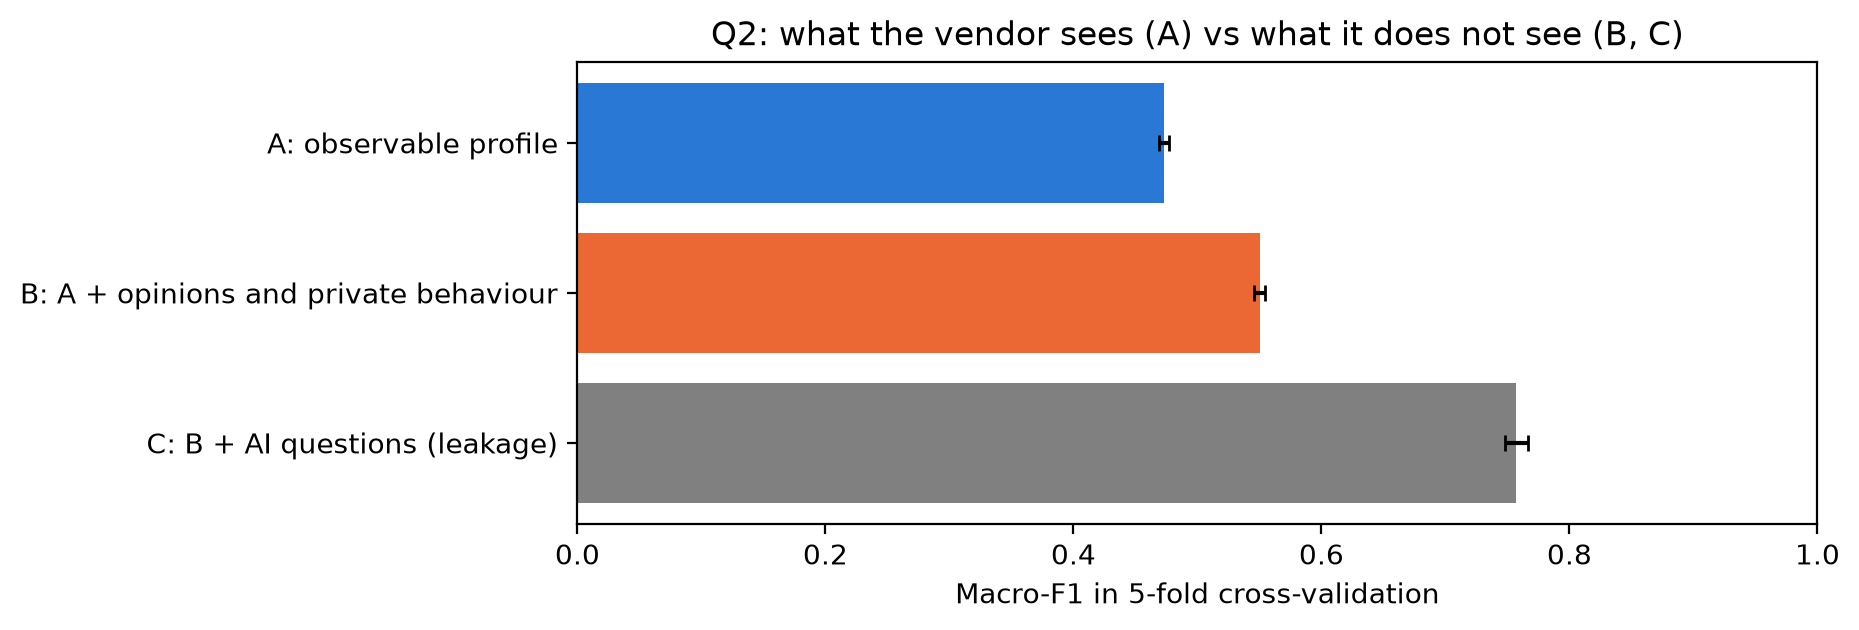

In [57]:
plt.figure(figsize=(8, 3))
plt.barh(list(q2_results), [s.mean() for s in q2_results.values()], xerr=[s.std() for s in q2_results.values()],
         color=[CLASS_COLORS[0], CLASS_COLORS[1], "grey"], capsize=3)
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.title("Q2: what the vendor sees (A) vs what it does not see (B, C)")
plt.xlabel("Macro-F1 in 5-fold cross-validation")
plt.show()

With the profile alone we get **0.473**. Adding opinions and private behaviour brings it to **0.550** (+0.08), and with the AI questions it jumps to **0.757**. (We also found 7 "not observable" columns with AI tools in their options, which we moved to set C.)

So the information a vendor can't get without an interview is worth a lot, and the AI questions almost give the answer. This explains the 0.64 of our proposal, and very probably the 94% of the DEV article as well.

### 3.10 Developer personas (Q3, unsupervised)

For this part we only use the technologies (the frequent options, as in 2.7), without the target:
1. **PCA**: how many components do we need to explain 80% of the variance?
2. **K-means**: we choose k with the elbow method, then look at the groups.
3. **PCA and t-SNE** in 2D on 3,000 developers, to see the groups.
4. How much each group uses AI.

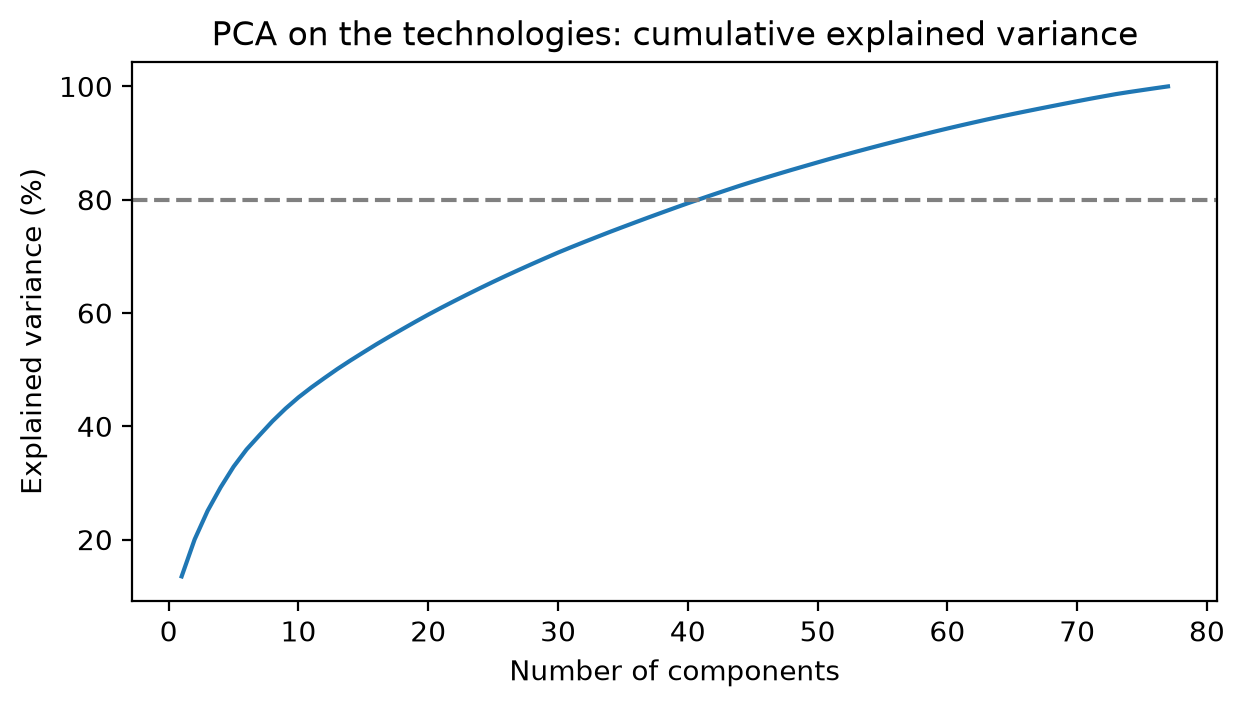

25009 developers, 77 technologies; 41 components explain 80% of the variance


In [58]:
technologies = multi_choice_dummies(explore, STACK_COLS, FREQUENT_OPTIONS)
technologies = technologies.drop(columns=[col + "_missing" for col in STACK_COLS]
                                         + [col + "_Other" for col in STACK_COLS])
technologies = technologies[technologies.sum(axis=1) > 0]      # developers who ticked at least one technology

pca = PCA().fit(technologies)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumulative >= 0.8) + 1

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(cumulative) + 1), cumulative * 100)
plt.axhline(80, color="grey", linestyle="--")
plt.title("PCA on the technologies: cumulative explained variance")
plt.xlabel("Number of components")
plt.ylabel("Explained variance (%)")
plt.show()
print(len(technologies), "developers,", technologies.shape[1], "technologies;", n_components,
      "components explain 80% of the variance")

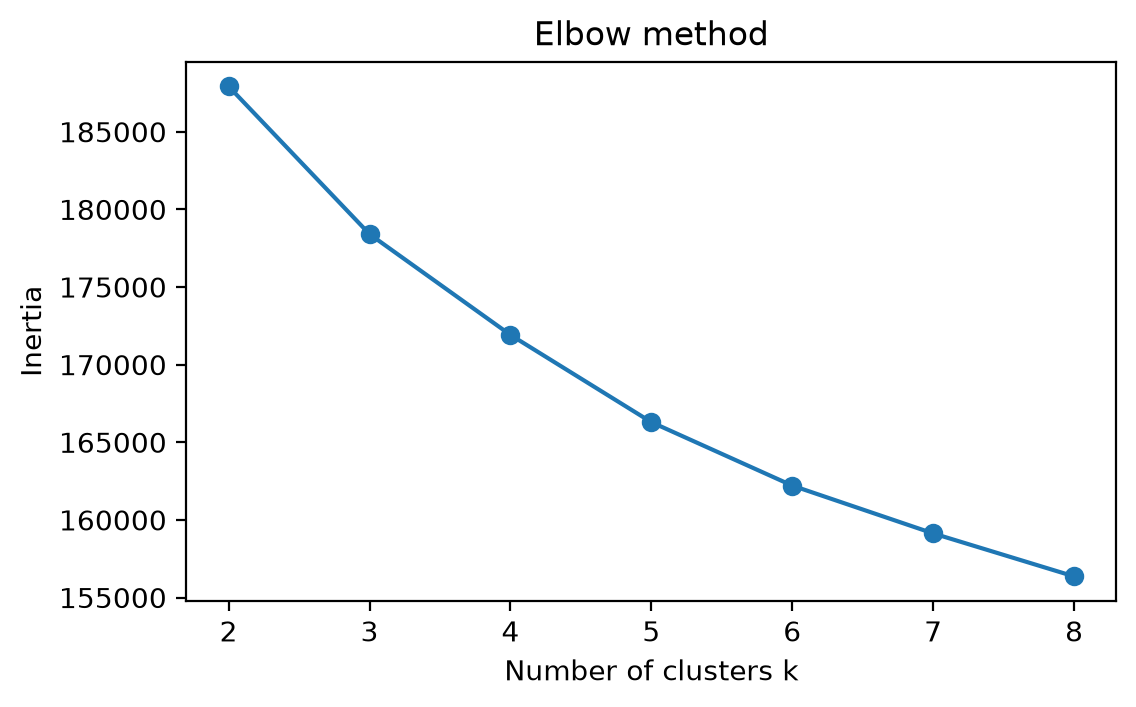

[187921, 178407, 171915, 166295, 162209, 159130, 156361]


In [59]:
components = PCA(n_components=n_components, random_state=RANDOM_STATE).fit_transform(technologies)

inertias = []
K_VALUES = range(2, 9)
for k in K_VALUES:
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(components).inertia_)

plt.figure(figsize=(6, 3.5))
plt.plot(K_VALUES, inertias, marker="o")
plt.title("Elbow method")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.show()
print([round(value) for value in inertias])

There is no clear elbow in the curve, which means the developers don't form well-separated groups. We still pick **k = 3**, which is a number of segments a sales team can actually work with.

In [60]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(components)
cluster = pd.Series(kmeans.labels_, index=technologies.index)

# Name of each cluster: its 3 technologies most above the average of all developers
cluster_names = {}
for c in range(3):
    difference = technologies[cluster == c].mean() - technologies.mean()
    top3 = [name.split("_", 1)[1] for name in difference.sort_values(ascending=False).head(3).index]
    cluster_names[c] = f"{c}: " + ", ".join(top3)
persona = cluster.map(cluster_names).rename("persona")
persona.value_counts()

persona
1: C++, C, Assembly                          12246
0: npm, Docker, Node.js                       8905
2: C#, ASP.NET Core, Microsoft SQL Server     3858
Name: count, dtype: int64

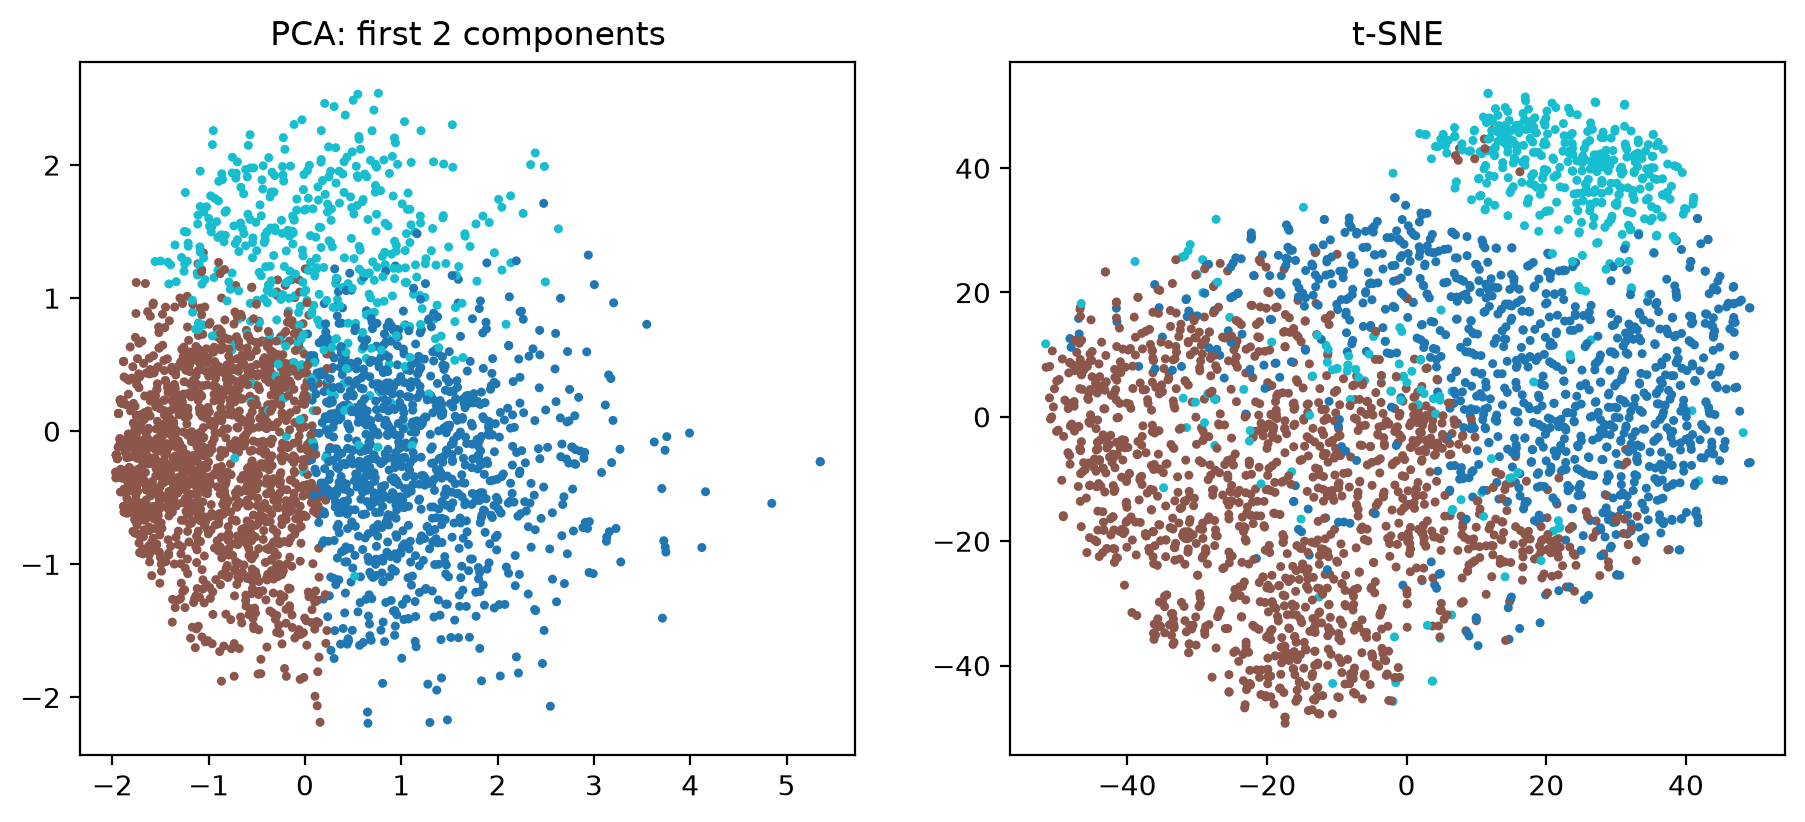

In [61]:
sample = np.random.default_rng(RANDOM_STATE).choice(len(components), size=3000, replace=False)
embedding = TSNE(n_components=2, random_state=RANDOM_STATE).fit_transform(components[sample])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(components[sample, 0], components[sample, 1], c=kmeans.labels_[sample], cmap="tab10", s=5)
axes[0].set_title("PCA: first 2 components")
axes[1].scatter(embedding[:, 0], embedding[:, 1], c=kmeans.labels_[sample], cmap="tab10", s=5)
axes[1].set_title("t-SNE")
plt.show()

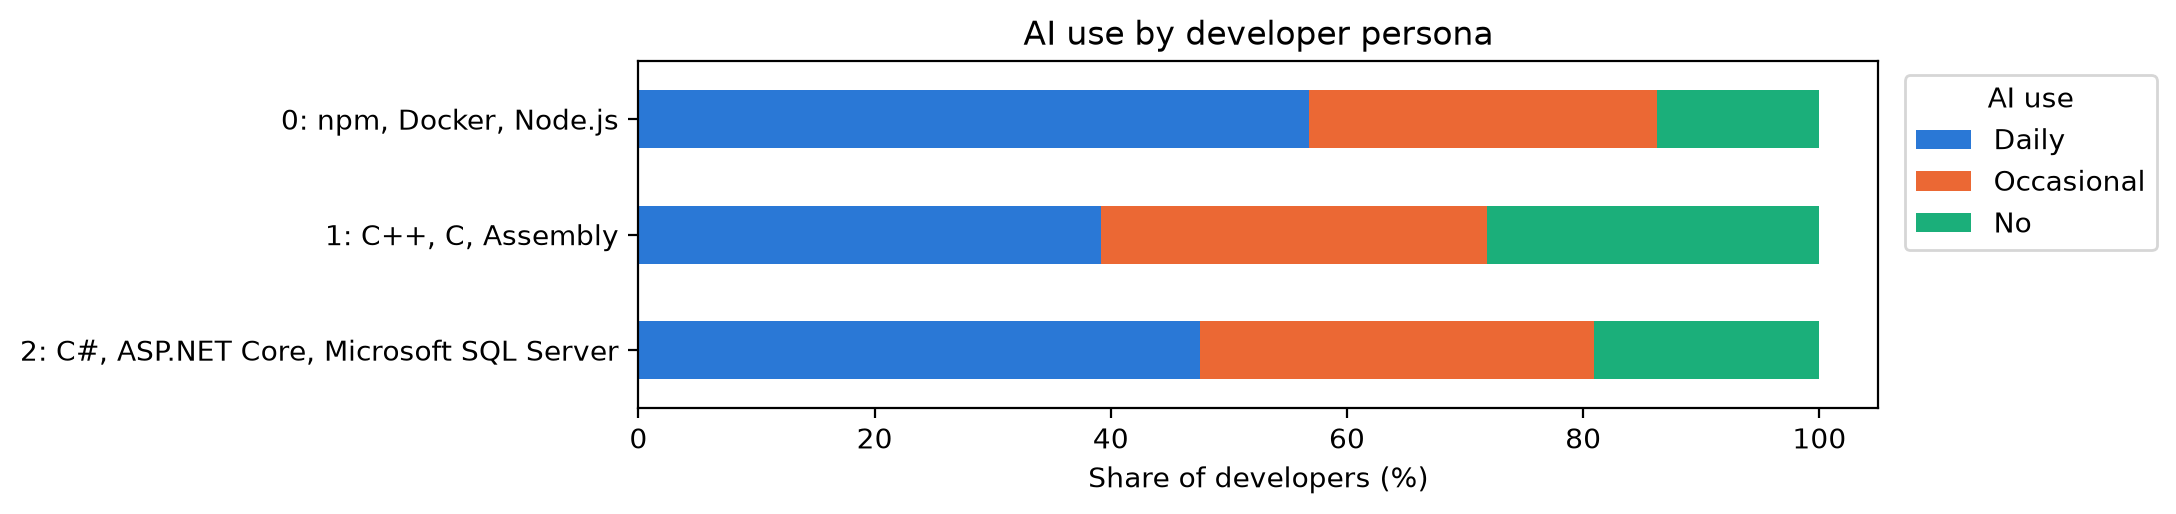

AISelect,Daily,Occasional,No
persona,,,
"0: npm, Docker, Node.js",56.8,29.4,13.8
"1: C++, C, Assembly",39.1,32.7,28.1
"2: C#, ASP.NET Core, Microsoft SQL Server",47.5,33.4,19.1


In [62]:
plot_class_shares(persona, "AI use by developer persona")

We need 41 components to explain 80% of the variance, so even with only the 77 frequent technologies, stacks are hard to summarize in a few dimensions. Together with the missing elbow and the t-SNE plot, where the groups touch each other in one big cloud, this shows that the personas overlap a lot.

Still, the groups differ in their AI use. Group 0 (web / JavaScript: npm, Docker, Node.js) uses AI daily the most (57%). Group 1 (C, C++, Assembly) is the largest and most mixed; it uses AI the least (39% daily) and has the most "No" (28%). Group 2 (.NET: C#, ASP.NET, SQL Server) is in between. Once again, though, the share of Occasional is almost the same in the 3 groups (29–33%). The personas are a nice way to describe the market, but they don't really help to find the Occasional users. One more limit: k-means uses the Euclidean distance, which is not ideal for 0/1 data like ours.

### 3.11 Hyperparameter tuning

We keep a short-list of 3 models of different types that give probabilities (needed to sort the contacts and for the ensemble): logistic regression (linear), gradient boosting (trees built one after the other, boosting) and random forest (trees built independently, bagging). The linear SVM was third in 3.2, but `LinearSVC` doesn't give probabilities, so we take the random forest instead.

We use `RandomizedSearchCV` with 15 random combinations, 5 folds and macro-F1. We chose random search because, for the same cost, it tries more different values than a grid search, and here each model has 4–6 hyperparameters. The values are drawn with `loguniform` from SciPy: it picks numbers evenly on a log scale, which is what we want for values like C that can go from 0.001 to 100. We also tune one preparation choice: whether missing numbers are filled with the mean or the median.

In our first version, some of the best values ended up at the edge of the ranges (a learning rate close to 0.3). So we made the ranges wider.

In [63]:
SEARCH_SPACES = {
    "Logistic regression": (LogisticRegression(max_iter=3000), {
        "prep__num__imputer__strategy": ["mean", "median"],
        "model__C": loguniform(1e-3, 1e2),
        "model__class_weight": [None, "balanced"],
    }),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), {
        "prep__num__imputer__strategy": ["mean", "median"],
        "model__learning_rate": loguniform(1e-2, 1),
        "model__max_depth": [3, 5, 8, 12],
        "model__min_samples_leaf": [10, 20, 50, 100, 200],
        "model__class_weight": [None, "balanced"],
    }),
    "Random forest": (RandomForestClassifier(random_state=RANDOM_STATE), {
        "prep__num__imputer__strategy": ["mean", "median"],
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, 12, 20, None],
        "model__min_samples_leaf": [1, 5, 20, 50],
        "model__max_features": ["sqrt", 0.3],
        "model__class_weight": [None, "balanced"],
    }),
}

searches = {}
for name, (model, space) in SEARCH_SPACES.items():
    search = RandomizedSearchCV(make_pipeline_for(model), space, n_iter=15, cv=CV, scoring="f1_macro",
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name}: best macro-F1 {search.best_score_:.3f}")
    print("   ", search.best_params_)

Logistic regression: best macro-F1 0.472
    {'model__C': np.float64(0.028888383623653185), 'model__class_weight': 'balanced', 'prep__num__imputer__strategy': 'mean'}


Gradient boosting: best macro-F1 0.473
    {'model__class_weight': 'balanced', 'model__learning_rate': np.float64(0.10968217207529521), 'model__max_depth': 5, 'model__min_samples_leaf': 100, 'prep__num__imputer__strategy': 'median'}


/tmp/claude-0/-home-claude/2a30a981-cd5b-541a-8d69-455c583c9271/scratchpad/venv16/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random forest: best macro-F1 0.461
    {'prep__num__imputer__strategy': 'mean', 'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}


The tuning brings a little: logistic regression goes from 0.460 to 0.472 (mostly thanks to the class weights), gradient boosting from 0.458 to 0.473 and the random forest from 0.423 to 0.461. All three chose balanced class weights. Logistic regression chose a small C (≈ 0.03), i.e. a strong regularization, which fits with a weak signal spread over many features. The random forest chose deep trees (no depth limit) but with at least 5 developers per leaf, which limits overfitting.

With the wider ranges, the best values are inside them (learning rate 0.11, depth 5, C ≈ 0.03). The random forest chose 100 trees, the smallest value we tried; more trees usually don't hurt a random forest, so this is probably just noise between very close scores.

(The warnings printed by joblib here and in 3.9 only say that a parallel worker was restarted, because of the memory used; they don't change the results.)

### 3.12 Overfitting and underfitting

We take the decision tree and measure macro-F1 for several maximum depths with `validation_curve`. Like `learning_curve` below, it runs the 5-fold cross-validation for us and gives both the training score and the validation score.

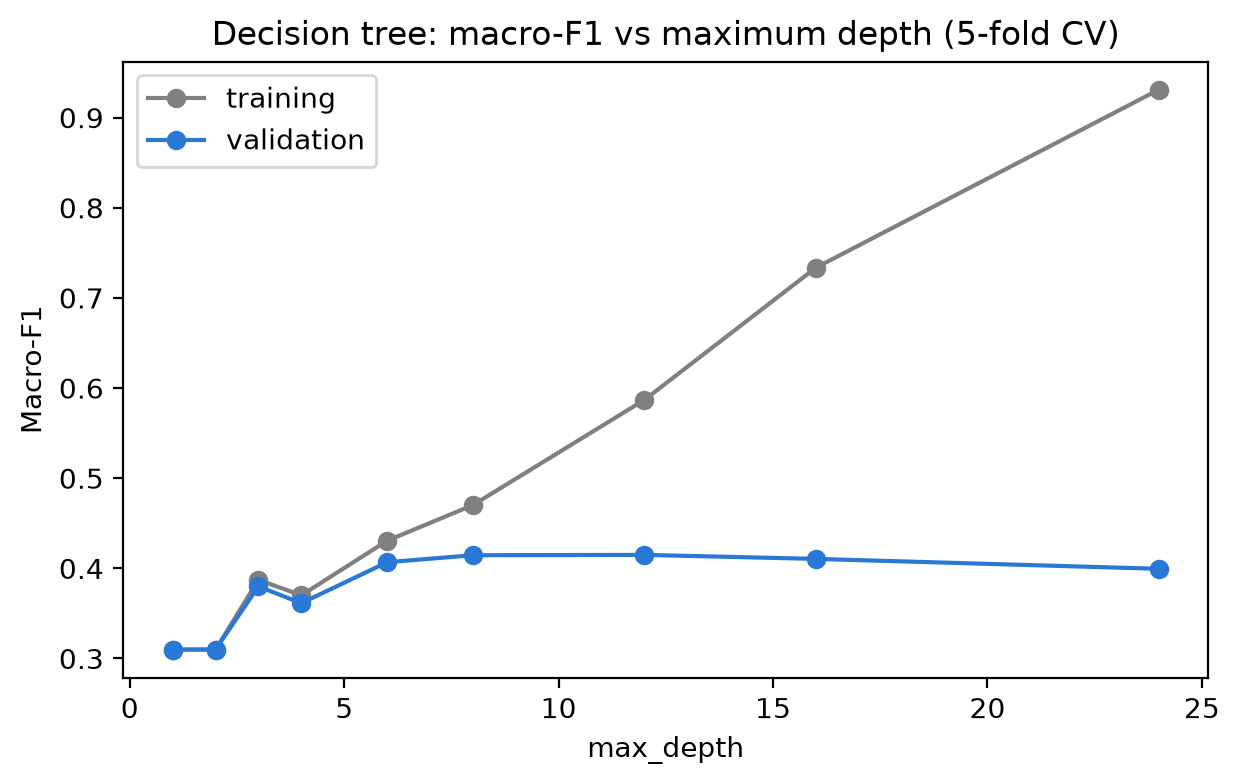

Best depth on the validation folds: 12


,1,2,3,4,6,8,12,16,24
training,0.31,0.31,0.387,0.370,0.431,0.470,0.587,0.734,0.931
validation,0.31,0.31,0.380,0.361,0.407,0.415,0.415,0.410,0.399


In [64]:
DEPTHS = [1, 2, 3, 4, 6, 8, 12, 16, 24]
tree = make_pipeline_for(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
train_scores, valid_scores = validation_curve(tree, X_train, y_train, param_name="model__max_depth",
                                              param_range=DEPTHS, cv=CV, scoring="f1_macro", n_jobs=-1)
train_mean = train_scores.mean(axis=1)
valid_mean = valid_scores.mean(axis=1)

plt.figure(figsize=(7, 4))
plt.plot(DEPTHS, train_mean, marker="o", color="grey", label="training")
plt.plot(DEPTHS, valid_mean, marker="o", color=CLASS_COLORS[0], label="validation")
plt.title("Decision tree: macro-F1 vs maximum depth (5-fold CV)")
plt.xlabel("max_depth")
plt.ylabel("Macro-F1")
plt.legend()
plt.show()
print("Best depth on the validation folds:", DEPTHS[np.argmax(valid_mean)])
pd.DataFrame({"training": train_mean, "validation": valid_mean}, index=DEPTHS).round(3).T

The plot shows both problems. With a depth of 1 or 2, the score is low on both parts (0.31), so the tree **underfits**. From depth 8 on, the training score keeps going up (0.93 at depth 24) while the validation score stays around 0.40–0.42, so the tree **overfits**. The best validation scores are at depth 8 and 12 (0.415). This also explains why the tree without a depth limit was the weakest model in 3.2.

**Learning curve.** Another way to look at this: how does the score change when the model sees more training data? We use the balanced logistic regression and train it on 5% to 100% of each training fold (`learning_curve`, 5 folds).

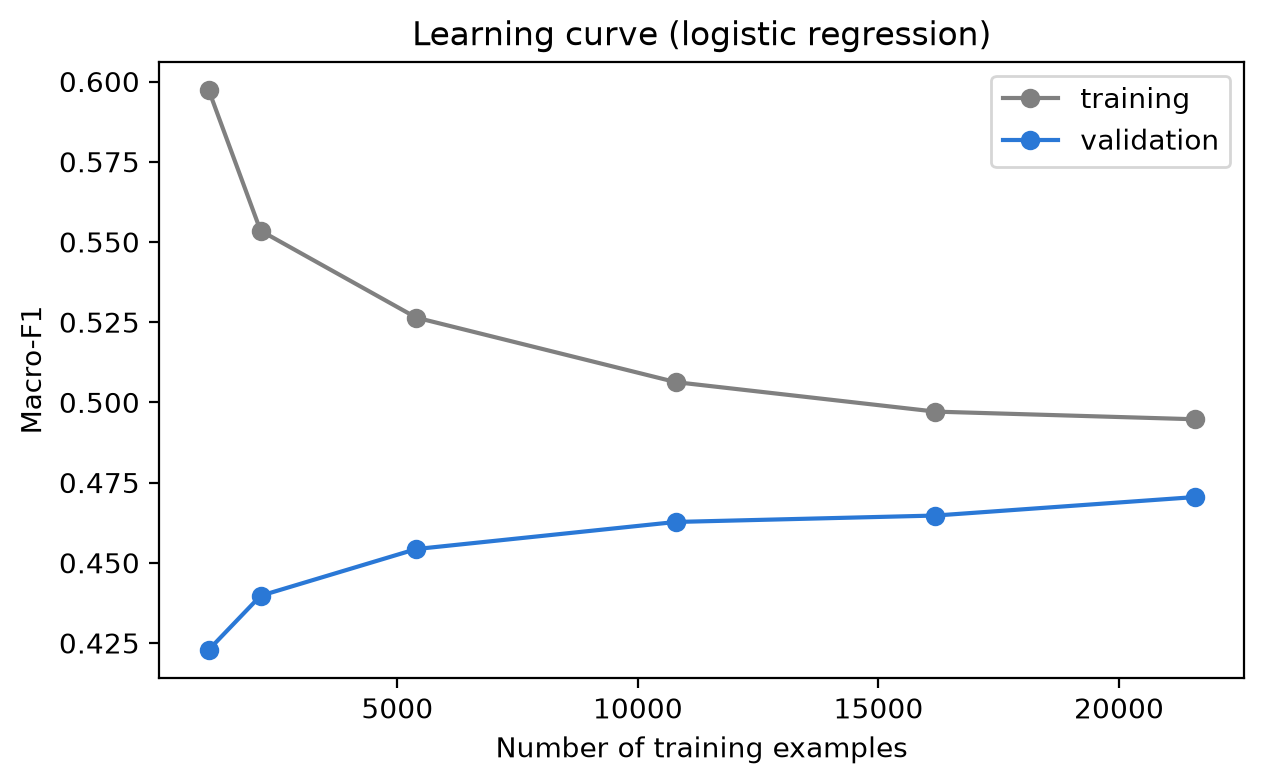

,1079,2158,5395,10790,16185,21580
training,0.597,0.554,0.526,0.506,0.497,0.495
validation,0.423,0.440,0.454,0.463,0.465,0.470


In [65]:
sizes, lc_train, lc_valid = learning_curve(
    make_pipeline_for(LogisticRegression(max_iter=2000, class_weight="balanced")), X_train, y_train,
    train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0], cv=CV, scoring="f1_macro", n_jobs=-1)

plt.figure(figsize=(7, 4))
plt.plot(sizes, lc_train.mean(axis=1), marker="o", color="grey", label="training")
plt.plot(sizes, lc_valid.mean(axis=1), marker="o", color=CLASS_COLORS[0], label="validation")
plt.title("Learning curve (logistic regression)")
plt.xlabel("Number of training examples")
plt.ylabel("Macro-F1")
plt.legend()
plt.show()
pd.DataFrame({"training": lc_train.mean(axis=1), "validation": lc_valid.mean(axis=1)}, index=sizes).round(3).T

With only about 1,000 examples the training score is high (0.60) and the validation score is low (0.42), so the model overfits. As we add data the two curves get closer, and with all the data they are at 0.50 and 0.47.

The validation curve is still going up slowly at the end (0.465 → 0.470 for the last 5,000 examples), so more data of the same kind could help a little. But the gap between the two curves is already small, and the training score itself is only 0.50: even on the data it has seen, the model can't do much better. More rows would not change much; what is missing are more informative features, as Q2 (3.9) showed.

### 3.13 Ensemble and final choice

We combine the 3 tuned models with **soft voting** (`VotingClassifier`): it averages their probabilities and takes the most probable class.

There is one issue with comparing them directly: the scores of 3.11 are a bit optimistic, because each one is the best of 15 tries on the same folds. To make the comparison fair, we use **new folds** (`StratifiedKFold` with another random seed, i.e. a different split of the training set that keeps the class proportions) with `cross_val_predict`, and we compute macro-F1 on each of the 5 folds. The same predictions also let us check whether the models make **different errors**, since an ensemble helps more when its models don't make the same mistakes.

To choose the final model, we fix a rule before looking at the result: **we take the simplest model whose score is within one standard deviation of the best one** (from simplest to most complex: logistic regression, random forest, gradient boosting, ensemble). In this way we don't choose a more complex model for a difference that could just be noise.

In [66]:
fresh_cv = StratifiedKFold(n_splits=CV, shuffle=True, random_state=1)   # new folds, not used for tuning

candidates_models = {name: search.best_estimator_ for name, search in searches.items()}
candidates_models["Ensemble (soft voting)"] = VotingClassifier(
    [(name, search.best_estimator_) for name, search in searches.items()], voting="soft")

cv_predictions = {}
fold_scores = {}
for name, model in candidates_models.items():
    cv_predictions[name] = cross_val_predict(model, X_train, y_train, cv=fresh_cv, n_jobs=-1)
    # macro-F1 on each of the 5 new folds
    fold_scores[name] = [f1_score(y_train.iloc[valid], cv_predictions[name][valid], average="macro")
                         for _, valid in fresh_cv.split(X_train, y_train)]

candidates = pd.DataFrame({"macro_f1_mean": [np.mean(s) for s in fold_scores.values()],
                           "macro_f1_std": [np.std(s) for s in fold_scores.values()]},
                          index=list(fold_scores)).sort_values("macro_f1_mean", ascending=False)
candidates.round(3)

,macro_f1_mean,macro_f1_std
Ensemble (soft voting),0.479,0.004
Gradient boosting,0.473,0.005
Logistic regression,0.473,0.003
Random forest,0.461,0.005


In [67]:
# Do the 3 tuned models make different errors?
names = list(searches)
rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = cv_predictions[names[i]], cv_predictions[names[j]]
        rows.append({"model 1": names[i], "model 2": names[j],
                     "different predictions (%)": (a != b).mean() * 100,
                     "both wrong (%)": ((a != y_train) & (b != y_train)).mean() * 100})
pd.DataFrame(rows).round(1)

,model 1,model 2,different predictions (%),both wrong (%)
0,Logistic regression,Gradient boosting,21.4,42.1
1,Logistic regression,Random forest,30.1,38.3
2,Gradient boosting,Random forest,27.7,39.1


In [68]:
# Rule fixed in advance: the simplest model whose score is within one standard deviation of the best one
SIMPLEST_FIRST = ["Logistic regression", "Random forest", "Gradient boosting", "Ensemble (soft voting)"]
best_name = candidates.index[0]
threshold = candidates.loc[best_name, "macro_f1_mean"] - candidates.loc[best_name, "macro_f1_std"]
FINAL_NAME = [name for name in SIMPLEST_FIRST if candidates.loc[name, "macro_f1_mean"] >= threshold][0]
print(f"Best: {best_name}; threshold = {threshold:.3f}")
print("Final model:", FINAL_NAME)

final_model = candidates_models[FINAL_NAME].fit(X_train, y_train)
joblib.dump(final_model, "final_model.joblib")   # checklist: keep traces of the experiments

Best: Ensemble (soft voting); threshold = 0.475
Final model: Ensemble (soft voting)


['final_model.joblib']

On the new folds, the ensemble gets **0.479 ± 0.004**, against 0.473 for gradient boosting and logistic regression and 0.461 for the random forest. The threshold of the rule is 0.479 − 0.004 = 0.475, and no single model reaches it, so **the final model is the ensemble**. This time the gain (+0.006) is larger than one standard deviation.

The error table shows why adding the random forest helps: logistic regression and gradient boosting make similar errors (they disagree on only 21% of the rows), while the random forest is more different (28–30% of different predictions). Even so, the gain stays small: all the models make many errors in common (both wrong on 38–42% of the rows).

### 3.14 Calibration of the probabilities

Our final model gives 3 probabilities for each developer, and the sales team will use them. A probability is **calibrated** when it tells the truth: among all the developers who get P(No) = 0.40, about 40% should really be "No".

There is a reason to expect a problem here. We trained our models with `class_weight="balanced"` (3.6): errors on the small classes cost more, so the model finds them more often, which is good for macro-F1. But it also pushes the probabilities of the small classes (No, Occasional) up, and the one of the big class (Daily) down. So the probabilities may be **too high for No and too low for Daily**.

For sorting the contacts this doesn't matter, because the order stays the same. But it matters as soon as the numbers are read as real chances, for example to plan the work: "in this list of 1,000 contacts, how many non-users can we expect?" is just the sum of P(No). With inflated probabilities the answer would be wrong.

**The fix: `CalibratedClassifierCV`.** The model is trained on part of the training data, and on the other part we learn a small function that turns its probabilities into "true" ones, by comparing the predicted probabilities with what really happened. We repeat this on 3 folds and average. Two shapes are possible for that function:
- **sigmoid** (Platt scaling): an S-shaped curve; few parameters, but a fixed shape;
- **isotonic**: any increasing step function; more flexible, and usually better when there is a lot of data (we have about 27,000 rows).

Because the function is increasing, a contact with a higher probability keeps a higher probability: the order of the list is (almost) unchanged.

**How we decide, on the training set only.** We compare the 3 versions (not calibrated, sigmoid, isotonic) with `cross_val_predict` on the new folds of 3.13. To measure calibration we use the same idea as the calibration plot of 4.4: for each class we cut the developers into 10 groups by predicted probability, and we compute the average distance between the predicted probability and the real share of the class (the **calibration gap**: 0 means perfect). We also check that macro-F1 and AUC don't get worse. The rule, fixed in advance: we keep the version with the smallest calibration gap.

In [69]:
def calibration_gap(proba, y_true, classes):
    # Average distance between the predicted probability and the real share of the class,
    # over 10 groups of equal size for each class (0 = perfect calibration)
    gaps = []
    for k, cls in enumerate(classes):
        p = pd.Series(proba[:, k], index=y_true.index)
        group = pd.qcut(p, q=10, duplicates="drop")
        predicted = p.groupby(group, observed=True).mean()
        observed = (y_true == cls).groupby(group, observed=True).mean()
        gaps.append((predicted - observed).abs().mean())
    return np.mean(gaps)


final_choice = candidates_models[FINAL_NAME]
CALIBRATION_VERSIONS = {
    "Not calibrated": final_choice,
    "Calibrated, sigmoid": CalibratedClassifierCV(final_choice, method="sigmoid", cv=3),
    "Calibrated, isotonic": CalibratedClassifierCV(final_choice, method="isotonic", cv=3),
}
classes = sorted(y_train.unique())        # the columns of predict_proba are in alphabetical order

cv_proba = {}
rows = []
for name, model in CALIBRATION_VERSIONS.items():
    proba = cross_val_predict(model, X_train, y_train, cv=fresh_cv, method="predict_proba", n_jobs=-1)
    cv_proba[name] = proba
    pred = np.array(classes)[proba.argmax(axis=1)]
    row = {"version": name, "calibration gap": calibration_gap(proba, y_train, classes),
           "macro-F1": f1_score(y_train, pred, average="macro")}
    for k, cls in enumerate(classes):
        row[f"mean P({cls})"] = proba[:, k].mean()
    for k, cls in enumerate(classes):
        row[f"AUC {cls}"] = roc_auc_score(y_train == cls, proba[:, k])
    rows.append(row)

calibration_table = pd.DataFrame(rows).set_index("version")
print("Real shares in the training set:", y_train.value_counts(normalize=True).round(3).to_dict())
calibration_table.round(3)

Real shares in the training set: {'Daily': 0.471, 'Occasional': 0.314, 'No': 0.215}


,calibration gap,macro-F1,mean P(Daily),mean P(No),mean P(Occasional),AUC Daily,AUC No,AUC Occasional
version,,,,,,,,
Not calibrated,0.069,0.479,0.368,0.299,0.333,0.720,0.747,0.581
"Calibrated, sigmoid",0.014,0.453,0.465,0.218,0.317,0.719,0.747,0.589
"Calibrated, isotonic",0.010,0.445,0.465,0.220,0.315,0.718,0.746,0.589


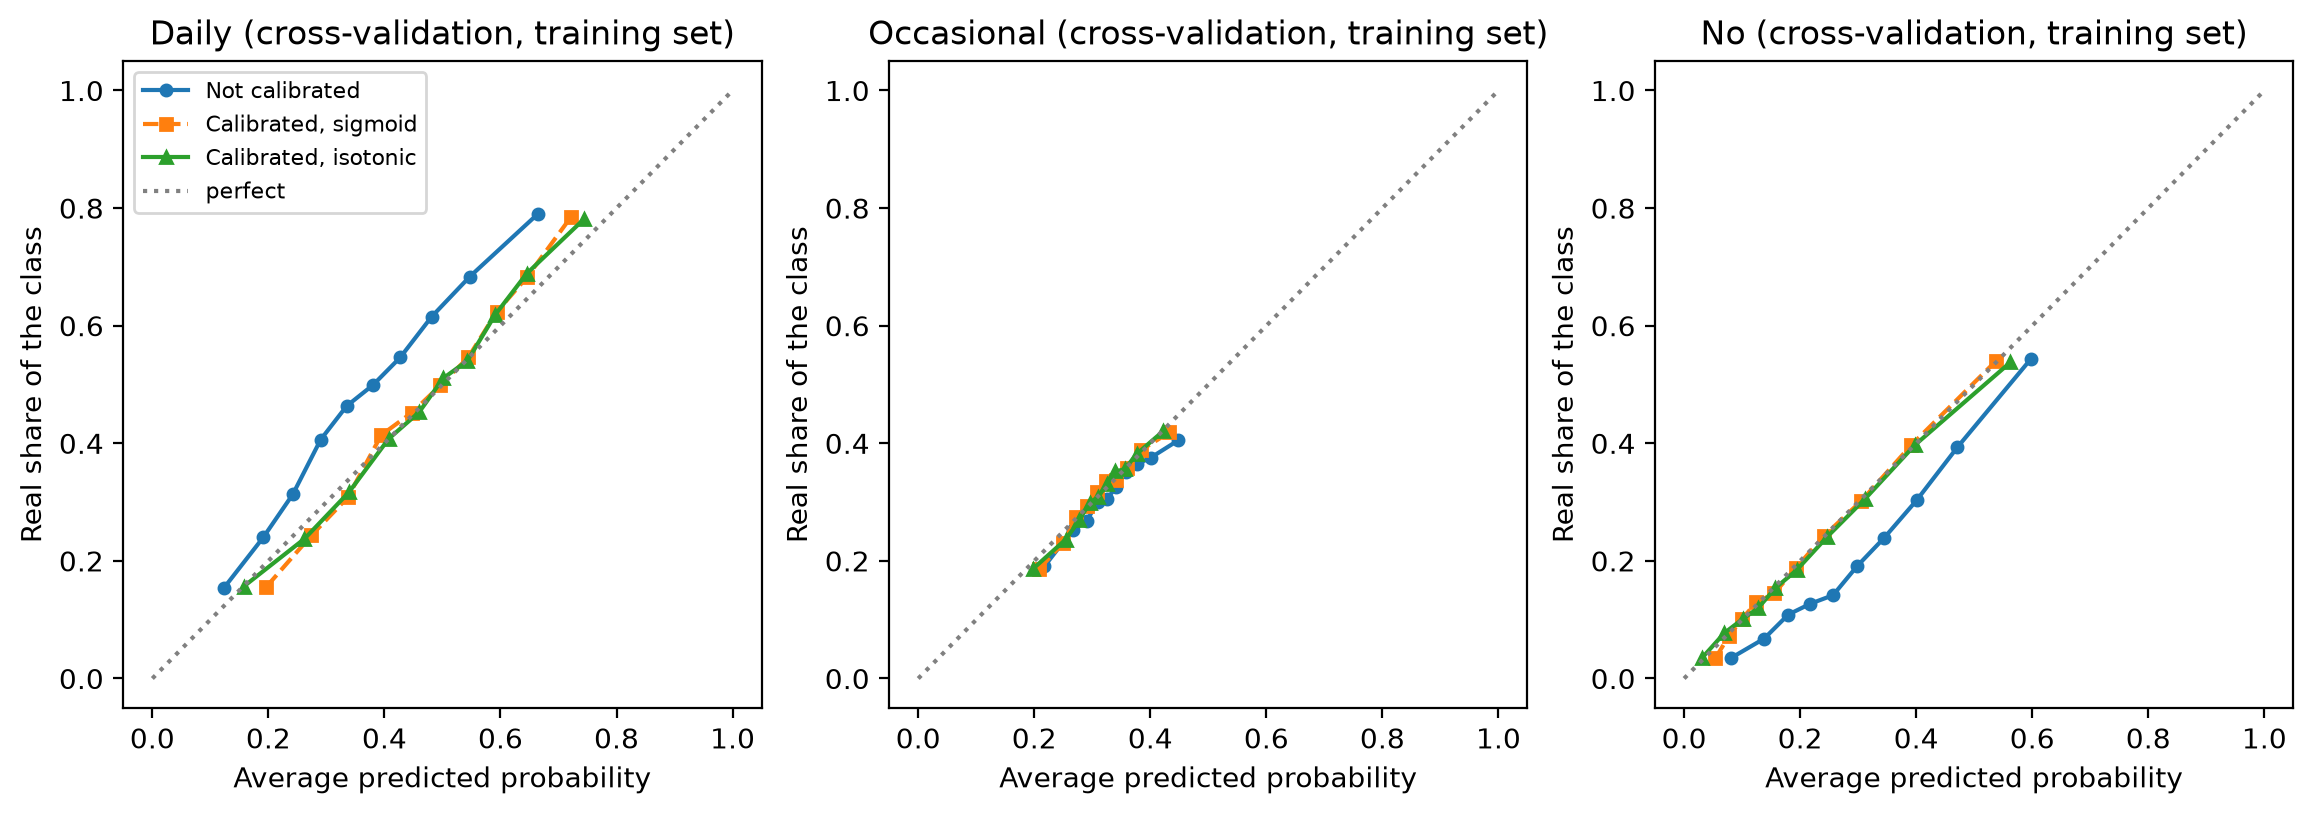

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, cls in zip(axes, CLASS_ORDER):
    k = classes.index(cls)
    for name, style in zip(CALIBRATION_VERSIONS, ["o-", "s--", "^-"]):
        p = pd.Series(cv_proba[name][:, k], index=y_train.index)
        group = pd.qcut(p, q=10, duplicates="drop")
        ax.plot(p.groupby(group, observed=True).mean(), (y_train == cls).groupby(group, observed=True).mean(),
                style, label=name, markersize=4)
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect")
    ax.set_title(f"{cls} (cross-validation, training set)")
    ax.set_xlabel("Average predicted probability")
    ax.set_ylabel("Real share of the class")
axes[0].legend(fontsize=8)
plt.show()

In [71]:
CALIBRATION = calibration_table["calibration gap"].idxmin()     # rule fixed in advance
print("Chosen version:", CALIBRATION)
if CALIBRATION == "Not calibrated":
    calibrated_model = final_model
else:
    calibrated_model = CALIBRATION_VERSIONS[CALIBRATION].fit(X_train, y_train)

Chosen version: Calibrated, isotonic


The calibration fixes the problem. The calibration gap goes from 0.069 without calibration to 0.014 with the sigmoid and **0.010 with the isotonic** version. On average, P(No) goes from 0.299 to 0.220 (real share 0.215) and P(Daily) from 0.368 to 0.465 (real share 0.471). In the plots, the calibrated curves lie on the diagonal, while the original one is below it for No and above it for Daily, exactly as we expected from the class weights.

The AUCs stay the same (Daily 0.720 → 0.718, No 0.747 → 0.746, Occasional 0.581 → 0.589): the order of the contacts doesn't change, so the ranking of 4.3 is not affected.

But macro-F1 drops (0.479 → 0.445). This is normal: with "true" probabilities, the most probable class is more often Daily, the big class, which is precisely what the class weights were correcting. So the two versions are good at two different jobs, and we use each one for its job:
- the **final model** (not calibrated) to predict the class of each developer and to sort the list (macro-F1, precision@k, AUC in 4.1–4.3);
- the **calibrated model** only for the probabilities that the sales team reads as real chances (4.4).

Following our rule, we keep the **isotonic** version (smallest calibration gap). It is trained on the whole training set now, before looking at the test set.

## 4. Evaluation

We use the test set **only here, once**, after all the choices, which were all made with cross-validation on the training set. Nothing is changed afterwards.

### 4.1 Test set

In [72]:
X_test = prepare_features(test_set[OBSERVABLE_COLS])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # options never seen in training -> 0

test_pred = final_model.predict(X_test)
rule_pred = salesperson_rule(test_set)
dummy_pred = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)

print(classification_report(y_test, test_pred, labels=CLASS_ORDER, digits=3))
print("Macro-F1 on the test set:")
print("  final model:            ", round(f1_score(y_test, test_pred, average="macro"), 3))
print("  rule of the salesperson:", round(f1_score(y_test, rule_pred, average="macro"), 3))
print("  most frequent class:    ", round(f1_score(y_test, dummy_pred, average="macro"), 3))

              precision    recall  f1-score   support

       Daily      0.629     0.634     0.631      3177
  Occasional      0.384     0.264     0.313      2117
          No      0.387     0.557     0.457      1450

    accuracy                          0.501      6744
   macro avg      0.467     0.485     0.467      6744
weighted avg      0.500     0.501     0.494      6744

Macro-F1 on the test set:
  final model:             0.467
  rule of the salesperson: 0.383
  most frequent class:     0.213


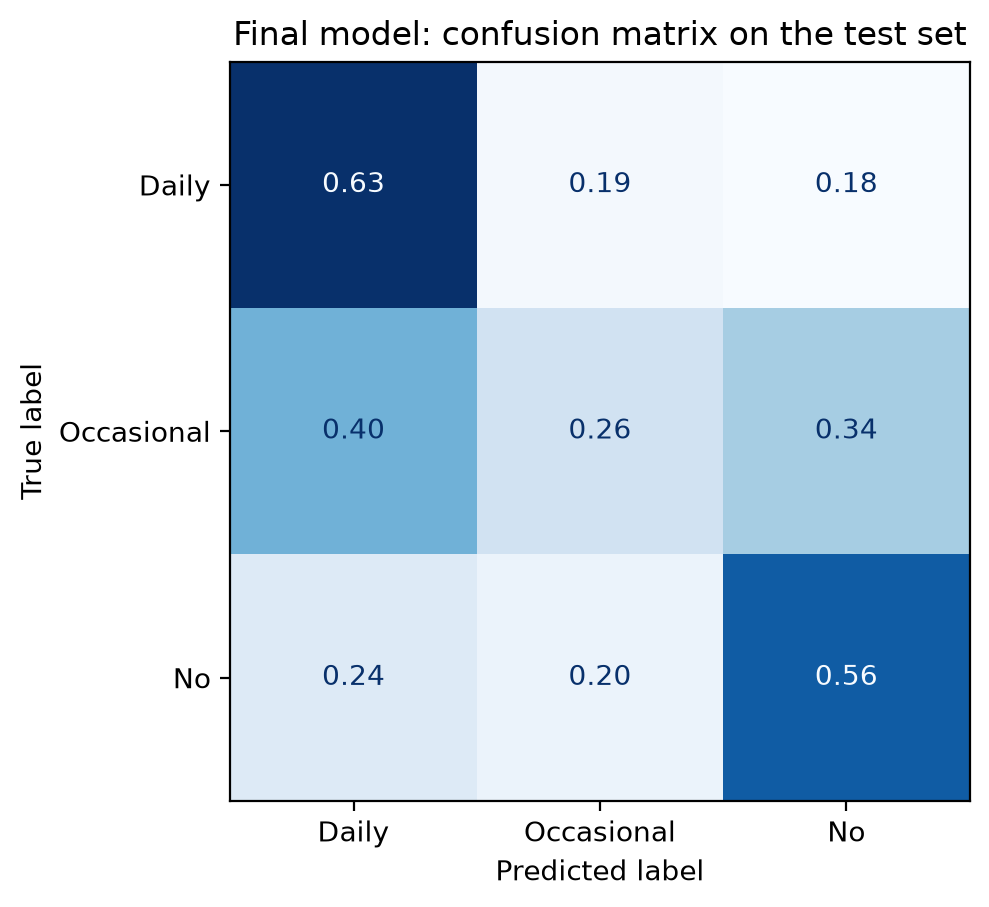

            Daily  Occasional    No
Daily        0.63        0.19  0.18
Occasional   0.40        0.26  0.34
No           0.24        0.20  0.56


In [73]:
display_test = ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=CLASS_ORDER, normalize="true",
                                                       values_format=".2f", cmap="Blues", colorbar=False)
plt.title("Final model: confusion matrix on the test set")
plt.show()
print(pd.DataFrame(display_test.confusion_matrix, index=CLASS_ORDER, columns=CLASS_ORDER).round(2))

On the test set the final model gets a macro-F1 of **0.467** (accuracy 0.501). This is a bit lower than the cross-validation score (0.479), but still clearly better than the human rule (0.383) and the most frequent class (0.213).

Looking at each class, Daily has an F1 of 0.631 and No 0.457, but **Occasional only 0.313**: 40% of the Occasional users are predicted as Daily and 34% as No. Compared with the default logistic regression of 3.5, the class weights make the model find many more "No" (56% instead of 36%), but it also puts more people in "No" by mistake.

**Sensitivity and specificity.** For each class (one against the others), from the confusion matrix: sensitivity is the share of the class that the model finds, and specificity the share of the other developers that the model correctly does *not* put in this class.

In [74]:
counts = confusion_matrix(y_test, test_pred, labels=CLASS_ORDER)
rows = []
for k, cls in enumerate(CLASS_ORDER):
    tp = counts[k, k]
    fn = counts[k, :].sum() - tp
    fp = counts[:, k].sum() - tp
    tn = counts.sum() - tp - fn - fp
    rows.append({"class": cls, "sensitivity (recall)": tp / (tp + fn), "specificity": tn / (tn + fp)})
pd.DataFrame(rows).round(3)

,class,sensitivity (recall),specificity
0,Daily,0.634,0.666
1,Occasional,0.264,0.807
2,No,0.557,0.759


**Comparison with the state of the art.** The DEV article predicts "uses AI or not" with 94% accuracy. We can turn our predictions into the same 2 classes (Daily and Occasional become "uses AI") and compute the same metric.

In [75]:
uses_ai_real = y_test != "No"
uses_ai_pred = test_pred != "No"
print("Our model, accuracy on 'uses AI or not':", round((uses_ai_real == uses_ai_pred).mean(), 3))
print("Always answering 'uses AI':", round(uses_ai_real.mean(), 3))

Our model, accuracy on 'uses AI or not': 0.715
Always answering 'uses AI': 0.785


For specificity, Occasional is the highest (0.81): the model rarely puts other developers in this class by mistake, but it also finds few Occasional users (sensitivity 0.26). For No, the sensitivity is 0.56 and the specificity 0.76. Daily has a sensitivity of 0.63 and a specificity of 0.67.

On the 2-class task of the DEV article, our model gets an accuracy of 0.715, which is clearly lower than always answering "uses AI" (0.785). This is not really surprising: our model was trained with balanced class weights and chosen for macro-F1, so it predicts "No" much more often than a model built for accuracy would. But it also shows how far honest features are from 94%. For us this supports the idea that the AI questions were in their data: in 3.9, our own score jumps from 0.47 to 0.76 when we add them.

### 4.2 Confidence intervals (bootstrap)

We draw 1,000 samples of the test set with replacement, compute macro-F1 on each one, and take the 2.5th and 97.5th percentiles as a 95% confidence interval. Since we use the same samples for the final model and for the human rule, we can also get an interval for their **difference**. This second interval answers a more useful question: is the model really better than the rule, or could the gap just be luck?

Final model, 95% CI: [0.456 0.479]
Final model - rule, 95% CI: [0.068 0.101]


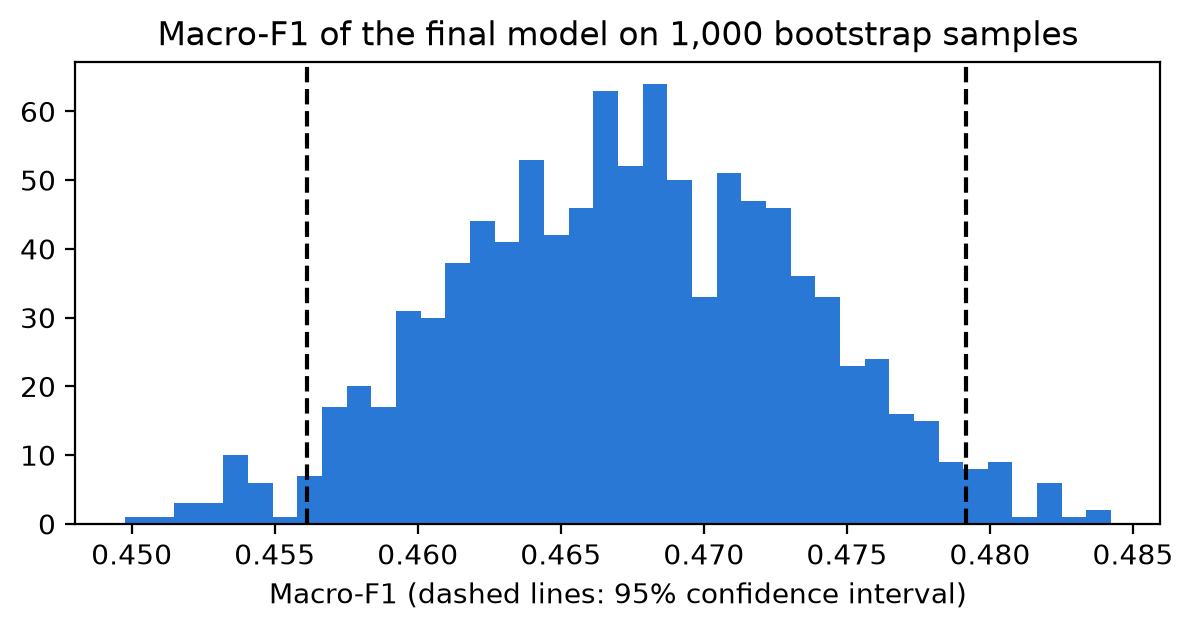

In [76]:
y_test_array = y_test.to_numpy()
rule_array = rule_pred.to_numpy()
rng = np.random.default_rng(RANDOM_STATE)

boot_model = []
boot_rule = []
for _ in range(1000):
    i = rng.integers(0, len(y_test_array), len(y_test_array))     # row numbers drawn with replacement
    boot_model.append(f1_score(y_test_array[i], test_pred[i], average="macro"))
    boot_rule.append(f1_score(y_test_array[i], rule_array[i], average="macro"))
boot_model = np.array(boot_model)
boot_difference = boot_model - np.array(boot_rule)

print("Final model, 95% CI:", np.percentile(boot_model, [2.5, 97.5]).round(3))
print("Final model - rule, 95% CI:", np.percentile(boot_difference, [2.5, 97.5]).round(3))

plt.figure(figsize=(7, 3))
plt.hist(boot_model, bins=40, color=CLASS_COLORS[0])
for value in np.percentile(boot_model, [2.5, 97.5]):
    plt.axvline(value, color="black", linestyle="--")
plt.title("Macro-F1 of the final model on 1,000 bootstrap samples")
plt.xlabel("Macro-F1 (dashed lines: 95% confidence interval)")
plt.show()

The final model gets **0.467**, with a 95% confidence interval of [0.456; 0.479]. For the difference with the human rule the interval is [0.068; 0.101]. It doesn't contain 0, so the model is significantly better than the rule.

### 4.3 Business value

Macro-F1 doesn't tell the sales team much, so here we use two more concrete measures (they measure exactly what the sales team does: calling the top of a list):
- **precision@k:** we sort the test developers by the probability of a class, take the first k%, and look at the share that really belongs to that class;
- **lift:** precision@k divided by the share of the class in the whole test set, i.e. how much better than calling people at random.

In [77]:
proba = pd.DataFrame(final_model.predict_proba(X_test), columns=final_model.classes_, index=y_test.index)

rows = []
for cls in ["Occasional", "No"]:
    sorted_index = proba[cls].sort_values(ascending=False).index    # most probable first
    for share in [0.10, 0.20, 0.30]:
        top = sorted_index[:int(share * len(sorted_index))]
        precision = (y_test[top] == cls).mean()
        random_rate = (y_test == cls).mean()
        rows.append({"class": cls, "top": f"{share:.0%}", "precision@k": precision, "random": random_rate,
                     "lift": precision / random_rate})
pd.DataFrame(rows).round(3)

,class,top,precision@k,random,lift
0,Occasional,10%,0.381,0.314,1.215
1,Occasional,20%,0.384,0.314,1.222
2,Occasional,30%,0.387,0.314,1.231
3,No,10%,0.545,0.215,2.533
4,No,20%,0.459,0.215,2.136
5,No,30%,0.399,0.215,1.855


**ROC curves and AUC**, one class against the others. An AUC of 0.5 means a random order, and 1 a perfect order.

AUC Daily: 0.712
AUC Occasional: 0.584
AUC No: 0.736


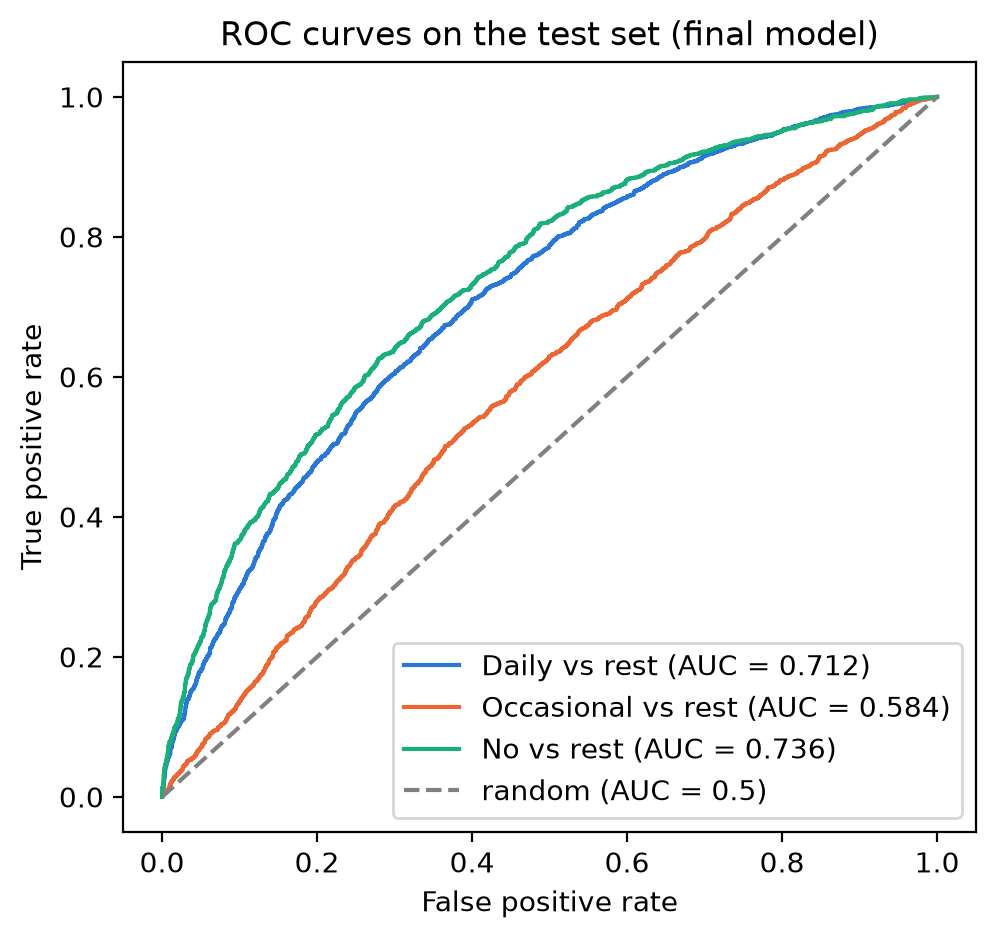

In [78]:
plt.figure(figsize=(5.5, 5))
for cls, color in zip(CLASS_ORDER, CLASS_COLORS):
    fpr, tpr, _ = roc_curve(y_test == cls, proba[cls])
    auc = roc_auc_score(y_test == cls, proba[cls])
    print(f"AUC {cls}: {auc:.3f}")
    plt.plot(fpr, tpr, color=color, label=f"{cls} vs rest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="random (AUC = 0.5)")
plt.title("ROC curves on the test set (final model)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.show()

For the people to **call last**, the model works quite well: in the top 10% by P(No), 55% are really "No", against 22% at random (lift 2.5). For the people to **call first** it is much weaker: in the top 10% by P(Occasional), 38% are Occasional against 31% at random (lift 1.2). The AUCs tell the same story: 0.712 for Daily and 0.736 for No, but **only 0.584 for Occasional**.

In practice, the model is mostly useful to push the non-users to the end of the list. Finding the Occasional users is still hard.

**Two-step use (funnel).** Since the model is better at spotting non-users than Occasional users, we tried a two-step approach:
1. put aside the 30% of the list with the highest P(No);
2. sort the rest by P(Occasional) / (P(Occasional) + P(Daily)), which roughly means "among AI users, who uses it the least".

In [79]:
step1_keep = proba["No"] < proba["No"].quantile(0.7)                         # step 1
occasional_share = proba["Occasional"] / (proba["Occasional"] + proba["Daily"])  # step 2

users = y_test != "No"
print("Share of No: whole list", round((y_test == "No").mean(), 3),
      "| after step 1", round((y_test[step1_keep] == "No").mean(), 3))
print("AUC Occasional vs Daily, among real AI users:",
      round(roc_auc_score(y_test[users] == "Occasional", occasional_share[users]), 3))

n_calls = int(0.10 * len(y_test))
top_direct = proba["Occasional"].sort_values(ascending=False).index[:n_calls]
top_funnel = occasional_share[step1_keep].sort_values(ascending=False).index[:n_calls]
print("Occasional in the first 10% of calls: direct ranking", round((y_test[top_direct] == "Occasional").mean(), 3),
      "| funnel", round((y_test[top_funnel] == "Occasional").mean(), 3))
print("No in the first 10% of calls: direct ranking", round((y_test[top_direct] == "No").mean(), 3),
      "| funnel", round((y_test[top_funnel] == "No").mean(), 3))

Share of No: whole list 0.215 | after step 1 0.136
AUC Occasional vs Daily, among real AI users: 0.664
Occasional in the first 10% of calls: direct ranking 0.381 | funnel 0.407
No in the first 10% of calls: direct ranking 0.184 | funnel 0.208


The first step works: the share of non-users in the list goes down from 21.5% to 13.6%. The second step also separates Occasional from Daily users better than the direct ranking separates Occasional from everyone (AUC 0.664 against 0.584).

In the first 10% of calls, the funnel finds a few more Occasional users: 40.7% against 38.1% with the direct ranking. The gain is small, and part of the non-users left after step 1 still come back to the top (21% of the first calls, against 18% with the direct ranking), because step 2 ignores P(No). So the funnel helps a little, but it doesn't solve our main problem: from a public profile, Occasional users can't be found much better than at random.

### 4.4 Are the probabilities reliable? (calibration)

Since we sort contacts by probability, we wanted to check whether these probabilities can be trusted. We sort the test developers by the predicted probability of each class, cut them into 10 groups of the same size, and compare, in each group, the average predicted probability with the real share of the class. If the probabilities are reliable, the points should lie on the diagonal.

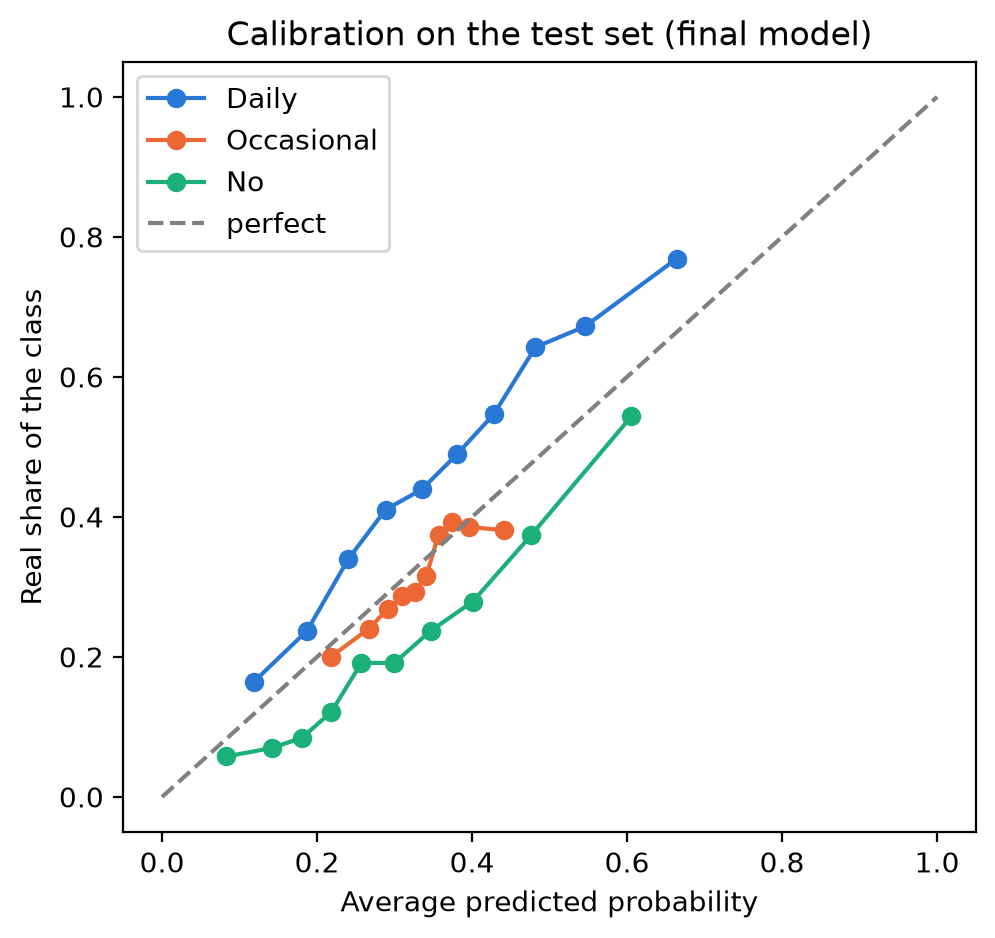

Average predicted probability vs real share on the test set:
            predicted   real
Daily           0.367  0.471
Occasional      0.332  0.314
No              0.301  0.215


In [80]:
plt.figure(figsize=(5.5, 5))
for cls, color in zip(CLASS_ORDER, CLASS_COLORS):
    group = pd.qcut(proba[cls], q=10, duplicates="drop")
    predicted = proba[cls].groupby(group, observed=True).mean()
    observed = (y_test == cls).groupby(group, observed=True).mean()
    plt.plot(predicted, observed, marker="o", color=color, label=cls)
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="perfect")
plt.title("Calibration on the test set (final model)")
plt.xlabel("Average predicted probability")
plt.ylabel("Real share of the class")
plt.legend()
plt.show()

print("Average predicted probability vs real share on the test set:")
print(pd.DataFrame({"predicted": proba[CLASS_ORDER].mean(), "real": y_test.value_counts(normalize=True)[CLASS_ORDER]}).round(3))

They are **not calibrated**. On average the model gives P(No) = 0.30 while only 21.5% of the developers are "No", and P(Daily) = 0.37 while 47% are "Daily". In the plot, the Daily curve is above the diagonal (its probabilities are too low) and the No curve is below it (too high). Occasional is close to the diagonal, but its probabilities never go above about 0.47, which shows that the model is never really confident about this class.

This is what we would expect from `class_weight="balanced"`: giving more weight to the small classes pushes their probabilities up. For **sorting** the contacts it doesn't matter, because the order (and so the AUC and precision@k) stays the same. But the numbers shouldn't be read as real chances, like "this developer has a 60% chance of being Occasional". This is why we prepared a calibrated version in 3.14, which we look at just below.

**The calibrated model on the test set.** Now we look at the probabilities of the calibrated model chosen in 3.14 (trained before looking at the test set, with a rule fixed in advance). The class predictions of 4.1–4.3 don't change: the calibrated probabilities are only used to read the numbers as real chances. As an example of business use, we also compute how many contacts of each class the sales team should expect in a list of 1,000 developers (the average probability × 1,000), and compare with the real number.

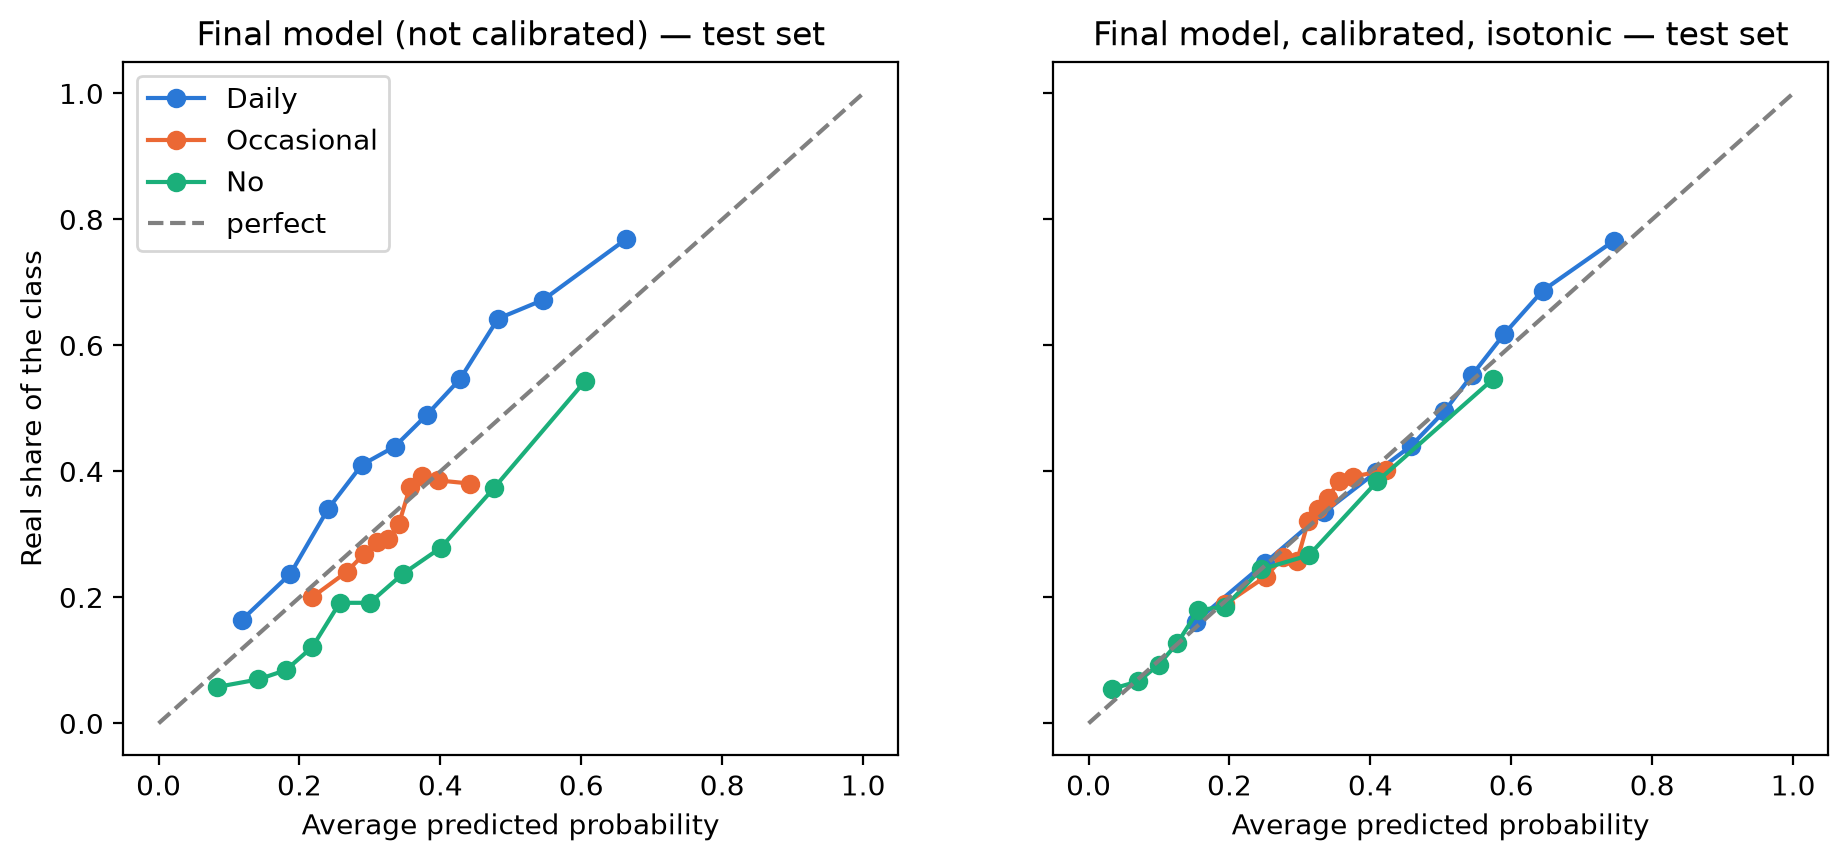

Contacts of each class in a list of 1,000 developers (test set):
            real number  expected, not calibrated  expected, calibrated
Daily             471.0                     367.0                 463.0
Occasional        314.0                     332.0                 315.0
No                215.0                     301.0                 222.0

Calibration gap on the test set: not calibrated 0.072 | calibrated 0.017
AUC Daily: not calibrated 0.712 | calibrated 0.712
AUC Occasional: not calibrated 0.584 | calibrated 0.592
AUC No: not calibrated 0.736 | calibrated 0.737


In [81]:
proba_cal = pd.DataFrame(calibrated_model.predict_proba(X_test), columns=calibrated_model.classes_, index=y_test.index)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (title, p_table) in zip(axes, [("Final model (not calibrated)", proba), (f"Final model, {CALIBRATION.lower()}", proba_cal)]):
    for cls, color in zip(CLASS_ORDER, CLASS_COLORS):
        group = pd.qcut(p_table[cls], q=10, duplicates="drop")
        ax.plot(p_table[cls].groupby(group, observed=True).mean(), (y_test == cls).groupby(group, observed=True).mean(),
                marker="o", color=color, label=cls)
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="perfect")
    ax.set_title(title + " — test set")
    ax.set_xlabel("Average predicted probability")
axes[0].set_ylabel("Real share of the class")
axes[0].legend()
plt.show()

comparison = pd.DataFrame({
    "real number": y_test.value_counts(normalize=True)[CLASS_ORDER] * 1000,
    "expected, not calibrated": proba[CLASS_ORDER].mean() * 1000,
    "expected, calibrated": proba_cal[CLASS_ORDER].mean() * 1000,
}).round(0)
print("Contacts of each class in a list of 1,000 developers (test set):")
print(comparison)
print()
print("Calibration gap on the test set: not calibrated", round(calibration_gap(proba[classes].to_numpy(), y_test, classes), 3),
      "| calibrated", round(calibration_gap(proba_cal[classes].to_numpy(), y_test, classes), 3))
for cls in CLASS_ORDER:
    print(f"AUC {cls}: not calibrated {roc_auc_score(y_test == cls, proba[cls]):.3f} | calibrated {roc_auc_score(y_test == cls, proba_cal[cls]):.3f}")

On the test set the calibration works as it did in cross-validation. The calibration gap goes from 0.072 to **0.017**, and in the right plot the three curves lie on the diagonal.

The example of the list of 1,000 contacts shows why this matters for the sales team. Without calibration, the model would expect **301 non-users** where there are really 215 (+40%), and **367 daily users** instead of 471. With the calibrated probabilities the expected numbers are almost exact: 222 non-users, 315 Occasional (real 314) and 463 Daily. So the calibrated probabilities can be used to plan the calls, for example to estimate how many Occasional users a list contains.

As expected, the order of the contacts doesn't change: the AUCs are the same (Daily 0.712 and 0.712, No 0.736 and 0.737) or slightly better (Occasional 0.584 → 0.592). In practice, the final model sorts the list and predicts the classes, and the calibrated model gives the probabilities shown to the sales team.

### 4.5 Most serious errors and ethics

Finally, we look at the worst mistakes: Daily users predicted as No, or the opposite.

In [82]:
far_error = ((y_test == "Daily") & (test_pred == "No")) | ((y_test == "No") & (test_pred == "Daily"))
print(f"Daily <-> No errors: {far_error.sum()} developers ({far_error.mean() * 100:.1f}% of the test set)")
print()
print("Median WorkExp: far errors", X_test.loc[far_error, "WorkExp"].median(), "| all", X_test["WorkExp"].median())
print()
print("Most frequent roles among these errors (%):")
print((X_test.loc[far_error, "DevType"].value_counts(normalize=True).head(5) * 100).round(1))

Daily <-> No errors: 910 developers (13.5% of the test set)

Median WorkExp: far errors 14.0 | all 11.0

Most frequent roles among these errors (%):
DevType
Developer, full-stack                            28.5
Developer, back-end                              11.5
Student                                           7.4
Architect, software or solutions                  5.9
Developer, desktop or enterprise applications     5.5
Name: proportion, dtype: float64


There are 910 such developers (13.5% of the test set). They look like everybody else: mostly full-stack and back-end developers, just a bit more experienced. Nothing in their profile explains these errors, and only private information would help (Q2).

**Ethics.** Using people's profiles for sales has to respect the GDPR. We don't use age or other personal data. `Country` is used as a market, but it is close to nationality, so before any real use the model should be checked for unfair treatment, or `Country` should be removed (we saw in 3.6 that this costs 0.007). Also, the model only sorts the list: the decision of who to call is still made by a person.

## 5. Conclusion

**What we did.** We built a lead-scoring model for a company that sells AI coding tools. Using only a public profile, it predicts how much a developer uses AI (Daily / Occasional / No) and helps to sort a list of contacts. We used the Stack Overflow Survey 2025 (33,720 developers with a target) and 17 observable columns (271 features after encoding, with the rare options grouped), after removing 45 leakage columns.

| | Question | Answer |
|---|---|---|
| Q1 | Is a public profile enough? | Partly: test macro-F1 **0.467** [0.456; 0.479], against 0.383 for the human rule |
| Q2 | Value of the missing information | 0.473 → 0.550 with opinions; 0.757 with the AI questions (leakage) |
| Q3 | Types of developers | Web/JavaScript (most daily users), C/C++/systems (most "No"), .NET (in between); the groups overlap |

**What worked.** The leakage check is probably the most useful part of the project: it keeps our result honest, it explains the very high scores found elsewhere, and it also caught less obvious cases (`LearnCode`, and 7 columns with AI tools among their options). We also found that simple models are almost enough: logistic regression is as good as gradient boosting, and the ensemble of three models is only slightly better. The calibration (3.14) makes the probabilities usable as real chances. The ablation study shows that the technologies a developer uses are the most useful information on a profile. And the model is good at ranking non-users: the top 10% by P(No) contains 2.5 times more non-users than random calls.

**What didn't work.** The class that matters most for the business, "Occasional", is also the hardest (F1 0.31, AUC 0.58), and the two-step funnel only helps a little (41% instead of 38% of Occasional in the first calls). Tuning, the count features, the log of the years and the ensemble only added a little, and reducing the number of features (PCA or feature selection) made things worse. The learning curve shows that more rows of the same data would only help a little. Our conclusion is that the limit comes from the data, not from the algorithm: very different models reach the same score, while private information adds +0.08. Finally, the class weights made the probabilities wrong (P(No) too high, P(Daily) too low); we fixed this with an isotonic calibration (3.14), which gives almost exact expected numbers on the test set without changing the order of the contacts.

**Limitations.** Survey answers are only a proxy for a public profile (H1). The respondents are Stack Overflow users who finished the survey (H2, H3). The No class mixes two kinds of contacts (H4). "Occasional = best contact" is our own assumption. We only have one year of data, in a market that changes fast. And `Country` improves the score a little but is close to a sensitive attribute.

**With more time** we would like to:
- build a model only for "Occasional vs the rest", tuned directly for precision@k (the business metric);
- use the order of the classes (No < Occasional < Daily);
- test the model on a continent it has never seen (a new market) and on the 2024 survey;
- check H1 with real public data from GitHub or LinkedIn.

## References

- Stack Overflow. *2025 Developer Survey*. https://survey.stackoverflow.co/2025/ — data: https://github.com/StackExchange/Survey/tree/main/packages/archive — licence ODbL 1.0.
- meheduz. *AI tools and developer workflows* (2023–2025 surveys). https://github.com/meheduz/ai-tools-developer-workflows
- janellelalon (2026). *How developer features predict AI tool adoption*. DEV Community. https://dev.to/janellelalon/how-developer-features-predict-ai-tool-adoption-insights-from-the-2025-stack-overflow-survey-46k9
- aliaslam25. *AI Productivity Prediction - Stack Overflow 2025*. Kaggle. https://www.kaggle.com/code/aliaslam25/ai-productivity-prediction-stack-overflow-2025
- Géron, A. (2019). *Hands-on Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 2nd ed. O'Reilly.
- Bruce, P., Bruce, A., Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed. O'Reilly.
- scikit-learn user guide. https://scikit-learn.org/stable/user_guide.html